# Homework 8: ECG Detection
## Name: Jon Knapp
### Date: November 24, 2026
### Class: EE 522 Discrete Time Processing

## AI Disclosure:

AI was used in the following ways:

* Code generation
* Markdown generation
* Filter and peak detector design suggestions
* Analysis of the three provided recordings
* Checking my work and my logic

### How I'm interpreting the requirements:

An **electrocardiogram (ECG)** records the electrical activity of the heart through electrodes on the skin. Every heartbeat makes the same sequence of waves:

- the **P wave** (the upper chambers contract),
- the **QRS complex** (the lower chambers contract): a fast, sharp spike lasting about 80 to 100 ms. Its tallest peak is the **R wave**,
- the **T wave** (the lower chambers recover): a slower, rounder bump about 0.2 to 0.4 s after the R wave.

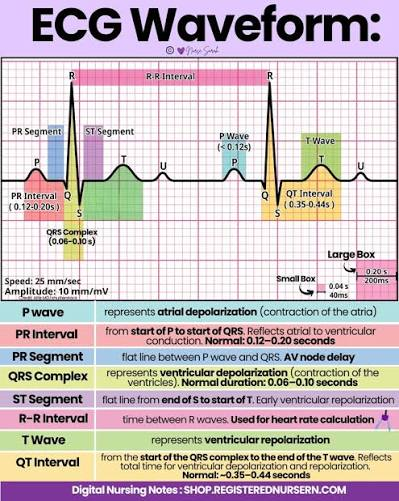

*Figure 1: Two consecutive heartbeats with each wave and interval labeled. Image: "ECG Waveform", Nurse Sarah, Digital Nursing Notes (registerednursern.com). [1]*

In Figure 1, the small bump before each spike is the **P wave**, the tall narrow spike (Q down, R up, S down) is the **QRS complex**, and the broader bump after it is the **T wave**. The pink bar at the top marks the **RR interval**: the time from one R peak to the next. This is the quantity the assignment's error criterion checks, so every detection in this notebook is judged by the RR intervals it produces.

Heart rate in beats per minute is 60 / RR. Finding every R wave is the first step of almost all ECG analysis.

**The problem.** These are **ambulatory** recordings: the person wore the recorder for two days while going about their life. When they move, the electrodes shift on the skin and the cables move, which adds **movement artifact**: large, slow swings that can be many times bigger than the ECG and can push the recorder to its limits (clipping). A detector that looks for "the biggest peaks" would find the artifact instead of the R waves.

**The idea.** The R wave is *fast*: most of the QRS complex's energy is above about 5 Hz (see "Why 250 Hz is enough" below). Movement artifact, breathing, and baseline wander are mostly *slow* (below about 5 to 10 Hz), and the T and P waves are also slower than the QRS. So a **bandpass filter** can keep the sharp QRS complexes and remove most of the artifact. Then a **peak detector** marks the R waves.

The same pipeline is used for all three recordings:

1. Load the recording and look at the whole 48 hours (overview).
2. Design a Butterworth bandpass filter. Its two cutoff frequencies are **tuned for each recording** by trying many pairs and keeping the one with the lowest error rate (Parts 1 to 4).
3. Filter the ECG forward and backward (`sosfiltfilt`) so the filtered R waves line up exactly with the original ones.
4. Detect the R waves with an adaptive threshold plus a rule that a beat cannot follow the previous beat much sooner than the recent rhythm allows (Parts 5 and 6).
5. Score the detections with the assignment's interval error criterion, and plot the RR intervals and two 10-second examples (Parts 7 to 10).

The design decisions and their rationale are written out in full under Recording 1. Recordings 2 and 3 use the same method; only the tuned numbers change.

**Run time.** Each recording is 43.2 million samples. Trying 40 filters and 15 detector settings (listed below) over the full 48 hours takes about 3 to 4 minutes per recording, so the whole notebook takes roughly 10 to 15 minutes to run.

Each "run" in the tables below means: filter all 48 hours, detect the R waves, and score the detections with `get_ibi_filter_error`. The tuning happens in two steps for each recording: first the filter is chosen with the detector held fixed, then the detector is tuned with the chosen filter held fixed.

**What is tested for each recording**

| Step | Where | What is varied | Values tried | What is held fixed | Runs |
|---|---|---|---|---|---|
| 1. Filter tuning | Parts 1 and 2 | Low cutoff, f_lo | 5, 8, 10, 12, 15, 18, 20 Hz | Filter type: Butterworth bandpass, order 4, applied forward and backward (`sosfiltfilt`). Detector: alpha = 0.5, beta = 0.6. | 40 |
| | | High cutoff, f_hi | 20, 25, 30, 35, 40, 50 Hz | Bands narrower than 5 Hz are skipped (18 to 20 Hz and 20 to 20 Hz), so 7 × 6 − 2 = 40 filters. | |
| 2. Detector tuning | Parts 5 and 6 | alpha: threshold as a fraction of the typical beat height | 0.3, 0.4, 0.5, 0.6, 0.7 | The filter chosen in step 1, and the fixed detector settings in the next table. 5 × 3 = 15 settings. | 15 |
| | | beta: minimum spacing as a fraction of the typical RR interval | 0.5, 0.6, 0.7 | | |
| 3. Comparison | Part 6 | The pipeline | Unfiltered ECG with a simple detector; filtered ECG with a simple detector | The simple detector uses the same adaptive threshold (the chosen alpha) with a fixed 0.30 s spacing instead of the rhythm-based rule. | 2 |

There is **one detector** (an adaptive threshold followed by a rhythm-based spacing rule, described in Part 5). Only alpha and beta are tuned; its other settings are the same for every run and every recording:

| Fixed detector setting | Value | Meaning |
|---|---|---|
| Block length | 1 s | The envelope \|y\| is split into 1-s blocks and the maximum of each block is taken. |
| Running median of block maxima | 10 blocks (10 s) | Gives the typical beat height that the threshold (alpha × typical height) follows. |
| Minimum spacing between beats | 0.25 s (240 bpm) | No two beats are ever closer than this. |
| First-pass spacing | 0.30 s (200 bpm) | Used only for the rough first pass that estimates the typical RR interval. |
| Typical RR window | Running median of 31 intervals | The typical RR interval that beta multiplies. |
| R-wave search window | ±40 ms | Each mark is moved to the largest positive value of the filtered signal within this window (the R wave). |

## Loading the recordings

**Files.** Each recording comes as a `.npz` file (NumPy) and a `.mat` file (MATLAB). Both hold the same two variables: `ecg` (the samples) and `sample_rate`. `load_ecg` reads either one; the `.npz` is used here because it loads faster.

**Format.** All three recordings are sampled at **250 Hz** and are **43,200,000 samples** long, which is exactly **48 hours**. The values are in the recorder's own units (the files give no conversion to millivolts). They change in steps of 0.25 and range from −8192 to +8191.75: that is a 16-bit recorder (65,536 levels). Any sample at ±8191 or beyond is **clipped**: the true ECG was outside the recorder's range, so the real value is lost.

**Why 250 Hz is enough.** Most of the QRS complex's energy is between about 5 and 15 Hz ([3], [4], as summarized in [2]), and in these recordings the power of the clean ECG falls steeply above about 40 Hz (see the Part 2 spectra). The Nyquist frequency at 250 Hz is 125 Hz, so the band that matters for detecting R waves is well inside it. Diagnostic ECGs keep content up to 150 Hz for measuring fine waveform detail, but that detail isn't needed to locate the beats.

An R wave can only be located to the nearest sample (4 ms). The error criterion only flags an interval that is more than 25% away from its expected value (for a 1 s interval, more than 250 ms off), so timing errors from the sample spacing are far too small to cause errors by themselves.

## Why do we care about clipping?

**What clipping is.** The recorder can only store values from −8192 to +8191.75. When the true voltage goes beyond that range, which usually happens during a large movement, the recorder writes its limit value instead. The waveform gets a **flat top** (or flat bottom) at the limit, and the real ECG in those samples is **lost**. In this notebook, a sample counts as clipped if \|x\| ≥ 8191.

**Why it needs its own treatment.** Movement artifact and clipping both come from movement, but they are different problems:

| | Movement artifact | Clipping |
|---|---|---|
| What happens | A large, mostly slow signal is **added on top of** the ECG | The recorder's range is exceeded and the ECG is **replaced** by a constant limit value |
| Is the ECG still there? | Yes, buried under the artifact | No, those samples never captured it |
| Can a filter fix it? | Yes: the artifact is mostly below about 5 to 10 Hz, the QRS is above it, so a bandpass separates them | No: no filter can recover information that was never recorded |
| What it looks like | Big slow swings with the QRS spikes still riding on them | Flat lines at ±8192 with sudden jumps between them |

Because of this, an error in a clipped stretch says nothing about how good the filter is, while an error in an unclipped stretch does. Keeping track of clipping lets us tell these apart: errors the method *could have avoided* versus errors *no method could avoid*.

**Where clipping is used in this notebook.** Clipping never changes the filter, the detector, or the official error rate. It is only used to explain results and choose fair examples:

| Where | How clipping is used | Why |
|---|---|---|
| Overview (each recording) | The bottom panel shows the percentage of each minute that is clipped | Shows *when* the recorder hit its limits, so the errors in Part 7 can be traced back to those hours |
| Part 2 (filter rationale) | The "noisiest minutes" spectrum uses **unclipped minutes only** | Flat tops and sudden jumps are not real movement artifact; including them would distort the picture of where the artifact's energy lies, which is what the cutoff frequencies are based on |
| Part 7 (misdetection rate) | The error rate is also reported separately for intervals **with** and **without** clipped samples, and the hourly error plot shows the clipped percentage | Separates errors the filter could have fixed from errors caused by lost data |
| Parts 9 and 10 (10-s examples) | Both example segments must contain **no clipped samples** | Part 9 should show a truly clean ECG. Part 10 should show *movement artifact the filter can remove*; without this rule the "most artifact" segment would almost always be a clipped stretch with no visible ECG at all |
| After Part 10 (comparison plot) | The recorder limits are drawn when the segment reaches them | Shows that the worst segment of P01 fails *because* of clipping |

**How much clipping there is (results from the overview and Part 7):**

| Recording | Clipped samples | Minutes with any clipping | Error rate in intervals **with** clipping | Error rate in intervals **without** clipping | Official error rate (all intervals) |
|---|---|---|---|---|---|
| P01 | 0.174% | 9.5% | 43.8% | 1.59% | 2.14% |
| P02 | 0.013% | 4.6% | 34.0% | 2.23% | 2.28% |
| P03 | 0.131% | 5.5% | 47.5% | 1.02% | 1.41% |

Clipped samples are a tiny fraction of each recording, but the intervals that contain them are wrong 34 to 48% of the time, compared with 1 to 2.2% elsewhere. In P01 and P03, a large share of the remaining errors come from data that was never recorded, not from the filter or the detector.

**What is *not* done.** The official misdetection rate (Part 7) still includes every interval, clipped or not, exactly as the assignment defines it. The detector also does not skip clipped stretches. A possible improvement would be to detect such stretches automatically and exclude them as unreadable. ECG core laboratories label unreadable segments of long-term recordings, and detections there are discarded before scoring [5]. Clinical Holter segments are also graded by whether the QRS complexes can be identified at all [6]. Doing this here would change how the score is computed, so it is left as a question for Part 32.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import io

CLIP_LEVEL = 8191.0    # the recorder's output stops at -8192 and +8191.75: samples beyond +/-8191 are clipped


def load_ecg(file_name):
    """Load one ambulatory ECG recording from its .npz file (or the matching .mat file).

    Both files hold the same two variables:
      ecg         : the ECG samples (1-D array)
      sample_rate : samples per second (Hz)

    Returns
    -------
    x  : (N,) float array, the ECG samples (recorder units; the files give no scale)
    fs : sample rate in Hz
    """
    path = Path(file_name)
    if path.suffix == ".npz":
        data = np.load(path)
        x = np.asarray(data["ecg"], dtype=float).ravel()
        fs = float(data["sample_rate"])
    elif path.suffix == ".mat":
        data = io.loadmat(path)
        x = np.asarray(data["ecg"], dtype=float).ravel()           # MATLAB stores it as a 1 x N row
        fs = float(np.squeeze(data["sample_rate"]))
    else:
        raise ValueError(f"Expected a .npz or .mat file, got {file_name}")

    step = np.min(np.diff(np.unique(x[: int(60 * fs)])))          # smallest change between levels
    clipped = np.mean(np.abs(x) >= CLIP_LEVEL)
    print(f"{path.name}")
    print(f"  {len(x):,} samples at {fs:g} Hz = {len(x) / fs / 3600:.1f} hours")
    print(f"  values from {x.min():g} to {x.max():g} in steps of {step:g} (a 16-bit recorder: 65,536 levels x {step:g})")
    print(f"  {100 * clipped:.3f}% of samples are clipped (|x| >= {CLIP_LEVEL:g})")
    return x, fs


def minute_stats(x, fs):
    """Split the record into 1-minute blocks and return per-minute min, max, standard deviation, and clipped fraction."""
    n = int(60 * fs)
    blocks = x[: len(x) // n * n].reshape(-1, n)
    return dict(t_hours=(np.arange(len(blocks)) + 0.5) / 60,
                lo=blocks.min(axis=1), hi=blocks.max(axis=1), sd=blocks.std(axis=1),
                clip=np.mean(np.abs(blocks) >= CLIP_LEVEL, axis=1))


def plot_overview(x, fs, title):
    """Whole-record overview: the range of the signal in each minute, and how much of each minute is clipped.

    A clean ECG stays within a narrow band (roughly +/-1000 units here). Movement artifact makes the
    band much wider, and the worst artifact drives the recorder into its limits (clipping).
    """
    m = minute_stats(x, fs)
    fig, axes = plt.subplots(2, 1, figsize=(14, 6.5), sharex=True, gridspec_kw=dict(height_ratios=[3, 1]))
    ax = axes[0]
    ax.fill_between(m["t_hours"], m["lo"], m["hi"], color="C0", alpha=0.5, lw=0, label="Range (min to max) in each minute")
    ax.axhline(CLIP_LEVEL, color="C3", ls="--", lw=0.8, label="Recorder limits (clipping)")
    ax.axhline(-CLIP_LEVEL, color="C3", ls="--", lw=0.8)
    ax.set_ylabel("ECG (recorder units)")
    ax.set_title(f"{title}: overview of the whole {len(x) / fs / 3600:.0f}-hour recording")
    ax.legend(loc="lower right", fontsize=8)
    ax.grid(True, alpha=0.3)
    ax = axes[1]
    ax.plot(m["t_hours"], 100 * m["clip"], color="C3", lw=0.8)
    ax.set_ylabel("Clipped\n(% of minute)")
    ax.set_xlabel("Time from the start of the recording (hours)")
    ax.set_xlim(0, len(x) / fs / 3600)
    ax.xaxis.set_major_locator(plt.MultipleLocator(4))
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    print(f"Minutes with any clipping: {np.mean(m['clip'] > 0) * 100:.1f}% of the record; "
          f"minutes that are more than 10% clipped: {np.mean(m['clip'] > 0.1) * 100:.1f}%")

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import Markdown, display

# freqz for second-order sections is called freqz_sos in newer SciPy and sosfreqz in older SciPy
_freqz_sos = getattr(signal, "freqz_sos", None) or signal.sosfreqz


def design_filter(f_lo, f_hi, fs, order=4):
    """Butterworth bandpass filter, stored as second-order sections (SOS).

    order is the Butterworth order of each edge: butter(order, ...) for a bandpass has 2*order poles,
    'order' of them shaping the low edge and 'order' shaping the high edge.
    SOS = a cascade of 2nd-order (biquad) stages. It gives the same filter as one big (b, a) polynomial,
    but it is numerically safe; a high-order (b, a) bandpass with a narrow band can become unstable from rounding.
    """
    sos = signal.butter(order, [f_lo, f_hi], btype="bandpass", fs=fs, output="sos")
    return dict(sos=sos, f_lo=f_lo, f_hi=f_hi, order=order, fs=fs)


def apply_filter(filt, x):
    """Zero-phase filtering: run the filter forward, then backward (scipy.signal.sosfiltfilt).

    The backward pass undoes the delay of the forward pass, so the R waves in the filtered signal line up
    exactly with the R waves in the original. The price: the signal is filtered twice, so the
    effective magnitude response is |H(f)|^2 (see Part 4) and the effective impulse response is
    h[n] convolved with h[-n] (see Part 3).
    """
    return signal.sosfiltfilt(filt["sos"], x)


def freq_response(filt, n=2**14):
    """Frequency response of one pass, H(f), and of forward-backward filtering, |H(f)|^2."""
    f, H = _freqz_sos(filt["sos"], worN=n, fs=filt["fs"])
    once = np.abs(H)
    return f, once, once**2


def minus3db_edges(filt):
    """-3 dB band of the forward-backward response: where |H|^2 >= 10^(-3/20) = 0.708.

    One pass of a Butterworth filter is -3 dB (|H| = 0.708) at its design cutoffs, so after filtfilt the
    gain there is |H|^2 = 0.5 (-6 dB). The -3 dB points of what is actually applied lie slightly inside.
    """
    f, _, ff = freq_response(filt)
    above = np.flatnonzero(ff >= 10 ** (-3 / 20))
    return f[above[0]], f[above[-1]]


def filtfilt_impulse(filt, half_len_s=0.4):
    """Effective impulse response of forward-backward filtering: filter a unit impulse with sosfiltfilt.

    The impulse sits in the middle of a run of zeros, so the result is h_eff[n] for n = -M..M.
    """
    fs = filt["fs"]
    M = int(round(half_len_s * fs))
    d = np.zeros(2 * M + 1)
    d[M] = 1.0
    h_eff = signal.sosfiltfilt(filt["sos"], d, padtype=None)     # no padding: an exact impulse response
    n = np.arange(-M, M + 1)
    return n, h_eff


def describe_filter(filt, title):
    """Table of the filter's settings and of its gain at a few frequencies of interest."""
    f, once, ff = freq_response(filt)
    lo3, hi3 = minus3db_edges(filt)
    gain_db = lambda f0: 20 * np.log10(max(np.interp(f0, f, ff), 1e-12))
    show_db = lambda f0: "below -200 dB" if gain_db(f0) < -200 else f"{gain_db(f0):.1f} dB"
    rows = [
        ("Type", "Butterworth bandpass (maximally flat passband: no ripple)"),
        ("Order", f"{filt['order']} per edge ({2 * filt['order']} poles, {filt['sos'].shape[0]} second-order sections)"),
        ("Cutoff frequencies (one pass, -3 dB)", f"{filt['f_lo']:g} Hz and {filt['f_hi']:g} Hz"),
        ("How it is applied", "Forward and backward (`sosfiltfilt`): zero phase, magnitude response |H|²"),
        ("Effective order after filtfilt", f"{2 * filt['order']} per edge: {40 * filt['order']} dB per decade on each side"),
        ("-3 dB band after filtfilt", f"{lo3:.2f} to {hi3:.2f} Hz (slightly inside the design cutoffs)"),
        ("Gain at the design cutoffs after filtfilt", "-6.0 dB (one pass is -3 dB; twice is -6 dB)"),
    ]
    for f0, what in [(0.5, "breathing and slow baseline wander"), (2, "typical movement artifact"),
                     (5, "T waves and slower movement"), (60, "power-line hum"), (100, "muscle (EMG) noise")]:
        rows.append((f"Gain after filtfilt at {f0:g} Hz ({what})", show_db(f0)))
    table = "| Property | Value |\n|---|---|\n" + "\n".join(f"| {a} | {b} |" for a, b in rows)
    display(Markdown(f"**{title}: filter summary**\n\n" + table))


# ---------------------------------------------------------------- Part 2 (rationale): where is the energy?
def minute_psds(x, fs, minutes, nperseg=1024):
    """Average Welch PSD over a list of 1-minute blocks (each block has its mean removed)."""
    n = int(60 * fs)
    P = []
    for m in minutes:
        f, p = signal.welch(x[m * n:(m + 1) * n], fs, nperseg=nperseg, detrend="constant")
        P.append(p)
    return f, np.mean(P, axis=0)


def plot_spectra(x, fs, filt, title, frac=0.10):
    """PSD of the quietest minutes (ECG with little artifact) versus the noisiest unclipped minutes.

    The gap between the two curves shows which frequencies the movement artifact occupies.
    The filter's forward-backward response |H|^2 is drawn on top to show what is kept and what is removed.
    """
    n = int(60 * fs)
    blocks = x[: len(x) // n * n].reshape(-1, n)
    sd = blocks.std(axis=1)
    unclipped = np.flatnonzero(np.all(np.abs(blocks) < CLIP_LEVEL, axis=1))
    order = unclipped[np.argsort(sd[unclipped])]
    k = max(1, int(frac * len(order)))
    quiet, noisy = order[:k], order[-k:]
    f, P_quiet = minute_psds(x, fs, quiet)
    _, P_noisy = minute_psds(x, fs, noisy)
    fh, _, ff = freq_response(filt)

    fig, ax = plt.subplots(figsize=(13, 5))
    ax.semilogy(f, P_quiet, color="C0", label=f"Quietest {100 * frac:.0f}% of minutes ({k} min): mostly clean ECG")
    ax.semilogy(f, P_noisy, color="C3", label=f"Noisiest {100 * frac:.0f}% of unclipped minutes ({k} min): movement artifact")
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("PSD (units²/Hz)")
    ax.grid(True, which="both", alpha=0.3)
    ax.set_xlim(0, fs / 2)
    ax2 = ax.twinx()
    ax2.plot(fh, ff, color="k", lw=1.5, label="Filter |H(f)|² (filtfilt), right axis")
    ax2.set_ylim(0, 1.05)
    ax2.set_ylabel("Filter gain |H|²")
    ax2.axvspan(*minus3db_edges(filt), color="gold", alpha=0.15, lw=0, label="Band kept (-3 dB after filtfilt)")
    lines = ax.get_legend_handles_labels()
    lines2 = ax2.get_legend_handles_labels()
    ax.legend(lines[0] + lines2[0], lines[1] + lines2[1], fontsize=8, loc="upper right")
    ax.set_title(f"{title}: where the ECG and the movement artifact put their power")
    plt.tight_layout()
    plt.show()
    ratio_db = 10 * np.log10(P_noisy / P_quiet)
    for f0 in (1, 3, 5, 10, 15, 20, 30, 40):
        print(f"  {f0:>3g} Hz: noisy minutes have {ratio_db[np.argmin(np.abs(f - f0))]:5.1f} dB more power than quiet minutes")

def pick_minutes(x, fs, frac=0.10):
    """The quietest and noisiest unclipped minutes, chosen exactly as plot_spectra chooses them.

    Each minute's 'noise level' is its standard deviation. Minutes with any clipped sample are left out,
    the rest are sorted by standard deviation, and the bottom and top 10% are returned.
    """
    n = int(60 * fs)
    blocks = x[: len(x) // n * n].reshape(-1, n)
    sd = blocks.std(axis=1)
    clipped = np.any(np.abs(blocks) >= CLIP_LEVEL, axis=1)
    unclipped = np.flatnonzero(~clipped)
    order = unclipped[np.argsort(sd[unclipped])]
    k = max(1, int(frac * len(order)))
    return dict(sd=sd, clipped=clipped, quiet=order[:k], noisy=order[-k:], n=n)


def plot_minute_selection(x, fs, title, frac=0.10, show_s=10):
    """Where the quietest and noisiest minutes used in the Part 2 spectrum come from.

    (a) The standard deviation of every minute over the 48 hours, with the selected minutes colored.
    (b) and (c) 10 seconds of the raw ECG from a typical quiet minute and a typical noisy minute
        (the one with the median standard deviation in each group).
    """
    m = pick_minutes(x, fs, frac)
    sd, n = m["sd"], m["n"]
    t_h = (np.arange(len(sd)) + 0.5) / 60
    other = np.setdiff1d(np.flatnonzero(~m["clipped"]), np.concatenate([m["quiet"], m["noisy"]]))

    fig = plt.figure(figsize=(15, 9))
    ax = fig.add_subplot(2, 1, 1)
    ax.semilogy(t_h[other], sd[other], ".", ms=2, color="0.75", label="Other unclipped minutes (not used)")
    ax.semilogy(t_h[m["clipped"]], sd[m["clipped"]], "x", ms=3, color="k", alpha=0.5,
                label=f"Minutes with clipping (left out): {m['clipped'].sum()}")
    ax.semilogy(t_h[m["quiet"]], sd[m["quiet"]], ".", ms=4, color="C0",
                label=f"Quietest {100 * frac:.0f}% ({len(m['quiet'])} min): blue curve in the spectrum")
    ax.semilogy(t_h[m["noisy"]], sd[m["noisy"]], ".", ms=4, color="C3",
                label=f"Noisiest {100 * frac:.0f}% of unclipped ({len(m['noisy'])} min): red curve in the spectrum")
    ax.axhline(sd[m["quiet"]].max(), color="C0", ls="--", lw=0.8)
    ax.axhline(sd[m["noisy"]].min(), color="C3", ls="--", lw=0.8)
    ax.set_xlim(0, len(x) / fs / 3600)
    ax.xaxis.set_major_locator(plt.MultipleLocator(4))
    ax.set_xlabel("Time from the start of the recording (hours)")
    ax.set_ylabel("Standard deviation of the minute\n(recorder units, log scale)")
    ax.set_title(f"{title}: (a) where the quietest and noisiest minutes are (one dot per minute)")
    ax.legend(fontsize=8, loc="upper center", ncol=2, markerscale=3)
    ax.grid(True, which="both", alpha=0.3)

    for k, (group, color, name) in enumerate([(m["quiet"], "C0", "a typical QUIET minute"),
                                               (m["noisy"], "C3", "a typical NOISY minute")]):
        mid = group[np.argsort(sd[group])[len(group) // 2]]          # median minute of the group
        i0 = mid * n + (n - int(show_s * fs)) // 2                    # 10 s from the middle of that minute
        seg = x[i0:i0 + int(show_s * fs)]
        ax = fig.add_subplot(2, 2, 3 + k)
        ax.plot(np.arange(len(seg)) / fs, seg, color=color, lw=0.7)
        ax.set_xlabel(f"Time (s) from {hms(i0 / fs)} (hh:mm:ss into the recording)")
        ax.set_ylabel("Raw ECG (recorder units)")
        ax.set_title(f"({'bc'[k]}) Raw ECG from {name} (minute std = {sd[mid]:.0f})", fontsize=10)
        ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    for group, name in [(m["quiet"], "Quietest"), (m["noisy"], "Noisiest")]:
        hours = np.bincount((group // 60).astype(int), minlength=int(np.ceil(len(sd) / 60)))
        top = np.argsort(hours)[::-1][:5]
        print(f"{name} {100 * frac:.0f}%: minute std from {sd[group].min():.0f} to {sd[group].max():.0f}; "
              f"hours holding the most of them: " + ", ".join(f"hour {h} ({hours[h]} min)" for h in sorted(top)))
# ---------------------------------------------------------------- Part 3
def plot_impulse(filt, title):
    """Part 3: (a) impulse response of one forward pass (causal), (b) effective impulse response of filtfilt."""
    fs = filt["fs"]
    M = int(round(0.4 * fs))
    d = np.zeros(2 * M + 1)
    d[0] = 1.0
    h_once = signal.sosfilt(filt["sos"], d)
    n, h_eff = filtfilt_impulse(filt)
    # how far from the center you must go to hold 99% of the energy: grow a window |n| <= k until it does
    inside = np.array([np.sum(h_eff[np.abs(n) <= k] ** 2) for k in range(M + 1)]) / np.sum(h_eff**2)
    width = int(np.argmax(inside >= 0.99))

    fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
    ax = axes[0]
    ax.stem(np.arange(len(h_once)) / fs * 1000, h_once, basefmt="k-", markerfmt=".", linefmt="C0-")
    ax.set_xlim(-20, 400)
    ax.set_xlabel("Time after the impulse (ms)")
    ax.set_ylabel("h[n]")
    ax.set_title("(a) One forward pass (causal: starts at n = 0, delayed, not symmetric)")
    ax.grid(True, alpha=0.3)
    ax = axes[1]
    ax.stem(n / fs * 1000, h_eff, basefmt="k-", markerfmt=".", linefmt="C2-")
    ax.axvspan(-width / fs * 1000, width / fs * 1000, color="gold", alpha=0.2, lw=0,
               label=f"99% of the energy within ±{width / fs * 1000:.0f} ms")
    ax.set_xlim(-400, 400)
    ax.set_xlabel("Time from the impulse (ms)")
    ax.set_ylabel("h_eff[n]")
    ax.set_title("(b) Forward + backward (filtfilt): what is actually applied\nnon-causal, symmetric, centered at 0 (zero phase)")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    fig.suptitle(f"{title}: impulse response of the {filt['f_lo']:g} to {filt['f_hi']:g} Hz Butterworth bandpass "
                 f"(order {filt['order']}, fs = {fs:g} Hz)", fontsize=11)
    plt.tight_layout()
    plt.show()
    print(f"Peak of h_eff at n = {n[np.argmax(np.abs(h_eff))]} (zero delay). "
          f"Symmetric: max |h_eff[n] - h_eff[-n]| = {np.max(np.abs(h_eff - h_eff[::-1])):.1e}. "
          f"Sum of h_eff = {h_eff.sum():.1e} (a bandpass has zero gain at 0 Hz, so its taps sum to 0).")


# ---------------------------------------------------------------- Part 4
def plot_magnitude(filt, title):
    """Part 4: magnitude response. Because filtfilt filters twice, the correct curve is |H|^2 (dB doubled)."""
    fs = filt["fs"]
    f, once, ff = freq_response(filt)
    lo3, hi3 = minus3db_edges(filt)
    db = lambda a: 20 * np.log10(np.maximum(a, 1e-12))

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    ax = axes[0]
    ax.plot(f, db(once), "C0--", lw=1, label="One pass |H(f)| (NOT what filtfilt applies)")
    ax.plot(f, db(ff), "C2", lw=2, label="filtfilt |H(f)|² (what is applied)")
    ax.axhline(-3, color="gray", ls=":", lw=0.8)
    ax.axhline(-6, color="gray", ls=":", lw=0.8)
    ax.text(fs / 2 * 0.98, -3, "-3 dB", ha="right", va="bottom", fontsize=8, color="gray")
    ax.text(fs / 2 * 0.98, -6, "-6 dB", ha="right", va="top", fontsize=8, color="gray")
    for fc in (filt["f_lo"], filt["f_hi"]):
        ax.axvline(fc, color="C0", ls="--", lw=0.6)
    ax.axvline(60, color="C3", ls=":", lw=1, label="60 Hz power line")
    ax.set_ylim(-100, 5)
    ax.set_xlim(0, fs / 2)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("Gain (dB)")
    ax.set_title("(a) Gain in dB, 0 Hz to fs/2")
    ax.legend(fontsize=8, loc="lower center")
    ax.grid(True, alpha=0.3)

    ax = axes[1]
    ax.plot(f, once, "C0--", lw=1, label="One pass |H(f)|")
    ax.plot(f, ff, "C2", lw=2, label="filtfilt |H(f)|²")
    ax.axhline(10 ** (-3 / 20), color="gray", ls=":", lw=0.8)
    ax.axhline(0.5, color="gray", ls=":", lw=0.8)
    ax.text(0.5, 10 ** (-3 / 20), " -3 dB (0.708)", va="bottom", fontsize=8, color="gray")
    ax.text(0.5, 0.5, " -6 dB (0.5)", va="bottom", fontsize=8, color="gray")
    ax.axvspan(lo3, hi3, color="gold", alpha=0.2, lw=0, label=f"-3 dB band of filtfilt: {lo3:.1f} to {hi3:.1f} Hz")
    ax.set_xlim(0, min(fs / 2, 2.5 * filt["f_hi"]))
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("Gain (linear)")
    ax.set_title("(b) Linear gain, zoomed on the passband")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    fig.suptitle(f"{title}: magnitude response (Butterworth bandpass {filt['f_lo']:g} to {filt['f_hi']:g} Hz, "
                 f"order {filt['order']}, applied with filtfilt)", fontsize=11)
    plt.tight_layout()
    plt.show()

In [3]:
import bisect
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal, ndimage


# ---------------------------------------------------------------- performance criterion (given in the assignment)
def get_ibi_filter_error(i_r_peaks, sample_rate: float, interval_floor: float = 0.5,
                         acceptable_ibi_variation: float = 0.25) -> float:
    ibi = np.diff(i_r_peaks) / sample_rate                       # Inter-beat intervals (IBI) in seconds
    ibi_mf = signal.medfilt(ibi, kernel_size=9)                  # Median filtered IBI
    if interval_floor is not None:
        ibi_mf = np.where(ibi_mf < interval_floor, interval_floor, ibi_mf)
    error_threshold = acceptable_ibi_variation * ibi_mf
    e_mf = np.mean(np.abs(ibi - ibi_mf) > error_threshold)
    return e_mf


def interval_errors(i_r_peaks, sample_rate, interval_floor=0.5, acceptable_ibi_variation=0.25):
    """Same math as get_ibi_filter_error, but returns every intermediate array (for the plots).

    Returns a dict:
      t       : time of each interval (s), taken as the time of the beat that ends it
      ibi     : the intervals between detected beats (s)
      ibi_mf  : 9-point median-filtered intervals, floored at interval_floor (s)
      is_err  : True where |ibi - ibi_mf| > acceptable_ibi_variation * ibi_mf
      rate    : mean(is_err), identical to get_ibi_filter_error
    """
    ibi = np.diff(i_r_peaks) / sample_rate
    ibi_mf = signal.medfilt(ibi, kernel_size=9)
    if interval_floor is not None:
        ibi_mf = np.where(ibi_mf < interval_floor, interval_floor, ibi_mf)
    is_err = np.abs(ibi - ibi_mf) > acceptable_ibi_variation * ibi_mf
    return dict(t=np.asarray(i_r_peaks[1:]) / sample_rate, ibi=ibi, ibi_mf=ibi_mf, is_err=is_err,
                rate=is_err.mean())


# ---------------------------------------------------------------- R-wave detector
DETECTOR_DEFAULTS = dict(alpha=0.5, beta=0.6, rr_min=0.25, refr_pre=0.30, n_rr=31, block_s=1.0, win_blocks=10,
                         r_search=0.04)


def adaptive_threshold(env, fs, alpha, block_s=1.0, win_blocks=10):
    """Threshold that follows the size of the QRS complexes as it changes over the 48 hours.

    1. Split the envelope into 1-s blocks and take the maximum of each block. Most 1-s blocks
       contain one QRS complex, so a block maximum is usually the height of one beat.
    2. Take a running median of those maxima over 10 blocks (10 s). The median ignores a few blocks
       with no beat (very slow heart rate) or with one large artifact spike.
    3. The threshold is alpha times that typical beat height.

    Returns the threshold for every block (one value per second) and the block length in samples.
    """
    B = int(round(block_s * fs))
    nb = int(np.ceil(len(env) / B))
    padded = np.concatenate([env, np.zeros(nb * B - len(env))])
    block_max = padded.reshape(nb, B).max(axis=1)
    typical = ndimage.median_filter(block_max, size=win_blocks, mode="nearest")
    return alpha * typical, B


def expand_blocks(per_block, B, n):
    """Turn one value per block into one value per sample."""
    return np.repeat(per_block, B)[:n]


def detect_r_peaks(y, fs, alpha=0.5, beta=0.6, rr_min=0.25, refr_pre=0.30, n_rr=31, block_s=1.0, win_blocks=10,
                   r_search=0.04):
    """Find the R waves in the band-passed ECG y.

    Step 1, envelope:   env = |y|. After the bandpass filter the QRS complex is the largest, sharpest
                        part of each beat, in either polarity, so its absolute value stands out.
    Step 2, threshold:  thr = alpha x (running median of the 1-s maxima of env), see adaptive_threshold.
    Step 3, candidates: every local maximum of env above thr, at least rr_min (0.25 s = 240 bpm) apart.
    Step 4, rhythm:     a quick first pass (fixed 0.30 s spacing) gives a rough beat train; a running median
                        of n_rr = 31 of its intervals gives the typical RR interval near every point in time.
    Step 5, selection:  go through the candidates from tallest to shortest and keep a candidate only if
                        no beat already kept is closer than max(rr_min, beta x typical RR).
                        So the tallest peak in each neighborhood wins, and a T wave or noise spike that
                        follows a beat too soon (sooner than 60% of the usual RR when beta = 0.6) is dropped.
    Step 6, R wave:     move each mark to the largest positive value of y within 40 ms (the R wave itself).

    Returns a dict with the beat locations (sample indices), the candidates, and the threshold per block.
    """
    env = np.abs(y)
    thr_block, B = adaptive_threshold(env, fs, alpha, block_s, win_blocks)
    thr = expand_blocks(thr_block, B, len(env))

    cand, props = signal.find_peaks(env, height=thr, distance=max(1, int(round(rr_min * fs))))
    heights = props["peak_heights"]

    pre, _ = signal.find_peaks(env, height=thr, distance=int(round(refr_pre * fs)))
    rr_typ = ndimage.median_filter(np.diff(pre) / fs, size=n_rr, mode="nearest")
    rr_at_cand = np.interp(cand, pre[1:], rr_typ)                 # typical RR near each candidate (s)
    min_gap = np.maximum(rr_min, beta * rr_at_cand) * fs          # required spacing (samples)

    kept = []                                                     # sorted list of kept beat locations
    for i in np.argsort(-heights):                                # tallest candidate first
        c, g = cand[i], min_gap[i]
        j = bisect.bisect_left(kept, c)
        if j > 0 and c - kept[j - 1] < g:
            continue                                              # too close to a taller beat on the left
        if j < len(kept) and kept[j] - c < g:
            continue                                              # too close to a taller beat on the right
        kept.insert(j, c)
    qrs = np.array(kept, dtype=int)

    # Step 6: |y| often peaks at the deep S wave rather than the R wave. Move each mark to the largest
    # POSITIVE value of y within +/- r_search (40 ms) of it: the R wave of that QRS complex.
    w = int(round(r_search * fs))
    idx = np.clip(qrs[:, None] + np.arange(-w, w + 1)[None, :], 0, len(y) - 1)
    peaks = idx[np.arange(len(qrs)), np.argmax(y[idx], axis=1)]

    return dict(peaks=peaks, qrs=qrs, cand=cand, thr_block=thr_block, B=B, fs=fs,
                alpha=alpha, beta=beta, rr_min=rr_min, refr_pre=refr_pre, n_rr=n_rr,
                block_s=block_s, win_blocks=win_blocks, r_search=r_search)


def simple_detector(y, fs, alpha=0.5, refractory=0.30):
    """The simplest version, for comparison: adaptive threshold + a fixed 0.30 s refractory period."""
    env = np.abs(y)
    thr_block, B = adaptive_threshold(env, fs, alpha)
    peaks, _ = signal.find_peaks(env, height=expand_blocks(thr_block, B, len(env)),
                                 distance=int(round(refractory * fs)))
    return peaks

In [4]:
import time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

F_LO_GRID = [5, 8, 10, 12, 15, 18, 20]       # candidate low cutoffs (Hz)
F_HI_GRID = [20, 25, 30, 35, 40, 50]         # candidate high cutoffs (Hz)
ALPHA_GRID = [0.3, 0.4, 0.5, 0.6, 0.7]       # candidate threshold fractions
BETA_GRID = [0.5, 0.6, 0.7]                  # candidate minimum-spacing fractions of the typical RR

"""
def tune_filter(x, fs, title, order=4, f_los=F_LO_GRID, f_his=F_HI_GRID, **detector):
    #Step 1 of the tuning: try every (f_lo, f_hi) pair with the default detector and keep the lowest error.

    #Every pair is scored with the assignment's criterion (get_ibi_filter_error) over the whole 48 hours.

    det = {**DETECTOR_DEFAULTS, **detector}
    err = np.full((len(f_los), len(f_his)), np.nan)
    t0 = time.time()
    for i, lo in enumerate(f_los):
        for j, hi in enumerate(f_his):
            if hi < lo + 5:                       # keep at least a 5 Hz wide band
                continue
            y = apply_filter(design_filter(lo, hi, fs, order), x)
            err[i, j] = get_ibi_filter_error(detect_r_peaks(y, fs, **det)["peaks"], fs)
    i, j = np.unravel_index(np.nanargmin(err), err.shape)
    print(f"{title}: tried {np.isfinite(err).sum()} filters in {time.time() - t0:.0f} s. "
          f"Best: {f_los[i]} to {f_his[j]} Hz, error rate {100 * err[i, j]:.2f}%")
    return dict(err=err, f_los=list(f_los), f_his=list(f_his), best=(f_los[i], f_his[j]), order=order, det=det)
"""

def tune_filter(x, fs, title, order=4, f_los=F_LO_GRID, f_his=F_HI_GRID, verbose=True, **detector):
    """Step 1 of the tuning: try every (f_lo, f_hi) pair with the default detector and keep the lowest error.

    Every pair is scored with the assignment's criterion (get_ibi_filter_error) over the whole 48 hours.
    verbose=True prints each pair's result as it is computed, then the 5 best pairs.
    """
    det = {**DETECTOR_DEFAULTS, **detector}
    err = np.full((len(f_los), len(f_his)), np.nan)
    t0 = time.time()
    if verbose:
        print(f"{title}: Butterworth bandpass, order {order}, filtfilt; detector alpha = {det['alpha']}, beta = {det['beta']}")
        print(f"  {'Run':>4}  {'f_lo (Hz)':>9}  {'f_hi (Hz)':>9}  {'Error rate':>10}")
    run = 0
    for i, lo in enumerate(f_los):
        for j, hi in enumerate(f_his):
            if hi < lo + 5:                       # keep at least a 5 Hz wide band
                if verbose:
                    print(f"  {'':>4}  {lo:>9g}  {hi:>9g}  {'skipped (band narrower than 5 Hz)'}")
                continue
            y = apply_filter(design_filter(lo, hi, fs, order), x)
            err[i, j] = get_ibi_filter_error(detect_r_peaks(y, fs, **det)["peaks"], fs)
            run += 1
            if verbose:
                print(f"  {run:>4}  {lo:>9g}  {hi:>9g}  {100 * err[i, j]:>9.2f}%")
    i, j = np.unravel_index(np.nanargmin(err), err.shape)
    if verbose:
        order_idx = np.argsort(err, axis=None)[:5]            # NaN (skipped) pairs sort last
        print(f"\n  5 lowest error rates:")
        for rank, k in enumerate(order_idx, 1):
            a, b = np.unravel_index(k, err.shape)
            print(f"    {rank}. {f_los[a]:g} to {f_his[b]:g} Hz: {100 * err[a, b]:.2f}%")
        print()
    print(f"{title}: tried {np.isfinite(err).sum()} filters in {time.time() - t0:.0f} s. "
          f"Best: {f_los[i]} to {f_his[j]} Hz, error rate {100 * err[i, j]:.2f}%")
    return dict(err=err, f_los=list(f_los), f_his=list(f_his), best=(f_los[i], f_his[j]), order=order, det=det)

def plot_filter_tuning(tune, title):
    """Heat map of the error rate (%) for every (f_lo, f_hi) pair tried. The chosen pair is outlined."""
    err = 100 * tune["err"]
    fig, ax = plt.subplots(figsize=(8, 5.5))
    im = ax.imshow(err, cmap="viridis_r", aspect="auto", origin="lower")
    for (i, j), v in np.ndenumerate(err):
        if np.isfinite(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if v > np.nanmedian(err) else "black")
    bi, bj = tune["f_los"].index(tune["best"][0]), tune["f_his"].index(tune["best"][1])
    ax.add_patch(plt.Rectangle((bj - 0.5, bi - 0.5), 1, 1, fill=False, ec="red", lw=2.5))
    ax.set_xticks(range(len(tune["f_his"])), [f"{v:g}" for v in tune["f_his"]])
    ax.set_yticks(range(len(tune["f_los"])), [f"{v:g}" for v in tune["f_los"]])
    ax.set_xlabel("High cutoff f_hi (Hz)")
    ax.set_ylabel("Low cutoff f_lo (Hz)")
    fig.colorbar(im, ax=ax, label="Interval error rate (%)")
    ax.set_title(f"{title}: error rate for each bandpass (order {tune['order']}, "
                 f"detector alpha = {tune['det']['alpha']}, beta = {tune['det']['beta']})\n"
                 f"blank = band narrower than 5 Hz (not tried); red box = chosen", fontsize=10)
    plt.tight_layout()
    plt.show()


def tune_detector(y, fs, title, alphas=ALPHA_GRID, betas=BETA_GRID):
    """Step 2 of the tuning: with the chosen filter, try every (alpha, beta) pair and keep the lowest error."""
    err = np.zeros((len(alphas), len(betas)))
    t0 = time.time()
    for i, a in enumerate(alphas):
        for j, b in enumerate(betas):
            err[i, j] = get_ibi_filter_error(detect_r_peaks(y, fs, alpha=a, beta=b)["peaks"], fs)
    i, j = np.unravel_index(np.argmin(err), err.shape)
    print(f"{title}: tried {err.size} detector settings in {time.time() - t0:.0f} s. "
          f"Best: alpha = {alphas[i]}, beta = {betas[j]}, error rate {100 * err[i, j]:.2f}%")
    return dict(err=err, alphas=list(alphas), betas=list(betas), best=(alphas[i], betas[j]))


def plot_detector_tuning(dtune, title):
    """Error rate (%) versus the threshold fraction alpha, one line per spacing fraction beta."""
    fig, ax = plt.subplots(figsize=(9, 4.5))
    for j, b in enumerate(dtune["betas"]):
        ax.plot(dtune["alphas"], 100 * dtune["err"][:, j], "o-", label=f"beta = {b}")
    a, b = dtune["best"]
    ax.plot(a, 100 * dtune["err"][dtune["alphas"].index(a), dtune["betas"].index(b)], "r*", ms=16,
            label=f"chosen: alpha = {a}, beta = {b}")
    ax.set_xlabel("alpha (threshold as a fraction of the typical beat height)")
    ax.set_ylabel("Interval error rate (%)")
    ax.set_title(f"{title}: detector tuning (with the chosen filter)")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

import matplotlib


def plot_detector_heatmap(dtune, title):
    """Heat map of the error rate (%) for every (alpha, beta) pair tried. The chosen pair is outlined.

    Same layout as plot_filter_tuning (Part 2), so the two tuning steps can be read the same way.
    """
    err = 100 * dtune["err"]
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    # log color scale: one very bad row (alpha = 0.3) would otherwise wash out the differences in the rest
    im = ax.imshow(err, cmap="viridis_r", aspect="auto", origin="lower",
                   norm=matplotlib.colors.LogNorm(vmin=err.min(), vmax=err.max()))
    for (i, j), v in np.ndenumerate(err):
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9,
                color="white" if im.norm(v) > 0.5 else "black")          # white text on dark cells
    bi, bj = dtune["alphas"].index(dtune["best"][0]), dtune["betas"].index(dtune["best"][1])
    ax.add_patch(plt.Rectangle((bj - 0.5, bi - 0.5), 1, 1, fill=False, ec="red", lw=2.5))
    ax.set_xticks(range(len(dtune["betas"])), [f"{v:g}" for v in dtune["betas"]])
    ax.set_yticks(range(len(dtune["alphas"])), [f"{v:g}" for v in dtune["alphas"]])
    ax.set_xlabel("beta (minimum spacing as a fraction of the typical RR interval)")
    ax.set_ylabel("alpha (threshold as a fraction of\nthe typical beat height)")
    cb = fig.colorbar(im, ax=ax, label="Interval error rate (%), log scale")
    ticks = [t for t in (1, 1.5, 2, 3, 5, 10, 20, 50) if err.min() <= t <= err.max()]
    cb.set_ticks(ticks, labels=[f"{t:g}" for t in ticks])
    cb.ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
    ax.set_title(f"{title}: error rate for each detector setting (with the chosen filter)\n"
                 f"red box = chosen: alpha = {dtune['best'][0]}, beta = {dtune['best'][1]}", fontsize=10)
    plt.tight_layout()
    plt.show()

def compare_steps(x, y, fs, det, title):
    """How much each piece of the design helps: error rate as pieces are added one at a time."""
    rows = [
        ("Unfiltered ECG, simple detector (fixed 0.30 s refractory)", simple_detector(x - np.median(x), fs, det["alpha"])),
        ("Filtered ECG, simple detector (fixed 0.30 s refractory)", simple_detector(y, fs, det["alpha"])),
        ("Filtered ECG, full detector (spacing follows the rhythm)", det["peaks"]),
    ]
    lines = ["| Pipeline | Beats found | Interval error rate |", "|---|---|---|"]
    for name, pk in rows:
        lines.append(f"| {name} | {len(pk):,} | {100 * get_ibi_filter_error(pk, fs):.2f}% |")
    display(Markdown(f"**{title}: what each step contributes**\n\n" + "\n".join(lines)))

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import Markdown, display


def hms(seconds):
    """Seconds -> 'hh:mm:ss' (time from the start of the recording)."""
    s = int(round(seconds))
    return f"{s // 3600:02d}:{s % 3600 // 60:02d}:{s % 60:02d}"


def clipped_intervals(peaks, x):
    """True for every interval (between consecutive beats) that contains at least one clipped sample."""
    c = np.concatenate([[0], np.cumsum(np.abs(x) >= CLIP_LEVEL)])
    return (c[peaks[1:] + 1] - c[peaks[:-1]]) > 0


# ---------------------------------------------------------------- Part 7
def report_error(det, x, fs, title):
    """Part 7: the misdetection rate from the assignment's criterion, plus where the errors happen."""
    peaks = det["peaks"]
    ie = interval_errors(peaks, fs)
    rate = get_ibi_filter_error(peaks, fs)                       # the official number
    clip = clipped_intervals(peaks, x)
    hours = len(x) / fs / 3600
    # errors that disappear without the floor: the interval is within 25% of its own (un-floored) median,
    # and is flagged only because the median was raised to 0.5 s (a real heart rate above about 160 bpm)
    raw_mf = signal.medfilt(ie["ibi"], kernel_size=9)
    floor_only = ie["is_err"] & (raw_mf < 0.5) & (np.abs(ie["ibi"] - raw_mf) <= 0.25 * raw_mf)
    rows = [
        ("Beats detected", f"{len(peaks):,} (average {len(peaks) / (hours * 60):.1f} per minute)"),
        ("Intervals checked", f"{len(ie['ibi']):,}"),
        ("Intervals flagged as errors", f"{ie['is_err'].sum():,}"),
        ("**Misdetection (interval error) rate**", f"**{100 * rate:.2f}%**"),
        ("Intervals that contain clipped samples", f"{clip.sum():,} ({100 * clip.mean():.2f}% of intervals)"),
        ("Error rate in intervals with clipping", f"{100 * ie['is_err'][clip].mean():.1f}%" if clip.any() else "n/a"),
        ("Error rate in intervals without clipping", f"{100 * ie['is_err'][~clip].mean():.2f}%"),
        ("Errors caused only by the 0.5 s floor (see note below)",
         f"{floor_only.sum():,} ({100 * floor_only.sum() / max(ie['is_err'].sum(), 1):.0f}% of the errors; "
         f"{100 * floor_only.mean():.2f} percentage points of the rate)"),
    ]
    display(Markdown(f"**{title}: misdetection rate**\n\n| Quantity | Value |\n|---|---|\n"
                     + "\n".join(f"| {a} | {b} |" for a, b in rows)))

    # where the errors are: error rate in each hour, next to how much of that hour is clipped
    h = (ie["t"] // 3600).astype(int)
    nh = int(np.ceil(hours))
    per_hour = np.bincount(h, weights=ie["is_err"], minlength=nh) / np.maximum(np.bincount(h, minlength=nh), 1)
    n = int(3600 * fs)
    clip_hour = [np.mean(np.abs(x[k * n:(k + 1) * n]) >= CLIP_LEVEL) for k in range(nh)]
    fig, ax = plt.subplots(figsize=(14, 3.8))
    ax.bar(np.arange(nh) + 0.5, 100 * per_hour, width=0.9, color="C0", label="Interval error rate in that hour")
    ax.axhline(100 * rate, color="k", ls="--", lw=1, label=f"Whole record: {100 * rate:.2f}%")
    ax.set_xlabel("Hour of the recording")
    ax.set_ylabel("Error rate (%)")
    ax.set_xlim(0, nh)
    ax.grid(True, alpha=0.3)
    ax2 = ax.twinx()
    ax2.plot(np.arange(nh) + 0.5, 100 * np.array(clip_hour), "C3.-", lw=1, label="Clipped samples in that hour (right axis)")
    ax2.set_ylabel("Clipped (%)", color="C3")
    l1, l2 = ax.get_legend_handles_labels(), ax2.get_legend_handles_labels()
    ax.legend(l1[0] + l2[0], l1[1] + l2[1], fontsize=8, loc="upper center")
    ax.set_title(f"{title}: where the interval errors happen")
    plt.tight_layout()
    plt.show()
    worst = np.argsort(per_hour * np.bincount(h, minlength=nh))[::-1][: max(1, nh // 10)]
    share = ie["is_err"][np.isin(h, worst)].sum() / max(ie["is_err"].sum(), 1)
    print("Note: the criterion raises the median interval to at least 0.5 s. When the heart really beats faster "
          "than about 160 bpm, correct detections can still be flagged. The row above counts intervals that are "
          "within 25% of their own median but are flagged only because of this floor.")
    print(f"The {len(worst)} hours with the most errors (hours {', '.join(str(k) for k in sorted(worst))}) "
          f"hold {100 * share:.0f}% of all the error intervals.")
    return ie


# ---------------------------------------------------------------- Part 8
def busiest_window(ie, length_s, want="errors"):
    """Start time of the window (length_s long) with the most error intervals, or with none ('clean')."""
    t_end = ie["t"][-1]
    starts = np.arange(0, t_end - length_s, length_s / 2)
    idx = np.searchsorted(ie["t"], starts)
    idx2 = np.searchsorted(ie["t"], starts + length_s)
    c = np.concatenate([[0], np.cumsum(ie["is_err"])])
    n_err = c[idx2] - c[idx]
    if want == "errors":
        # the most errors, among windows where at least half of the intervals are still correct
        ok = (n_err <= 0.5 * (idx2 - idx)) & (idx2 - idx > 0)
        return starts[np.argmax(np.where(ok, n_err, -1))]
    # 'clean': no errors, median not held at the 0.5 s floor, and the steadiest intervals (smallest std / mean)
    ibi, floored = ie["ibi"], ie["ibi_mf"] <= 0.5
    spread = np.array([ibi[a:b].std() / ibi[a:b].mean() if b - a > 10 and not floored[a:b].any() else np.inf
                       for a, b in zip(idx, idx2)])
    spread[n_err > 0] = np.inf
    return starts[np.argmin(spread)] if np.isfinite(spread).any() else starts[0]


def plot_rr(ie, title, zoom_s=120):
    """Part 8: RR intervals and their 9-point median filter. Whole record, then two 2-minute zooms."""
    t_h = ie["t"] / 3600
    fig = plt.figure(figsize=(15, 9))
    ax = fig.add_subplot(2, 1, 1)
    ax.plot(t_h, ie["ibi"], ".", ms=1, color="C0", alpha=0.4, label="RR interval of each detected beat")
    ax.plot(t_h, ie["ibi_mf"], "-", lw=0.6, color="k", label="Median-filtered RR (9 beats, floor 0.5 s)")
    e = ie["is_err"]
    ax.plot(t_h[e], ie["ibi"][e], ".", ms=2, color="C3", label=f"Flagged as error ({e.sum():,} of {len(e):,})")
    ax.set_ylim(0, 2.5)
    ax.set_xlim(0, t_h[-1])
    ax.xaxis.set_major_locator(plt.MultipleLocator(4))
    ax.set_xlabel("Time from the start of the recording (hours)")
    ax.set_ylabel("RR interval (s)")
    ax.set_title(f"{title}: (a) RR intervals over the whole recording (y-axis cut at 2.5 s)")
    ax.legend(fontsize=8, loc="upper right", markerscale=6)
    ax.grid(True, alpha=0.3)

    for k, (want, name) in enumerate([("clean", "a clean stretch"), ("errors", "a stretch with many errors")]):
        t0 = busiest_window(ie, zoom_s, want)
        m = (ie["t"] >= t0) & (ie["t"] < t0 + zoom_s)
        ax = fig.add_subplot(2, 2, 3 + k)
        tt = ie["t"][m] - t0
        ax.fill_between(tt, 0.75 * ie["ibi_mf"][m], 1.25 * ie["ibi_mf"][m], step="mid", color="gray", alpha=0.25,
                        label="Accepted band: median ± 25%")
        ax.plot(tt, ie["ibi"][m], "o-", ms=3, lw=0.8, color="C0", label="RR interval")
        ax.step(tt, ie["ibi_mf"][m], where="mid", color="k", lw=1, label="Median-filtered RR")
        ax.plot(tt[ie["is_err"][m]], ie["ibi"][m][ie["is_err"][m]], "o", ms=6, mfc="none", mec="C3", mew=1.5,
                label=f"Error ({ie['is_err'][m].sum()})")
        ax.set_xlabel(f"Time (s) from {hms(t0)} (hh:mm:ss into the recording)")
        ax.set_ylabel("RR interval (s)")
        ax.set_title(f"({'bc'[k]}) Zoom: {zoom_s} s of {name}", fontsize=10)
        ax.legend(fontsize=7)
        ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    hr = 60 / ie["ibi_mf"]
    print(f"Heart rate from the median-filtered RR: median {np.median(hr):.0f} bpm, "
          f"5th to 95th percentile {np.percentile(hr, 5):.0f} to {np.percentile(hr, 95):.0f} bpm")


# ---------------------------------------------------------------- Parts 9 and 10
def segment_table(x, y, fs, det, ie, seg_s=10.0):
    """Score every 10-s segment of the record (back to back), to pick the examples for Parts 9 and 10.

    artifact : standard deviation of what the filter removed (x - y), relative to the size of the
               QRS complexes in the filtered signal. Big = the movement artifact dwarfs the ECG.
    n_err    : number of interval errors that end inside the segment.
    clipped  : True if any sample in the segment hit the recorder's limits.
    """
    n = int(round(seg_s * fs))
    K = len(x) // n
    removed = (x[: K * n] - y[: K * n]).reshape(K, n)
    clipped = np.any(np.abs(x[: K * n].reshape(K, n)) >= CLIP_LEVEL, axis=1)
    qrs = expand_blocks(det["thr_block"], det["B"], len(x))[: K * n].reshape(K, n).mean(axis=1) / det["alpha"]
    seg_of_beat = det["peaks"] // n
    n_beats = np.bincount(seg_of_beat, minlength=K)[:K]
    n_err = np.bincount(seg_of_beat[1:][ie["is_err"]], minlength=K)[:K]
    return dict(n=n, artifact=removed.std(axis=1) / np.maximum(qrs, 1e-9), clipped=clipped,
                n_beats=n_beats, n_err=n_err)


def pick_segment(seg, ie, kind):
    """Start (sample index) of the example segment.

    'clean'    : no clipping, no errors, and the least artifact of all segments.
    'artifact' : no clipping, no errors (the detector still works), and the MOST artifact.
    'failure'  : the segment with the most flagged interval errors (for discussion).
    """
    expected = 10.0 / np.median(ie["ibi_mf"])                     # beats expected in 10 s
    usable = (~seg["clipped"]) & (seg["n_err"] == 0) & (seg["n_beats"] >= 0.8 * expected)
    if kind == "clean":
        k = np.flatnonzero(usable)[np.argmin(seg["artifact"][usable])]
    elif kind == "artifact":
        k = np.flatnonzero(usable)[np.argmax(seg["artifact"][usable])]
    else:
        k = int(np.argmax(seg["n_err"] + 1e-3 * seg["artifact"]))
    return k * seg["n"]                                            # start, in samples


def plot_segment(x, y, fs, det, ie, start, title, label):
    """Original ECG (top) and filtered ECG (bottom) over a 10-s segment, with the detected R waves marked."""
    n = int(round(10 * fs))
    i0, i1 = int(start), int(start) + n
    t = np.arange(i0, i1) / fs - i0 / fs
    pk = det["peaks"][(det["peaks"] >= i0) & (det["peaks"] < i1)]
    thr = expand_blocks(det["thr_block"], det["B"], len(x))[i0:i1]
    err_beats = det["peaks"][1:][ie["is_err"]]
    pk_err = pk[np.isin(pk, err_beats)]

    fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True)
    ax = axes[0]
    ax.plot(t, x[i0:i1], color="0.35", lw=0.8, label="Original ECG")
    ax.plot((pk - i0) / fs, x[pk], "v", color="C3", ms=8, label=f"Detected R waves ({len(pk)})")
    if len(pk_err):
        ax.plot((pk_err - i0) / fs, x[pk_err], "o", ms=13, mfc="none", mec="C1", mew=2,
                label="Beat that ends an error interval")
    if np.any(np.abs(x[i0:i1]) >= CLIP_LEVEL):
        ax.axhline(CLIP_LEVEL, color="C3", ls=":", lw=0.8)
        ax.axhline(-CLIP_LEVEL, color="C3", ls=":", lw=0.8, label="Recorder limits (clipping)")
    lo, hi = ax.get_ylim()
    ax.set_ylim(lo, hi + 0.3 * (hi - lo))                           # headroom so the legend clears the markers
    ax.set_ylabel("Original (recorder units)")
    ax.set_title(f"{title}: {label}\n10 s starting {hms(i0 / fs)} (hh:mm:ss) into the recording", fontsize=11)
    ax.legend(fontsize=8, loc="upper center", ncol=4)
    ax.grid(True, alpha=0.3)
    ax = axes[1]
    ax.plot(t, y[i0:i1], color="C0", lw=0.8, label="Filtered ECG")
    ax.plot(t, thr, "k--", lw=0.8, label=f"Detection threshold ±(alpha × typical beat height), alpha = {det['alpha']}")
    ax.plot(t, -thr, "k--", lw=0.8)
    ax.plot((pk - i0) / fs, y[pk], "v", color="C3", ms=8, label="Detected R waves")
    ax.set_xlabel("Time (s) from the start of the segment")
    ax.set_ylabel("Filtered (recorder units)")
    lo, hi = ax.get_ylim()
    ax.set_ylim(lo, hi + 0.3 * (hi - lo))
    ax.legend(fontsize=8, loc="upper center", ncol=3)
    ax.grid(True, alpha=0.3)
    ax.set_xlim(0, 10)
    plt.tight_layout()
    plt.show()
    rr = np.diff(pk) / fs
    if len(rr):
        print(f"RR intervals in this segment: {np.round(rr, 2)} s; interval errors here: {len(pk_err)}")

## The performance criterion, explained

There is no "answer key" (no gold-standard list of true R waves), so the assignment uses the fact that the heart rhythm changes slowly from beat to beat.

**Intervals: the time between beats.**

The detector's output is a list of **sample numbers**: the positions in the recording where it marked an R wave. The recording has 250 samples per second, so samples are 4 ms apart, and dividing a sample number by 250 gives its time in seconds. The **interval** (also called the RR interval or inter-beat interval) is the time from one detected beat to the next. N detected beats give N − 1 intervals.

*Example.* Below are 14 detections from 12 seconds of ECG. The heart is beating about once per second, but at 6.30 s the detector wrongly marked a T wave (detection 8):

| Detection | Sample number | Time (s) = sample ÷ 250 | Interval from the previous detection (s) |
|---|---|---|---|
| 1 | 0 | 0.00 | (none: first beat) |
| 2 | 250 | 1.00 | 1.00 |
| 3 | 505 | 2.02 | 1.02 |
| 4 | 755 | 3.02 | 1.00 |
| 5 | 1005 | 4.02 | 1.00 |
| 6 | 1255 | 5.02 | 1.00 |
| 7 | 1500 | 6.00 | 0.98 |
| **8 (T wave, false)** | **1575** | **6.30** | **0.30** |
| 9 | 1752 | 7.01 | **0.71** |
| 10 | 2000 | 8.00 | 0.99 |
| 11 | 2250 | 9.00 | 1.00 |
| 12 | 2497 | 9.99 | 0.99 |
| 13 | 2750 | 11.00 | 1.01 |
| 14 | 3000 | 12.00 | 1.00 |

The one false detection split a normal 1-second interval into two wrong ones: 0.30 s and 0.71 s.

**Expected interval: what each interval "should" have been.**

There is no answer key, so we can't know the true interval. But the heart rhythm changes slowly, so the intervals *around* any interval are a good estimate of what it should have been. For each interval:

1. Take a **window of 9 intervals** centered on it: the interval itself, the 4 before it, and the 4 after it.
2. **Sort** those 9 values from smallest to largest.
3. Take the **middle one** (the 5th of 9). This is the **median**, and it is the *expected interval*.
4. Slide the window over by one interval and repeat, so every interval gets its own expected value.

*Example, for the 0.30 s interval:*

- Its window of 9 intervals: 1.00, 1.00, 1.00, 0.98, **0.30**, 0.71, 0.99, 1.00, 0.99
- Sorted: 0.30, 0.71, 0.98, 0.99, **0.99**, 1.00, 1.00, 1.00, 1.00
- Median (5th value): **0.99 s**, which is the true rhythm.

**Why the median and not the average.** The two bad intervals (0.30 and 0.71) end up at the bottom of the sorted list, so they can't move the middle value. The average of the same 9 values is 0.89 s, pulled down by the two bad values. Compared against 0.89 s, the bad 0.71 s interval would be only 20% off and would pass as "normal". The median ignores up to 4 wrong values out of 9, so it stays on the true rhythm as long as most nearby detections are correct.

**Why a sliding window.** Because the window moves along one interval at a time, the expected interval follows the heart rate as it slowly changes (for example, from about 1.2 s during sleep to about 0.5 s during exercise). A gradual change in heart rate is therefore never counted as an error; only sudden jumps are.

*Each interval next to its expected value (this is what Steps 3 and 4 then check):*

| Interval (s) | 1.00 | 1.02 | 1.00 | 1.00 | 1.00 | 0.98 | **0.30** | **0.71** | 0.99 | 1.00 | 0.99 | 1.01 | 1.00 |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Expected (s) | 1.00 | 1.00 | 1.00 | 1.00 | 1.00 | 1.00 | 0.99 | 0.99 | 0.99 | 0.99 | 0.99 | 0.99 | 0.99 |
| Difference | 0% | 2% | 0% | 0% | 0% | 2% | **70%** | **29%** | 0% | 1% | 0% | 2% | 1% |

Only the two intervals touching the false detection differ by more than 25%, so 2 of the 13 intervals are flagged as errors.

*Note on the ends of the recording:* the first and last 4 intervals don't have 4 neighbors on one side, so the median filter fills the missing spots with zeros. This affects 8 intervals out of roughly 160,000 to 250,000 per recording, so it has no effect on the results.

**Floor.** The expected interval is never allowed below 0.5 s (120 bpm). Without this, a burst of false detections (noise every 0.2 s, say) would make the *median* itself short, and the false detections would look "normal".
**Error test.** An interval is an error if it differs from the expected interval by more than 25% of the expected interval.
**Error rate.** The fraction of intervals that are errors.

**Why this approximates the misdetection rate.** With a steady rhythm of 1 s:

| What the detector did | Intervals produced | Intervals flagged |
|---|---|---|
| Found every beat | 1.0, 1.0, 1.0 | 0 |
| **Missed** one beat (false negative) | 1.0, **2.0**, 1.0 | 1 (2.0 is 100% too long) |
| Added one noise detection halfway between two beats (false positive) | 1.0, **0.5**, **0.5**, 1.0 | 2 (each 0.5 is 50% too short) |
| Marked a T wave 0.3 s after an R wave (false positive) | 1.0, **0.3**, **0.7**, 1.0 | 2 |

So each missed beat costs about one error and each false beat about two. The error rate is therefore roughly (number of mistakes) / (number of beats).

**What it cannot see.**

- It can't tell *which* peak is the R wave; it only checks that the spacing is consistent.
- A detector that locks onto something regular but wrong (for example, a periodic noise source) would score well.
- A real, sudden change in rhythm (an early or "skipped" beat, which happens in healthy people too) is counted as an error even if the detection was perfect.
- Because of the 0.5 s floor, any true heart rate above about 160 bpm (intervals under 0.375 s) is always counted as an error.
- In stretches where the ECG is completely lost (clipped), every interval there counts, so how many detections a method makes in those stretches changes the score. Part 7 therefore also reports the error rate in intervals with and without clipping.

# Recording 1: `P01_ecg.npz`

### Overview of the whole recording

P01_ecg.npz
  43,200,000 samples at 250 Hz = 48.0 hours
  values from -8192 to 8191.75 in steps of 0.25 (a 16-bit recorder: 65,536 levels x 0.25)
  0.174% of samples are clipped (|x| >= 8191)


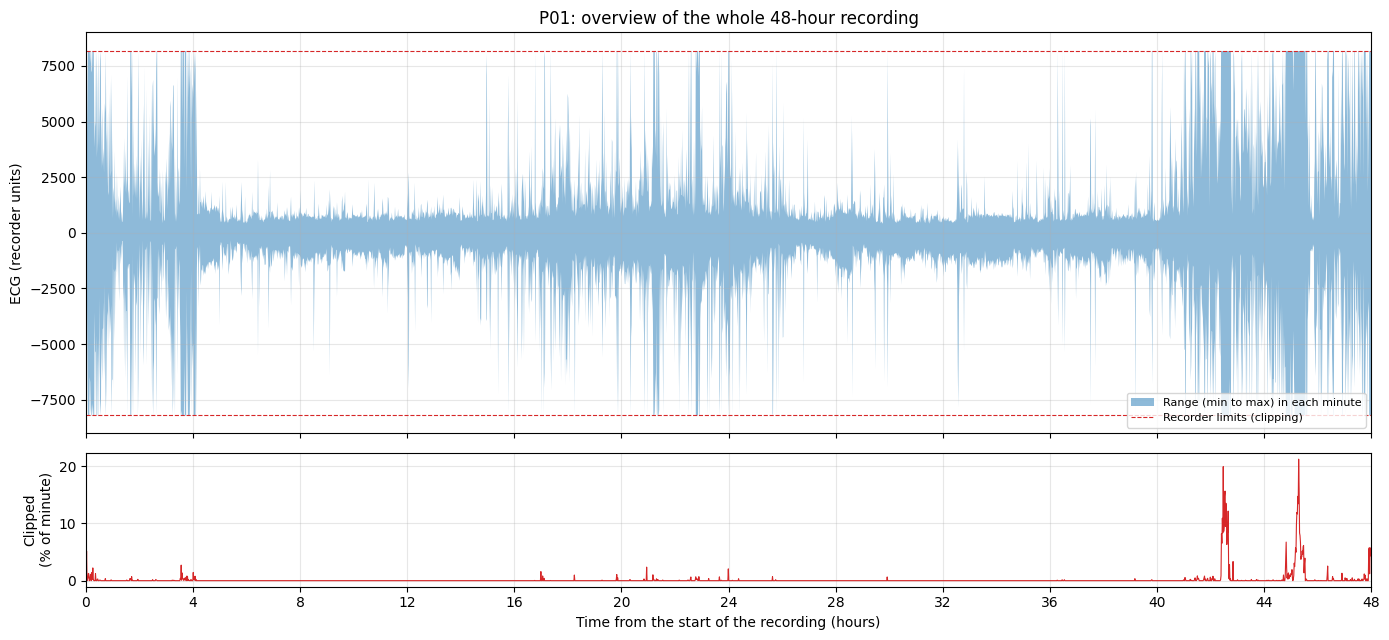

Minutes with any clipping: 9.5% of the record; minutes that are more than 10% clipped: 0.5%


In [6]:
x1, fs1 = load_ecg("P01_ecg.npz")
plot_overview(x1, fs1, "P01")

### How to read the overview

- **Top panel.** Each minute of the recording is shrunk to a vertical bar from its smallest to its largest sample. A clean ECG makes a narrow band (the QRS complexes set its height). Movement artifact makes the band much taller. Where the band reaches the red dashed lines, the recorder was clipping.
- **Bottom panel.** The percentage of samples in each minute that are clipped. Clipped samples are lost information: no filter can recover an R wave that the recorder never captured.
- This plot also shows *when* the person was active (tall bands) and resting or asleep (narrow bands), which helps explain where the detector makes its mistakes (Part 7).

**P01 is the noisiest of the three recordings.** About 9.5% of its minutes contain at least one clipped sample. The worst stretches are the first 4 hours and hours 41 to 47, where up to about 20% of a minute is clipped. From about hour 5 to hour 40 the band is mostly narrow (the person was mostly still), with bursts of activity around hours 15 to 26.

## Part 1: Description of your filter

P01: Butterworth bandpass, order 4, filtfilt; detector alpha = 0.5, beta = 0.6
   Run  f_lo (Hz)  f_hi (Hz)  Error rate
     1          5         20      16.78%
     2          5         25      16.42%
     3          5         30      16.29%
     4          5         35      14.68%
     5          5         40      12.56%
     6          5         50       9.91%
     7          8         20       8.83%
     8          8         25       9.47%
     9          8         30       9.25%
    10          8         35       7.49%
    11          8         40       5.80%
    12          8         50       4.39%
    13         10         20       6.59%
    14         10         25       7.14%
    15         10         30       6.77%
    16         10         35       5.02%
    17         10         40       3.87%
    18         10         50       3.20%
    19         12         20       5.79%
    20         12         25       6.09%
    21         12         30       5.62%
    22         12  

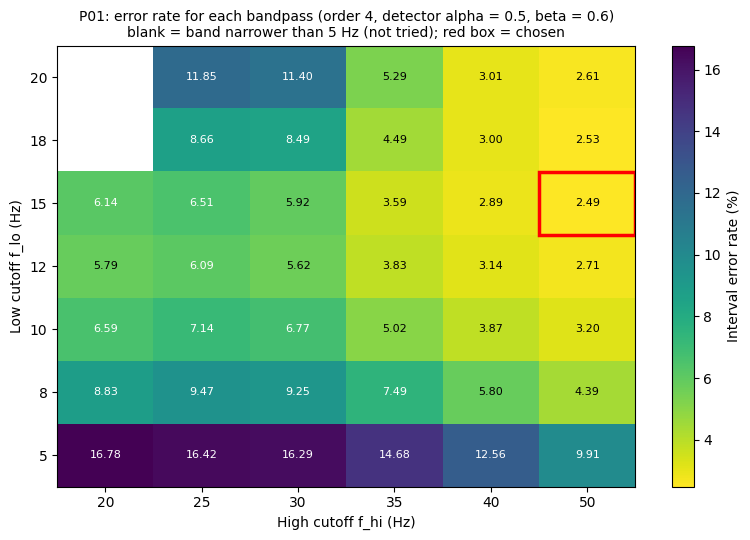

**P01: filter summary**

| Property | Value |
|---|---|
| Type | Butterworth bandpass (maximally flat passband: no ripple) |
| Order | 4 per edge (8 poles, 4 second-order sections) |
| Cutoff frequencies (one pass, -3 dB) | 15 Hz and 50 Hz |
| How it is applied | Forward and backward (`sosfiltfilt`): zero phase, magnitude response |H|² |
| Effective order after filtfilt | 8 per edge: 160 dB per decade on each side |
| -3 dB band after filtfilt | 15.95 to 47.66 Hz (slightly inside the design cutoffs) |
| Gain at the design cutoffs after filtfilt | -6.0 dB (one pass is -3 dB; twice is -6 dB) |
| Gain after filtfilt at 0.5 Hz (breathing and slow baseline wander) | below -200 dB |
| Gain after filtfilt at 2 Hz (typical movement artifact) | -161.7 dB |
| Gain after filtfilt at 5 Hz (T waves and slower movement) | -96.2 dB |
| Gain after filtfilt at 60 Hz (power-line hum) | -27.5 dB |
| Gain after filtfilt at 100 Hz (muscle (EMG) noise) | -120.5 dB |

In [7]:
tune1 = tune_filter(x1, fs1, "P01")
filt1 = design_filter(*tune1["best"], fs1, order=tune1["order"])
plot_filter_tuning(tune1, "P01")
describe_filter(filt1, "P01")

**A 4th-order Butterworth bandpass filter from 15 to 50 Hz, built as second-order sections and applied forward and backward with `sosfiltfilt` (zero phase).**

In plain words: it keeps the fast, sharp QRS complexes and removes everything slower than about 15 Hz (movement artifact, breathing, baseline wander, P and T waves) and everything faster than about 50 Hz (muscle noise; the 60 Hz power-line hum is reduced by 27.5 dB). Because it is applied twice, the gain actually applied is |H|²: it is −6 dB at 15 and 50 Hz, −3 dB at 15.95 and 47.66 Hz, and the edges fall at 160 dB per decade. It does not delay or distort the timing of the R waves.

## Part 2: Description of how you designed your filter including the rationale for your design decisions and parameter values

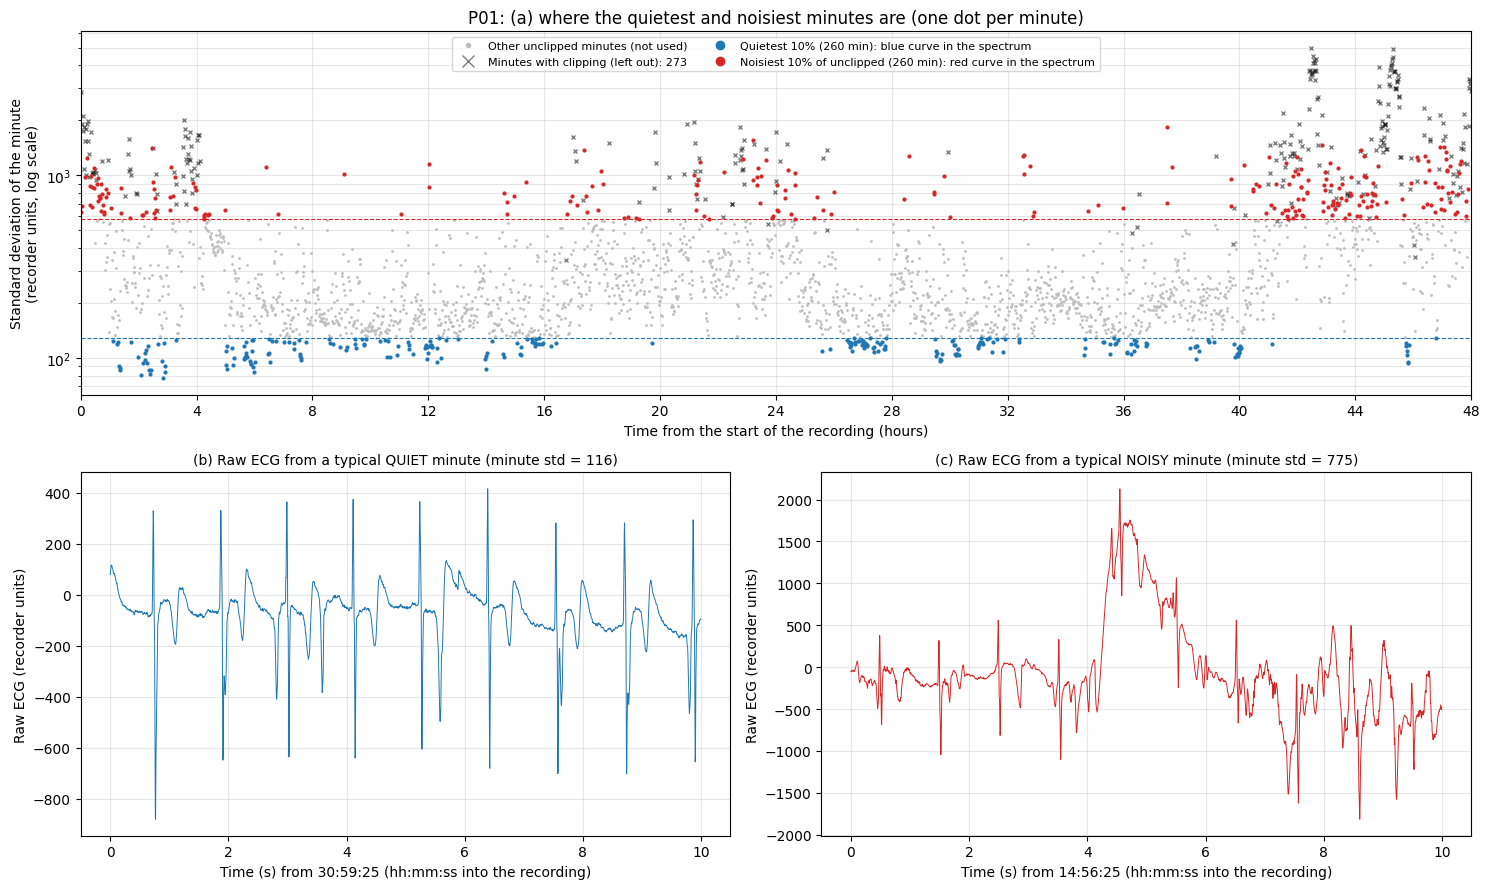

Quietest 10%: minute std from 77 to 128; hours holding the most of them: hour 2 (16 min), hour 5 (23 min), hour 15 (16 min), hour 26 (17 min), hour 27 (20 min)
Noisiest 10%: minute std from 577 to 1840; hours holding the most of them: hour 0 (26 min), hour 42 (19 min), hour 43 (20 min), hour 44 (20 min), hour 47 (20 min)


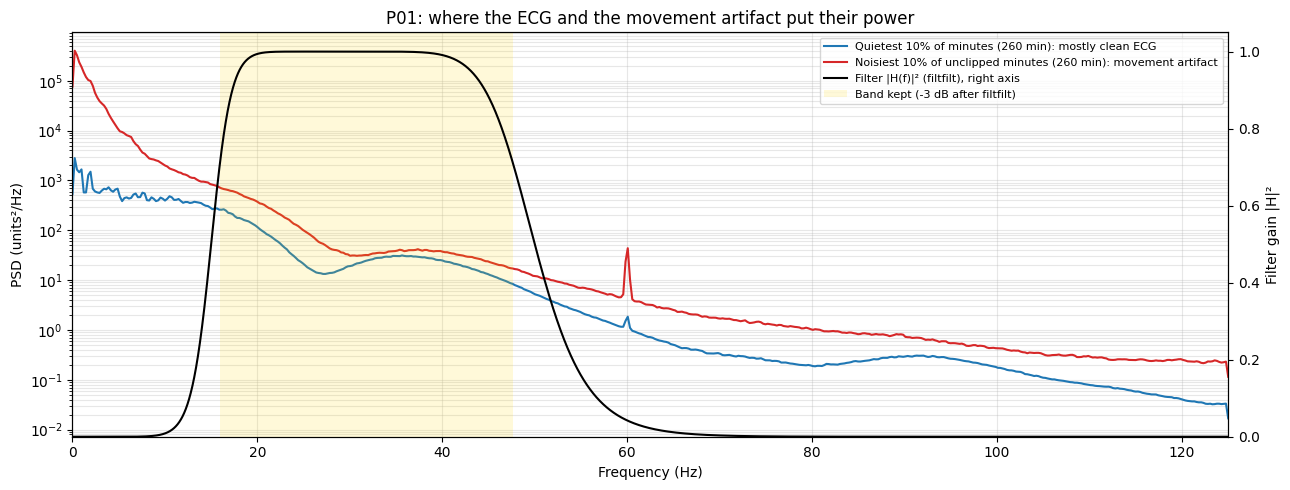

    1 Hz: noisy minutes have  20.6 dB more power than quiet minutes
    3 Hz: noisy minutes have  18.4 dB more power than quiet minutes
    5 Hz: noisy minutes have  12.1 dB more power than quiet minutes
   10 Hz: noisy minutes have   7.0 dB more power than quiet minutes
   15 Hz: noisy minutes have   4.7 dB more power than quiet minutes
   20 Hz: noisy minutes have   5.1 dB more power than quiet minutes
   30 Hz: noisy minutes have   2.1 dB more power than quiet minutes
   40 Hz: noisy minutes have   1.8 dB more power than quiet minutes


In [8]:
plot_minute_selection(x1, fs1, "P01")
plot_spectra(x1, fs1, filt1, "P01")

### How to read the spectrum plot

A **power spectral density (PSD)** sorts a signal's power by frequency. The y-axis is logarithmic (each grid line is a factor of 10).

- **Blue:** the average PSD of the quietest 10% of minutes (lowest standard deviation). These minutes are mostly clean ECG: the person was still.
- **Red:** the average PSD of the noisiest 10% of minutes that are *not* clipped. These have the same ECG plus a lot of movement artifact.
- **The gap between red and blue** is the artifact. The printed numbers give the gap at a few frequencies. The gap is largest at low frequencies and shrinks as frequency rises: movement is slow, the QRS is fast.
- **Black curve (right axis):** the filter's gain |H(f)|² as it is actually applied (filtfilt). The yellow band is where that gain is within 3 dB of 1; outside it, the signal is removed.

The filter's job is to keep the band where the ECG is strong *relative to* the artifact, and remove everything else.

### Why the gap between the two curves decides the filter band

**What the detector needs.** After filtering, the detector looks for peaks that stand out above everything else. A beat is found reliably only if its QRS complex is clearly bigger than whatever else is left in the filtered signal. So for detection, the **signal** is the QRS complex, and the **noise** is everything else that gets through the filter: movement artifact, muscle noise, power-line hum, and also the T and P waves.

**What a filter can and cannot do.** A filter does not "recognize" the ECG. It only keeps or removes **frequencies**. At any frequency it keeps, it keeps *both* the ECG and the artifact at that frequency; at any frequency it removes, it removes both. So the only choice the filter makes is *which frequencies to keep*, and the question for each frequency is: **if I keep this frequency, do I gain more ECG than artifact?**

**Reading that answer off the plot.** The quiet minutes (blue) are close to ECG alone. The noisy minutes (red) are the same kind of ECG *plus* movement artifact. Their difference at each frequency therefore estimates how much artifact there is compared with ECG at that frequency. Converting the printed gaps for P01 (if the noisy curve is *G* dB above the quiet curve, the artifact has about 10^(*G*/10) − 1 times the ECG's power):

| Frequency | Gap (noisy − quiet) | Artifact power compared with ECG power | Keep this frequency? |
|---|---|---|---|
| 1 Hz | 20.6 dB | about 110× | No: almost all artifact |
| 3 Hz | 18.4 dB | about 70× | No |
| 5 Hz | 12.1 dB | about 15× | No |
| 10 Hz | 7.0 dB | about 4× | Borderline |
| 15 Hz | 4.7 dB | about 2× | Borderline (but this is where the QRS starts to have power) |
| 20 Hz | 5.1 dB | about 2× | Yes, because the QRS has a lot of power here |
| 30 Hz | 2.1 dB | about 0.6× | Yes: more ECG than artifact |
| 40 Hz | 1.8 dB | about 0.5× | Yes |

(This treats the artifact as adding to the ECG, and assumes the ECG in noisy minutes looks like the ECG in quiet minutes. It is an estimate, not an exact separation.)

At 1 to 5 Hz, keeping those frequencies would let in 15 to 110 times more artifact than ECG, and that is exactly where the big baseline swings in the raw signal come from. Above about 15 Hz the two are comparable, and above about 25 Hz the ECG wins. **A small gap means "the ECG dominates here: keep it"; a large gap means "the artifact dominates here: remove it."**

**Why not just keep only the frequencies with the smallest gap?** Because the filter also has to keep *enough* of the QRS. A frequency where neither curve has much power (for example, above 60 Hz) adds almost nothing to the QRS peaks but still lets in muscle noise and hum. A frequency with a moderate gap but lots of QRS power (15 to 20 Hz for P01) can be worth keeping, because it makes the QRS peaks taller. The best band balances the two:

- **Wider band:** taller, sharper QRS peaks, but more artifact and noise gets through.
- **Narrower band:** less artifact, but the QRS peaks shrink and their shape smears, until real beats fall under the threshold.

The spectrum shows *why* the cutoffs should be roughly where they are; the tuning heat map below finds *exactly* where that balance gives the fewest detection errors. For P01 the two agree: the gap is large below about 10 Hz, and the tuning chose a low cutoff of 15 Hz.

**Why the T wave is removed too, even though it is part of the ECG.** The quiet curve includes the whole heartbeat, including the slow P and T waves (mostly below about 10 Hz). For *detection*, a large T wave is just another peak that could be mistaken for a beat, so removing those low frequencies helps twice: it removes the movement artifact and it shrinks the T waves, leaving the QRS as the only big peak in each beat.

### How the cutoff frequencies were chosen (tuning)

The assignment asks us to optimize the filter with the error criterion, so the cutoffs were not guessed: every pair from

- low cutoff f_lo = 5, 8, 10, 12, 15, 18, 20 Hz, and
- high cutoff f_hi = 20, 25, 30, 35, 40, 50 Hz (keeping the band at least 5 Hz wide)

was used to filter the full 48 hours, the R waves were detected with the default detector settings (alpha = 0.5, beta = 0.6), and the error rate was computed. The pair with the lowest error rate is outlined in red. Each cell of the heat map is one complete run of the pipeline.

The tuning is done in two steps: first the filter (with the detector fixed), then the detector (with the filter fixed, Part 6). Tuning everything at once would mean 40 × 15 = 600 runs per recording, roughly 40 minutes each, for very little gain.

### Filter design decisions

| Decision | Choice | Why |
|---|---|---|
| Filter shape | **Bandpass** | Movement artifact, breathing, and baseline wander are slow (low frequency); muscle noise and power-line hum are fast (high frequency). The QRS complex sits in between. One filter removes both ends. |
| Filter family | **Butterworth (IIR)** | Its passband is maximally flat (no ripple), so it does not add bumps to the QRS shape. It has only three settings (two cutoffs and an order), so it is easy to tune and explain. An FIR filter with an equally sharp low edge would need hundreds of taps; an order-4 Butterworth bandpass needs 8 poles. |
| How it is applied | **Forward and backward (`sosfiltfilt`)** | An IIR filter delays different frequencies by different amounts (non-linear phase), which smears and shifts the QRS. Running the filter backward over the output cancels the phase exactly (zero phase), so the filtered R waves line up with the original R waves. This only works offline (on a recording), which is our case. |
| Representation | **Second-order sections (SOS)** | A narrow bandpass written as one polynomial (`b`, `a`) has coefficients that are very sensitive to rounding and can go unstable. A cascade of 2nd-order sections is the numerically safe form of the same filter. |
| Order | **4** (8 poles, 4 sections) | In a separate check (not shown), orders 2 and 4 gave almost the same error rates. Order 4 is steeper (24 dB per octave per pass, 48 dB per octave after filtfilt) without the long ringing of a high-order filter. |
| Low cutoff f_lo | **Tuned per recording** | Must be high enough to remove the movement artifact *and* the T waves (a large T wave that passes the filter can be mistaken for a beat), but low enough to keep the QRS. |
| High cutoff f_hi | **Tuned per recording** | Must be high enough to keep the sharp tip of the QRS, but low enough to remove muscle (EMG) noise and, where present, the 60 Hz power-line hum. |
| Separate filter per recording | **Yes** (allowed by the assignment) | The three people's QRS shapes, electrode placements, and noise differ, and the tuning finds different best bands for each. |

**The 15 to 50 Hz band had the lowest error rate of the 40 bands tried (2.49% with the default detector).**

- **Low cutoff (15 Hz).** The spectrum shows that the noisy minutes have 18 to 21 dB more power than the quiet minutes at 1 to 3 Hz, 12 dB more at 5 Hz, but only about 5 dB more at 15 to 20 Hz: below about 10 Hz the artifact dominates. In the heat map, raising f_lo from 5 Hz to 15 Hz lowers the error from 10 to 17% to 2.5 to 6%. Going higher (18 to 20 Hz) helps only when f_hi is also high, and hurts when the band gets narrow, because it starts removing the QRS itself.
- **High cutoff (50 Hz).** For P01, a higher f_hi is better in every row. P01's QRS is very narrow and sharp (see Part 9: a thin spike followed by a deep S wave), and its clean-ECG spectrum has a broad bump of energy from about 30 to 45 Hz. A 25 or 30 Hz cutoff removes much of that, so the QRS no longer stands out from the noise.
- **Why P01's band differs from the others.** P01's T waves and slow artifact extend higher in frequency, so it needs a higher f_lo than P03, and its sharp QRS needs a higher f_hi than P02 and P03.

## Part 3: Plot of the impulse response of your filter

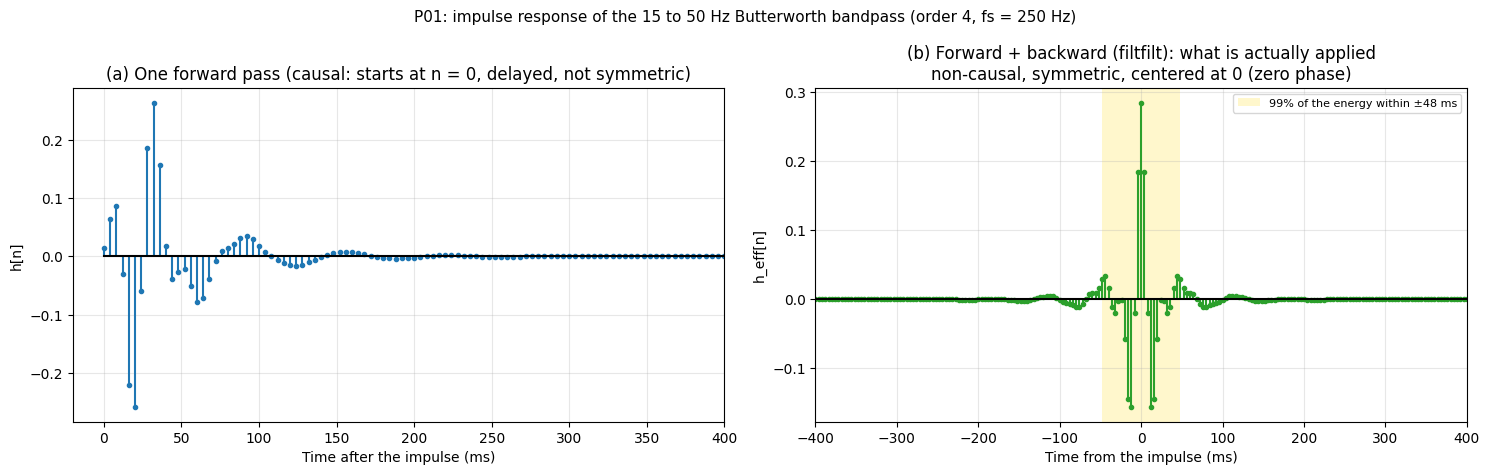

Peak of h_eff at n = 0 (zero delay). Symmetric: max |h_eff[n] - h_eff[-n]| = 1.8e-05. Sum of h_eff = 2.5e-05 (a bandpass has zero gain at 0 Hz, so its taps sum to 0).


In [9]:
plot_impulse(filt1, "P01")

### How to read the impulse response

The impulse response is the filter's output when the input is a single 1 at n = 0 and zeros everywhere else. Every output sample is a weighted sum of the input samples around it, and these are the weights.

- **(a) One forward pass** (`sosfilt`). An IIR filter's impulse response never exactly ends, but it dies out quickly. It is **causal**: it starts at n = 0 and the output is delayed relative to the input.
- **(b) Forward and backward** (`sosfiltfilt`), which is what is actually applied. Filtering forward and then backward is the same as convolving with h[n] and then with h[−n], so the effective impulse response is **h_eff[n] = h[n] ∗ h[−n]**. It is **symmetric** (h_eff[−n] = h_eff[n]) and centered at n = 0, which is exactly why the filter has zero phase and no delay. It is **non-causal**: it uses future samples, which is fine for a recording.
- It was computed by passing a unit impulse through `sosfiltfilt` itself, so it is exactly what the code applies.
- **The oscillation** is at roughly the center of the passband: the filter responds to a "wiggle" of about that frequency, which is what a QRS complex looks like.
- **The taps sum to zero** because a bandpass has zero gain at 0 Hz (DC). This is why the filter removes any slow offset or drift.
- **Length.** The yellow band shows where 99% of the energy lies. The output at any moment depends mostly on the input within that window, so movement artifact can only affect the filtered signal near where it happens. It also means edge effects at the start and end of the 48-hour record are negligible.

**The impulse response that is actually applied (panel b) is symmetric about n = 0, peaks at n = 0 (no delay), and holds 99% of its energy within ±48 ms.** That is about the width of one QRS complex: the filter acts like a short "QRS-shaped" template that responds strongly to sharp 15 to 50 Hz wiggles and not at all to slow drifts (its taps sum to zero). The single forward pass (panel a) is causal and lopsided, with its main lobes 15 to 35 ms after the impulse, which is the delay that the backward pass cancels.

## Part 4: Plot of the magnitude response of your filter

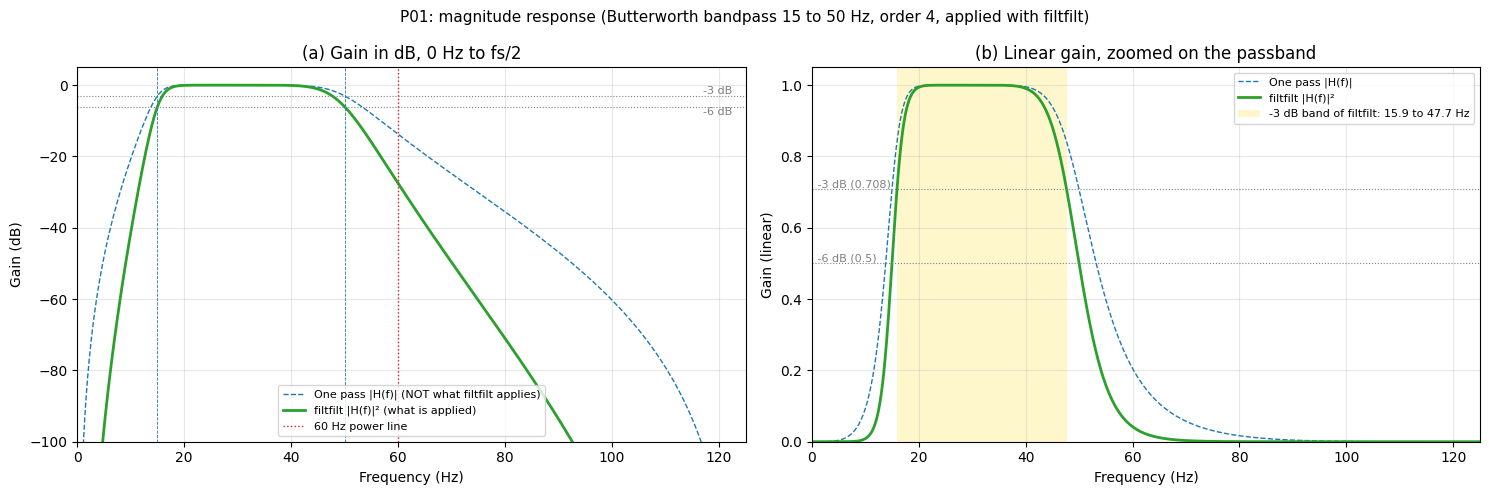

In [10]:
plot_magnitude(filt1, "P01")

### Doing the magnitude response properly with filtfilt

`freqz` gives H(f) for **one** pass of the filter. `sosfiltfilt` passes the signal through the filter **twice** (once forward, once backward). The backward pass has response H*(f) (same magnitude, opposite phase), so the overall response is

$$H_{\text{eff}}(f) = H(f)\,H^*(f) = |H(f)|^2 .$$

Consequences, all visible in the plots:

- **The gain in dB doubles.** A point that is −20 dB in one pass is −40 dB after filtfilt. The stopbands are much deeper than a single pass suggests.
- **The cutoffs move.** A Butterworth filter is −3 dB at its design cutoffs (|H| = 0.708). After filtfilt the gain there is |H|² = 0.5, which is −6 dB (half the amplitude, a quarter of the power). The −3 dB points of what is actually applied (|H|² = 0.708) lie slightly inside the design cutoffs; they are given in the legend of panel (b) and in the Part 1 table.
- **The roll-off doubles.** Each edge of an order-4 Butterworth bandpass falls 80 dB per decade in one pass, and 160 dB per decade after filtfilt.
- **The phase is exactly zero** at every frequency, because |H|² is real and positive. That is why there is no phase plot to make.

Plotting the single-pass |H| (dashed) for a filtfilt filter would show the wrong cutoffs and only half the attenuation.

**The applied response |H|² is flat (0 dB) from about 18 to 43 Hz, −3 dB at 15.95 and 47.66 Hz, and −6 dB at the design cutoffs of 15 and 50 Hz.** At 5 Hz (T waves, movement) it is −96 dB, at 2 Hz −162 dB, and below 1 Hz it is effectively zero. At 60 Hz it is −27.5 dB, and at 100 Hz −120 dB. The single-pass curve (dashed) would wrongly suggest only half of each of these attenuations.

## Part 5: Description of the peak detection algorithm you used

In [11]:
y1 = apply_filter(filt1, x1)
dtune1 = tune_detector(y1, fs1, "P01")
det1 = detect_r_peaks(y1, fs1, alpha=dtune1["best"][0], beta=dtune1["best"][1])
print(f"Detected {len(det1['peaks']):,} R waves using alpha = {det1['alpha']}, beta = {det1['beta']}")

P01: tried 15 detector settings in 65 s. Best: alpha = 0.6, beta = 0.7, error rate 2.14%
Detected 161,155 R waves using alpha = 0.6, beta = 0.7


### The detector, step by step

The detector works on the **filtered** ECG, y. In plain words: *find the peaks that are big compared with the recent beats, and don't accept a new beat sooner than the recent rhythm allows.*

1. **Envelope.** Take |y|. After the bandpass filter the QRS complex is the biggest, sharpest part of each beat. Its deflection can point up (R wave) or down (S wave), so the absolute value makes both count.
2. **Adaptive threshold.** Split |y| into 1-second blocks and take the biggest value in each block. Most 1-s blocks contain one beat, so that number is usually "the height of one beat". A running **median over 10 blocks (10 s)** gives the *typical* beat height at every moment. The threshold is **alpha × typical beat height**. Because it follows the recent beats, it adapts when the QRS gets bigger or smaller (posture, electrode contact, sleep) over 48 hours. The median ignores an occasional huge artifact spike or a block with no beat.
3. **Candidates.** Every local peak of |y| above the threshold, at least 0.25 s apart (no human heart beats faster than 240 bpm).
4. **Typical RR interval.** A quick first pass (fixed spacing of at least 0.30 s, i.e. up to 200 bpm) gives a rough list of beats. The running median of 31 of its RR intervals is the typical RR at every moment.
5. **Tallest first, with a minimum spacing.** Go through the candidates from the tallest to the shortest. Keep a candidate only if no beat already kept is closer than **beta × typical RR** (and never closer than 0.25 s). The tallest peak in each neighborhood always wins, and a smaller peak that follows a beat too soon (a T wave, or a noise spike) is thrown out.
6. **Mark the R wave.** |y| often peaks at the deep S wave instead of the R wave. Each mark is moved to the largest *positive* value of y within ±40 ms (inside the same QRS complex): the R wave.

Steps 1 to 3 are a standard adaptive threshold detector. Step 5 is the "other criteria" the assignment encourages: it uses the physiology of the heart (the rhythm changes gradually) the same way the error criterion does.

**For P01 the detector uses alpha = 0.6 and beta = 0.7, and it found 161,155 R waves (an average of 56 per minute).** A threshold of 0.6 means a peak must reach 60% of the typical beat height; beta = 0.7 means a new beat must come at least 70% of the typical RR interval after the previous one (for P01's typical RR of about 1.05 s, that is about 0.74 s).

## Part 6: Description of how you designed your peak detection algorithm including the rationale for your design decisions and parameter values

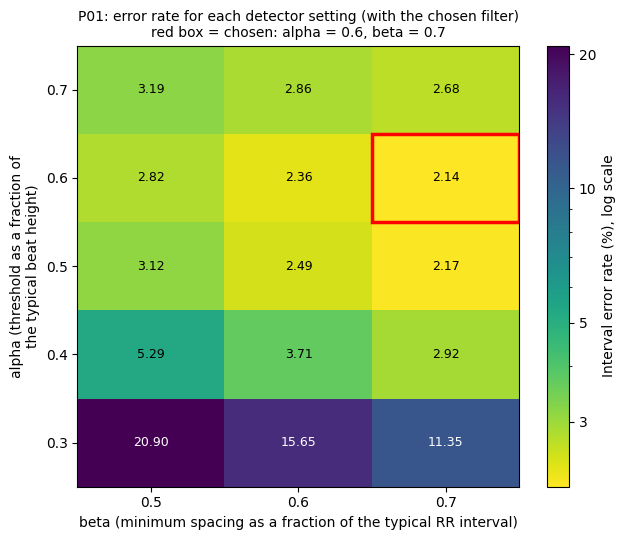

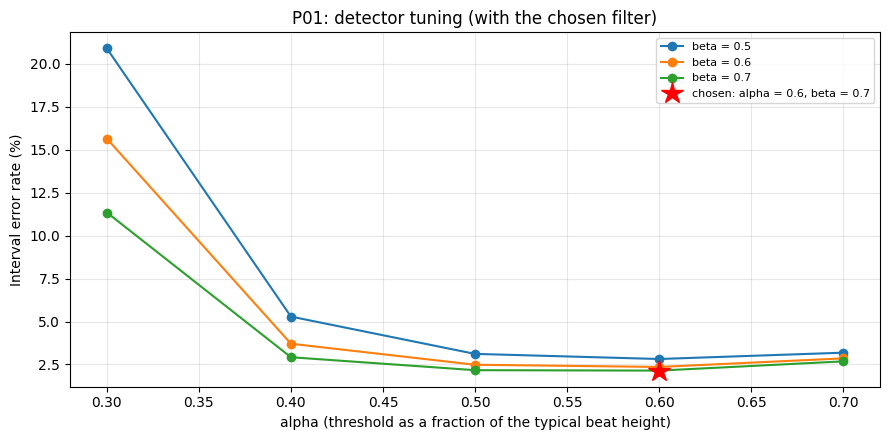

**P01: what each step contributes**

| Pipeline | Beats found | Interval error rate |
|---|---|---|
| Unfiltered ECG, simple detector (fixed 0.30 s refractory) | 196,996 | 35.65% |
| Filtered ECG, simple detector (fixed 0.30 s refractory) | 165,771 | 4.88% |
| Filtered ECG, full detector (spacing follows the rhythm) | 161,155 | 2.14% |

In [12]:
plot_detector_heatmap(dtune1, "P01")
plot_detector_tuning(dtune1, "P01")
compare_steps(x1, y1, fs1, det1, "P01")

### Detector design decisions

| Parameter or choice | Value | Why |
|---|---|---|
| Signal to detect on | Filtered ECG, \|y\| | The filter has already removed most of the artifact and T waves; the absolute value treats upward and downward QRS deflections the same. |
| Threshold type | **Adaptive** (follows the recent beats) | Over 48 hours the QRS height changes considerably with posture, activity, and electrode contact. One fixed threshold would be too high in some hours (missed beats) and too low in others (false beats). |
| Block length | 1 s | Usually one beat per block at normal heart rates (40 to 180 bpm), so the block maximum is about one beat's height. |
| Running median length | 10 blocks (10 s) | Long enough that a few blocks of artifact (or with no beat) don't change it; short enough to follow real changes in QRS height within seconds. |
| alpha (threshold fraction) | **Tuned per recording**, 0.3 to 0.7 tried | Too low: noise and T waves pass. Too high: smaller real beats are missed. The plot shows the error rate rising on both sides. |
| Minimum spacing, always | 0.25 s (240 bpm) | A safe upper limit on human heart rate. |
| First-pass spacing | 0.30 s (200 bpm) | Only used to estimate the typical RR, so it just has to be reasonable. |
| Typical RR window | 31 intervals (about 30 s) | A median over 31 beats is unaffected by up to 15 wrong detections, and still follows changes in heart rate within about half a minute. |
| beta (spacing as a fraction of typical RR) | **Tuned per recording**, 0.5 to 0.7 tried | A T wave comes 0.2 to 0.4 s after the R wave, roughly 30 to 45% of the RR interval at rest, so beta ≥ 0.5 removes it. beta was capped at 0.7 on purpose: real early (premature) beats, which healthy people have too, can arrive well before the normal interval, and a larger beta would delete more of them. A fixed refractory period cannot do this: 0.4 s would block T waves at rest but also delete real beats during exercise (heart rates around 150 bpm, RR near 0.4 s, occur in these recordings). |
| Tallest first | Yes | When two peaks are too close to both be beats, the bigger one is more likely to be the QRS. |
| R-wave search window | ±40 ms | Half the width of a QRS complex, so the mark moves to the R wave of the *same* beat and never to a neighboring wave. |

### How to read the tuning plot and the table

- **Tuning plot.** Each line is one beta; the x-axis is alpha. The red star is the chosen pair (lowest error rate).
- **"What each step contributes" table.** The same adaptive threshold detector run on (1) the original ECG, (2) the filtered ECG, and (3) the filtered ECG with the full detector. Row 1 versus row 2 shows what the **filter** buys; row 2 versus row 3 shows what the **rhythm-based spacing rule** buys.

**alpha = 0.6 and beta = 0.7 gave the lowest error rate (2.14%).**

- **alpha.** At alpha = 0.3 the error rate is 11 to 21%: the threshold is so low that muscle noise in the 15 to 50 Hz band passes it. From 0.5 to 0.7, with beta = 0.6 or 0.7, the curve is almost flat (2.2 to 2.9%), so the result does not depend on the exact value. P01 needs a higher threshold than P02 and P03 because its wide band (up to 50 Hz) lets in more muscle noise.
- **beta.** beta = 0.7 is best for every alpha. In a separate check (not shown), beta = 0.8 gave 2.06%, only 0.08 percentage points better, but it made P02 (2.51%) and P03 (1.73%) worse, and it would delete more real early beats, so 0.7 was kept as the upper limit.
- **What each step contributes (table).** The adaptive threshold detector on the unfiltered ECG has a 35.64% error rate; filtering brings it to 4.88% (the filter is the biggest single improvement); the rhythm-based spacing rule then cuts the remaining errors by more than half, to 2.14%.

## Part 7: Reported rate of misdetection, as described above

**P01: misdetection rate**

| Quantity | Value |
|---|---|
| Beats detected | 161,155 (average 56.0 per minute) |
| Intervals checked | 161,154 |
| Intervals flagged as errors | 3,455 |
| **Misdetection (interval error) rate** | **2.14%** |
| Intervals that contain clipped samples | 2,103 (1.30% of intervals) |
| Error rate in intervals with clipping | 43.8% |
| Error rate in intervals without clipping | 1.59% |
| Errors caused only by the 0.5 s floor (see note below) | 1 (0% of the errors; 0.00 percentage points of the rate) |

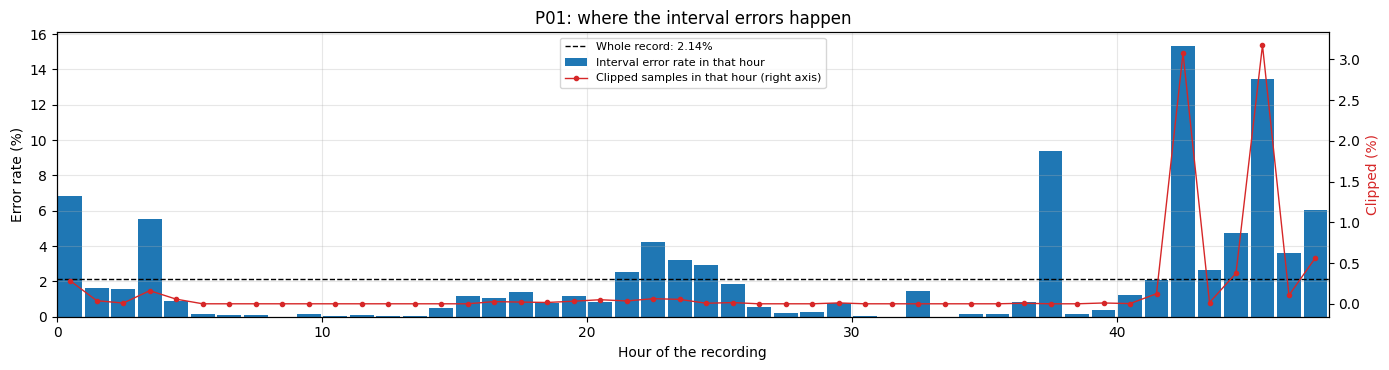

Note: the criterion raises the median interval to at least 0.5 s. When the heart really beats faster than about 160 bpm, correct detections can still be flagged. The row above counts intervals that are within 25% of their own median but are flagged only because of this floor.
The 4 hours with the most errors (hours 0, 37, 42, 45) hold 43% of all the error intervals.


In [13]:
ie1 = report_error(det1, x1, fs1, "P01")

**Misdetection rate for P01: 2.14%** (3,455 of 161,154 intervals flagged).

- Only 1.30% of the intervals contain clipped samples, but 43.8% of those are errors. In intervals without clipping the rate is **1.59%**.
- The errors are concentrated: the 4 worst hours (0, 37, 42, and 45) hold 43% of them. Hours 42 and 45 are the two big clipping episodes in the overview; hour 0 is the noisy start of the recording.
- Hour 37 has errors without clipping: around 37.5 h the detector adds extra detections about 0.35 s after real beats (Part 8, panel c), most likely muscle noise or a large T wave during movement.
- The 0.5 s floor of the criterion caused only 1 of the errors here, because P01's heart rate stays low (median 57 bpm, 5th to 95th percentile 47 to 67 bpm).

## Part 8: Plot of the RR intervals and median filtered RR intervals

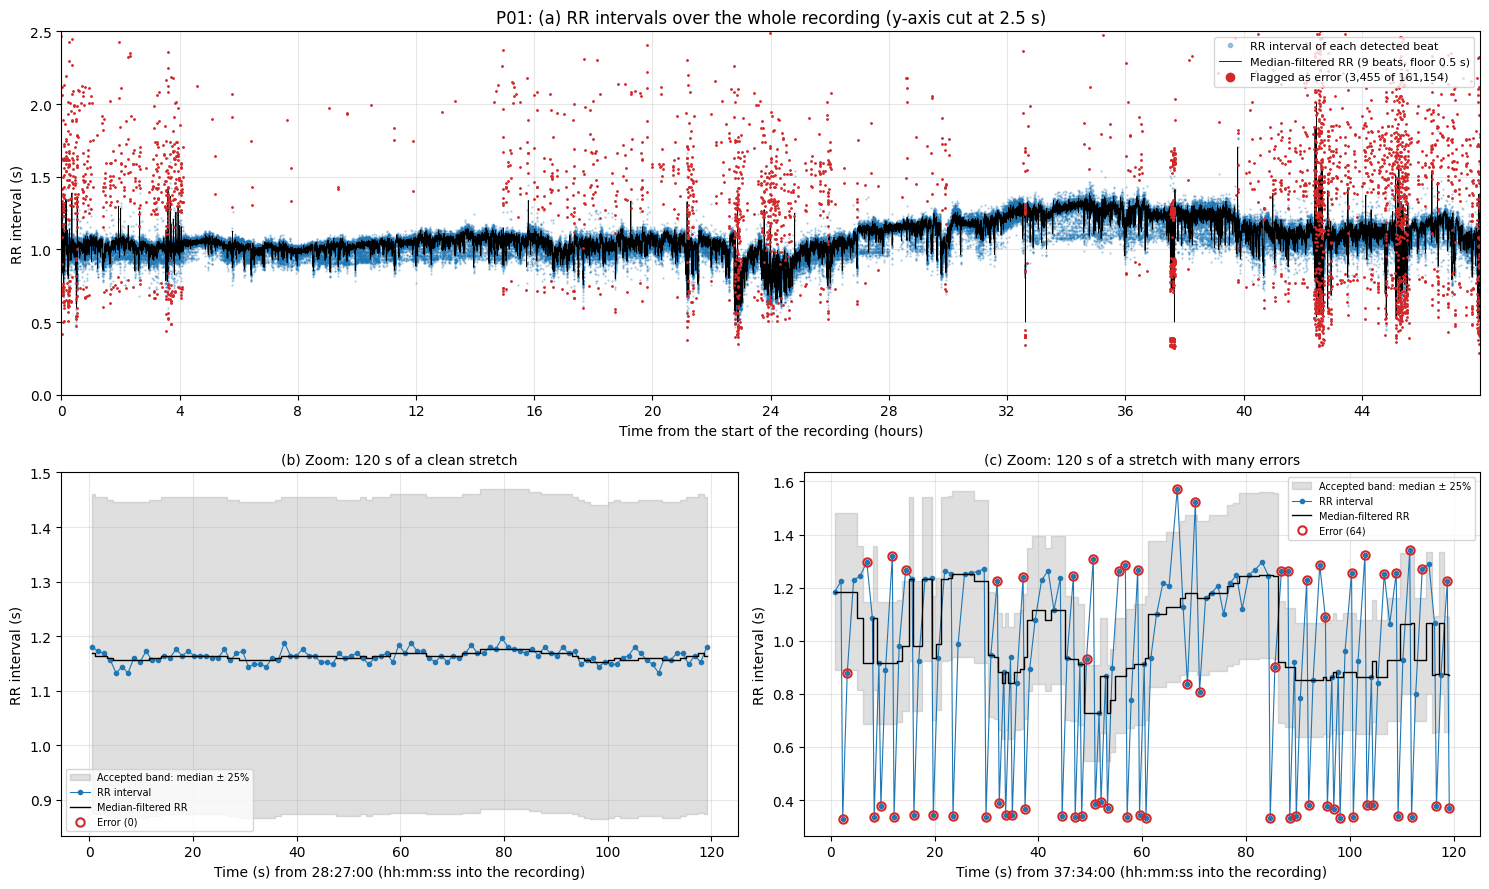

Heart rate from the median-filtered RR: median 57 bpm, 5th to 95th percentile 47 to 67 bpm


In [14]:
plot_rr(ie1, "P01")

### How to read the RR plot

- **(a) Whole recording.** Each blue dot is one RR interval (one per detected beat, about 160,000 to 250,000 dots). The black line is the 9-point median-filtered RR (with the 0.5 s floor) from the error criterion. Red dots are intervals flagged as errors.
    - The black line is the **heart rhythm over two days**: longer intervals (slower heart rate) at night, shorter during the day and during activity.
    - Red dots far above the line are usually **missed beats** (an interval about twice the normal length). Red dots below it are usually **extra detections**.
- **(b) and (c) Two-minute zooms.** The gray band is the accepted range, median ± 25%. Any interval outside it is an error (circled in red). Panel (b) is a clean stretch (no errors, the steadiest rhythm, median above the 0.5 s floor). Panel (c) is the two minutes with the most errors (where at least half the intervals are still correct), so you can see what errors look like.

**P01's heart rhythm is slow and steady: the median-filtered RR stays between about 0.9 and 1.4 s (roughly 43 to 67 bpm) for the whole two days.** It drifts slowly (longer intervals between about hours 32 and 40, likely the second night). The red error dots cluster where the overview shows artifact: hours 0 to 4, around hours 22 to 26, 37.5, and 42 to 47. Most red dots lie above the line (between 1.3 and 2.5 s), which are mostly missed beats, plus a band near 0.35 s at hour 37.5 (extra detections). Panel (c) shows that stretch: extra detections at about 0.35 s alternating with the remaining part of the real interval.

## Part 9: Plot of the original and filtered ECG signal over a 10 second segment without movement artifact

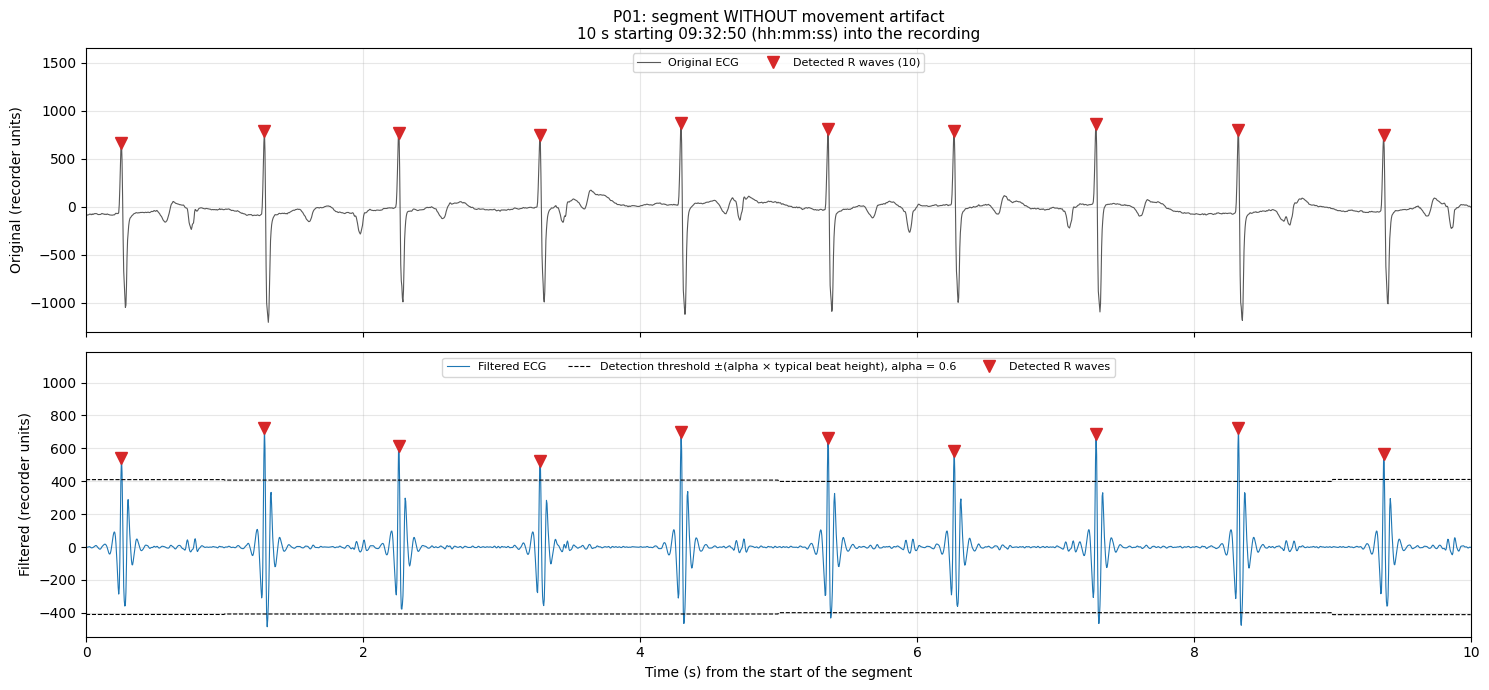

RR intervals in this segment: [1.03 0.97 1.02 1.02 1.06 0.91 1.02 1.03 1.05] s; interval errors here: 0


In [15]:
seg1 = segment_table(x1, y1, fs1, det1, ie1)
plot_segment(x1, y1, fs1, det1, ie1, pick_segment(seg1, ie1, "clean"), "P01", "segment WITHOUT movement artifact")

### How the segments in Parts 9 and 10 were chosen

The 48 hours were cut into 17,280 back-to-back 10-s segments, and each segment was scored (`segment_table`):

- **Artifact level:** the standard deviation of what the filter removed (original minus filtered), divided by the typical QRS height in that segment. Large = the artifact is big compared with the heartbeat.
- **Usable:** no clipped samples, no interval errors, and roughly the expected number of beats.

**Part 9** shows the usable segment with the *least* artifact; **Part 10** shows the usable segment with the *most* artifact. Choosing them by a rule, rather than by scrolling, makes them reproducible. The extra plot after Part 10 shows the segment with the most flagged errors, to show what an "error" looks like in practice.

### How to read the segment plots

- **Top:** the original ECG, with the detected R waves marked by red triangles.
- **Bottom:** the filtered ECG. The dashed lines are ± the detection threshold (alpha × typical beat height). The detector looks at |y|, so a peak counts if it crosses either dashed line.
- An orange circle marks a beat that ends an interval flagged as an error.
- The printout lists the RR intervals in the segment.

**All 10 R waves in this quiet segment (09:32:50 into the recording) are found, with RR intervals of 0.91 to 1.06 s and no errors.** The original ECG has a tall narrow R wave, a deep S wave, small P and T waves, and almost no baseline wander. After filtering, only the QRS complexes are left, each well above the threshold (dashed), and the T and P waves are almost completely gone. The red marks sit on the tip of each R wave in both panels, which shows that the filter adds no delay.

## Part 10: Plot of the original and filtered ECG signal over a 10 second segment with large movement artifact

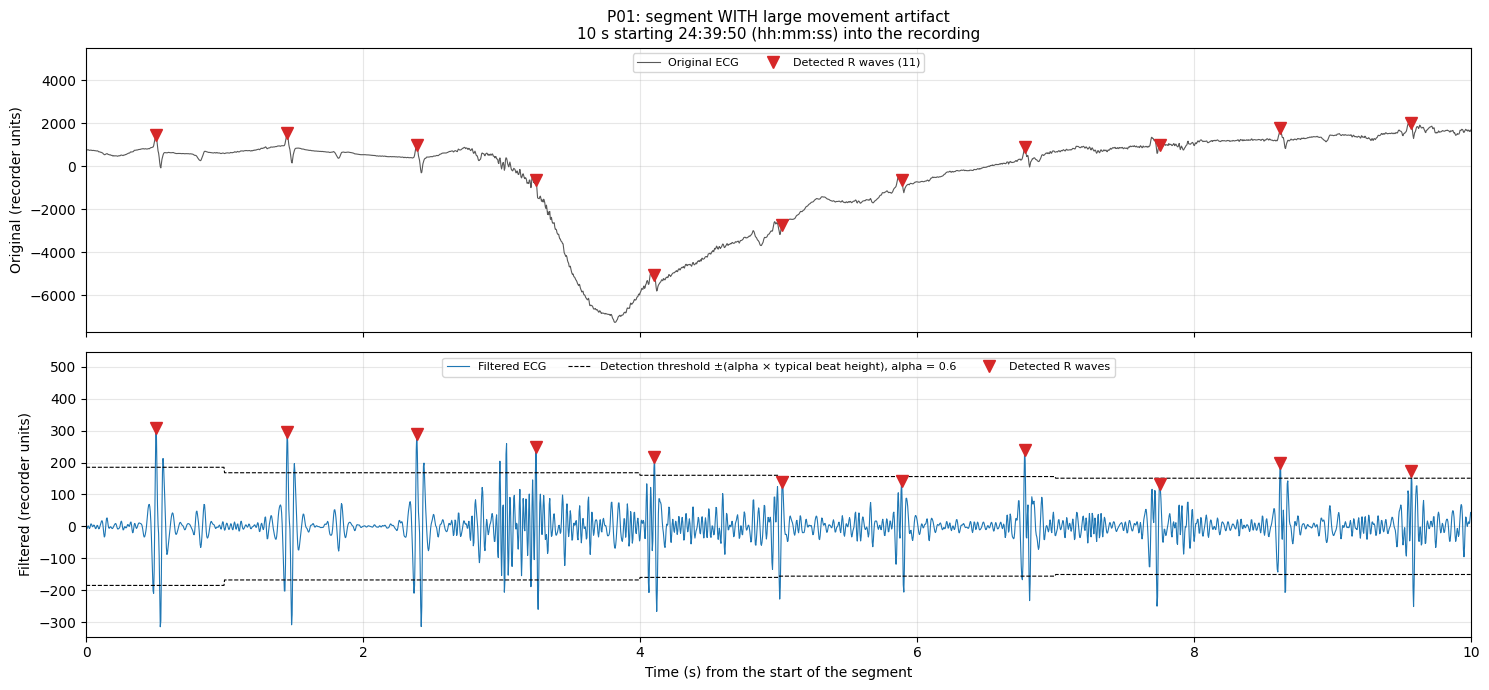

RR intervals in this segment: [0.95 0.94 0.86 0.86 0.92 0.86 0.89 0.98 0.87 0.95] s; interval errors here: 0


In [16]:
plot_segment(x1, y1, fs1, det1, ie1, pick_segment(seg1, ie1, "artifact"), "P01", "segment WITH large movement artifact")

**In this segment (24:39:50 into the recording) a movement swings the baseline by about 8,000 units, many times the height of the QRS complexes, and all 11 R waves are still found with no interval errors** (RR 0.86 to 0.98 s). In the original signal, the QRS complexes are small notches riding on the swing, and a simple threshold on the original would fire on the swing itself. In the filtered signal the swing is gone completely (it is below 2 Hz, where the gain is below −160 dB). The movement also adds a burst of muscle noise between about 3 and 6 s, which does pass the filter, but it stays under the adaptive threshold while the QRS peaks rise above it.

### For comparison: the segment with the most flagged interval errors

### How to read the "For comparison" plots

- **Red triangle:** a place where the detector marked an R wave. It may be right or wrong.
- **Orange circle:** the **interval ending at this beat** was flagged as an error, meaning it is more than 25% away from its expected value. The criterion checks the *gaps between beats*, not the beats themselves, so a circle means "something went wrong between this triangle and the previous one." It does **not** say which beat is wrong:

| What happened | How the circled gap looks |
|---|---|
| The circled triangle is a false detection | Too short |
| The *previous* triangle is a false detection (the circled one may be a real R wave) | Too short |
| A real beat was missed in between | Too long (about twice the normal interval) |
| Nothing is wrong with the detections: a sudden real rhythm change, or a heart rate above about 160 bpm (the 0.5 s floor) | Too short or too long, but the triangles sit on clear QRS complexes |

- **No circle does not guarantee a correct detection.** If most of the nearby detections are wrong, the expected interval (the median of 9 intervals) is wrong too, and a bad gap can look normal. In P01, the triangle at about 3.4 s sits on clipped artifact but is not circled for this reason.
- **Quick rule:**
    - Circles on *every* beat with *evenly spaced* triangles on clear QRS complexes: the detections are fine and the criterion is the problem (P02 and P03).
    - Circles on *some* beats with *irregular* spacing on artifact or clipping: the detector really failed (P01).
- The count printed below each plot ("interval errors here") equals the number of circles. The first circle can belong to an interval that started just before the 10-second window, so there can be one more circle than intervals listed in the printout.

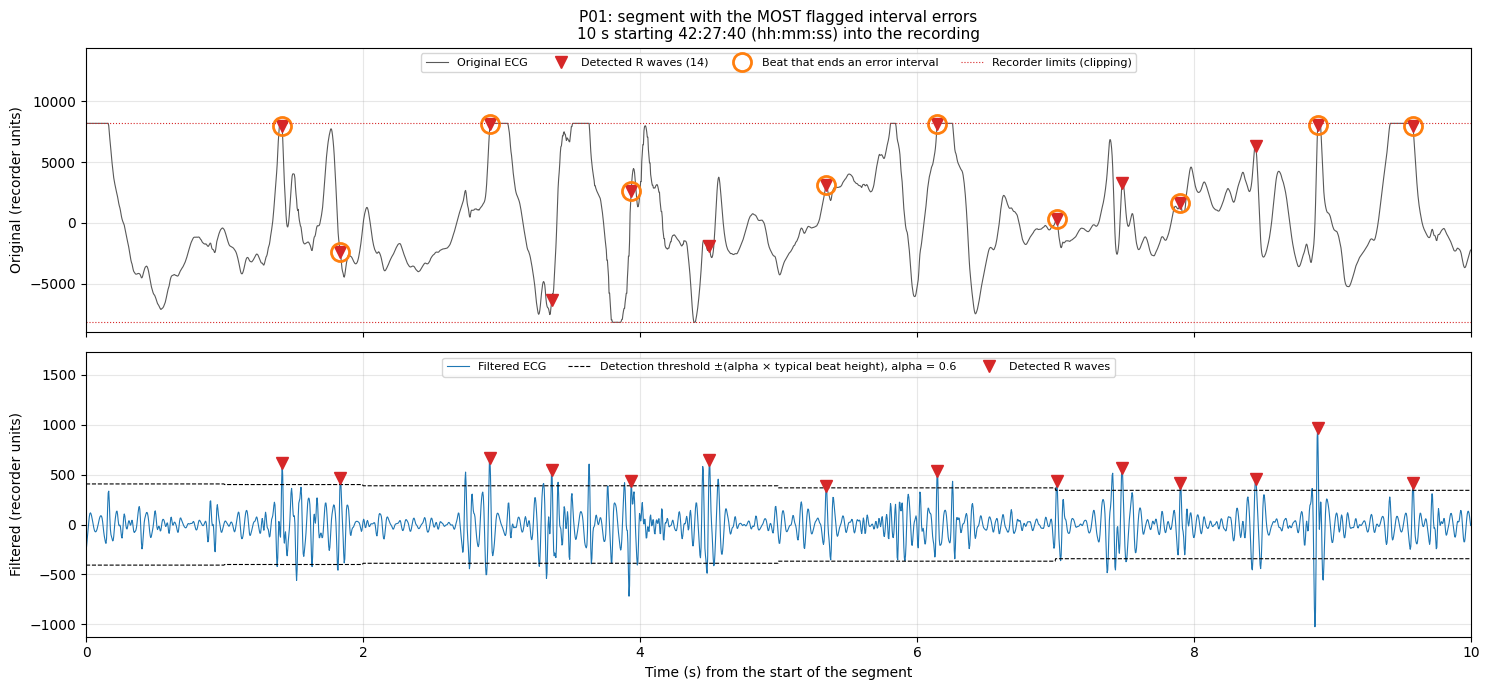

RR intervals in this segment: [0.42 1.08 0.45 0.57 0.56 0.84 0.8  0.86 0.47 0.42 0.54 0.45 0.69] s; interval errors here: 10


In [17]:
plot_segment(x1, y1, fs1, det1, ie1, pick_segment(seg1, ie1, "failure"), "P01", "segment with the MOST flagged interval errors")

**This is a real failure of the method.** At 42:27:40 the recorder is clipping (the flat tops at ±8192) and the swings are much larger and faster than any QRS complex. The ECG is buried and partly lost, and the filtered signal is mostly noise with peaks of similar height everywhere, so the detections are essentially random (10 of the 14 intervals are errors). No filter can recover beats that the recorder never captured; the realistic fix is to detect such stretches and exclude them as unreadable [5], [6] (see "Why do we care about clipping?").

# Recording 2: `P02_ecg.npz`

### Overview of the whole recording

P02_ecg.npz
  43,200,000 samples at 250 Hz = 48.0 hours
  values from -8192 to 8191.75 in steps of 0.25 (a 16-bit recorder: 65,536 levels x 0.25)
  0.013% of samples are clipped (|x| >= 8191)


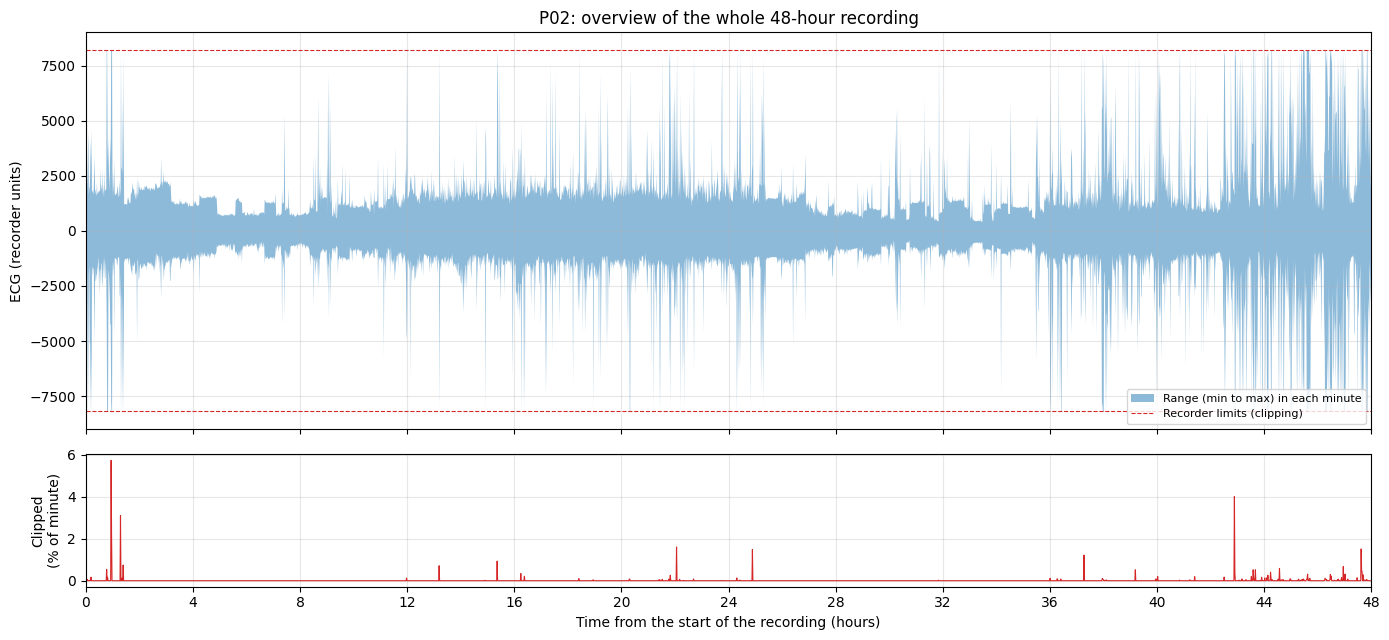

Minutes with any clipping: 4.6% of the record; minutes that are more than 10% clipped: 0.0%


In [18]:
x2, fs2 = load_ecg("P02_ecg.npz")
plot_overview(x2, fs2, "P02")

**P02 is the cleanest recording in terms of clipping:** only 4.6% of minutes have any clipped sample, no minute is more than 10% clipped, and only 0.013% of all samples are clipped. The artifact is frequent but mostly moderate, with more and larger movement in the last 6 hours. The narrower, steadier stretches (for example around hours 4 to 8 and 28 to 36) are likely sleep.

## Part 1: Description of your filter

P02: Butterworth bandpass, order 4, filtfilt; detector alpha = 0.5, beta = 0.6
   Run  f_lo (Hz)  f_hi (Hz)  Error rate
     1          5         20       3.52%
     2          5         25       3.15%
     3          5         30       2.98%
     4          5         35       2.92%
     5          5         40       2.90%
     6          5         50       2.92%
     7          8         20       2.98%
     8          8         25       2.78%
     9          8         30       2.66%
    10          8         35       2.63%
    11          8         40       2.63%
    12          8         50       2.67%
    13         10         20       2.88%
    14         10         25       2.64%
    15         10         30       2.56%
    16         10         35       2.55%
    17         10         40       2.56%
    18         10         50       2.61%
    19         12         20       2.79%
    20         12         25       2.54%
    21         12         30       2.47%
    22         12  

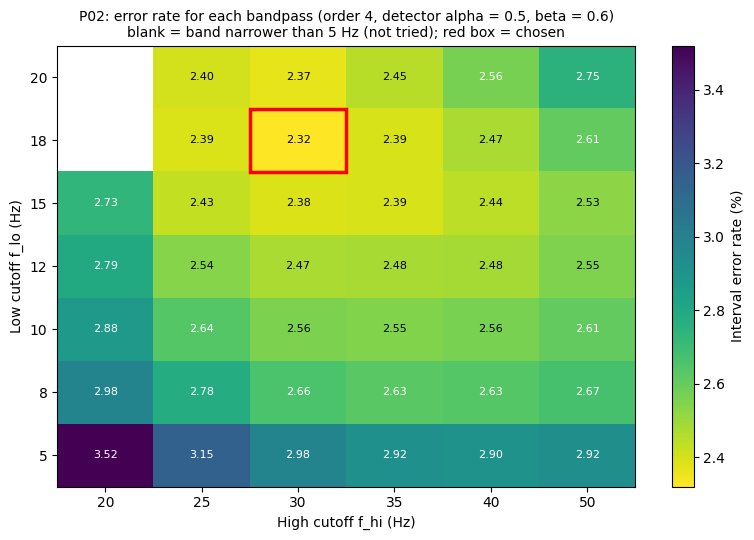

**P02: filter summary**

| Property | Value |
|---|---|
| Type | Butterworth bandpass (maximally flat passband: no ripple) |
| Order | 4 per edge (8 poles, 4 second-order sections) |
| Cutoff frequencies (one pass, -3 dB) | 18 Hz and 30 Hz |
| How it is applied | Forward and backward (`sosfiltfilt`): zero phase, magnitude response |H|² |
| Effective order after filtfilt | 8 per edge: 160 dB per decade on each side |
| -3 dB band after filtfilt | 18.49 to 29.24 Hz (slightly inside the design cutoffs) |
| Gain at the design cutoffs after filtfilt | -6.0 dB (one pass is -3 dB; twice is -6 dB) |
| Gain after filtfilt at 0.5 Hz (breathing and slow baseline wander) | below -200 dB |
| Gain after filtfilt at 2 Hz (typical movement artifact) | below -200 dB |
| Gain after filtfilt at 5 Hz (T waves and slower movement) | -147.5 dB |
| Gain after filtfilt at 60 Hz (power-line hum) | -112.9 dB |
| Gain after filtfilt at 100 Hz (muscle (EMG) noise) | below -200 dB |

In [19]:
tune2 = tune_filter(x2, fs2, "P02")
filt2 = design_filter(*tune2["best"], fs2, order=tune2["order"])
plot_filter_tuning(tune2, "P02")
describe_filter(filt2, "P02")

**A 4th-order Butterworth bandpass filter from 18 to 30 Hz, as second-order sections, applied forward and backward with `sosfiltfilt` (zero phase).** This is the narrowest of the three filters. The gain actually applied (|H|²) is −3 dB at 18.49 and 29.24 Hz and −6 dB at 18 and 30 Hz. It removes 5 Hz content by 148 dB, and the 60 Hz power-line hum (clearly present in P02's spectrum) by 113 dB.

## Part 2: Description of how you designed your filter including the rationale for your design decisions and parameter values

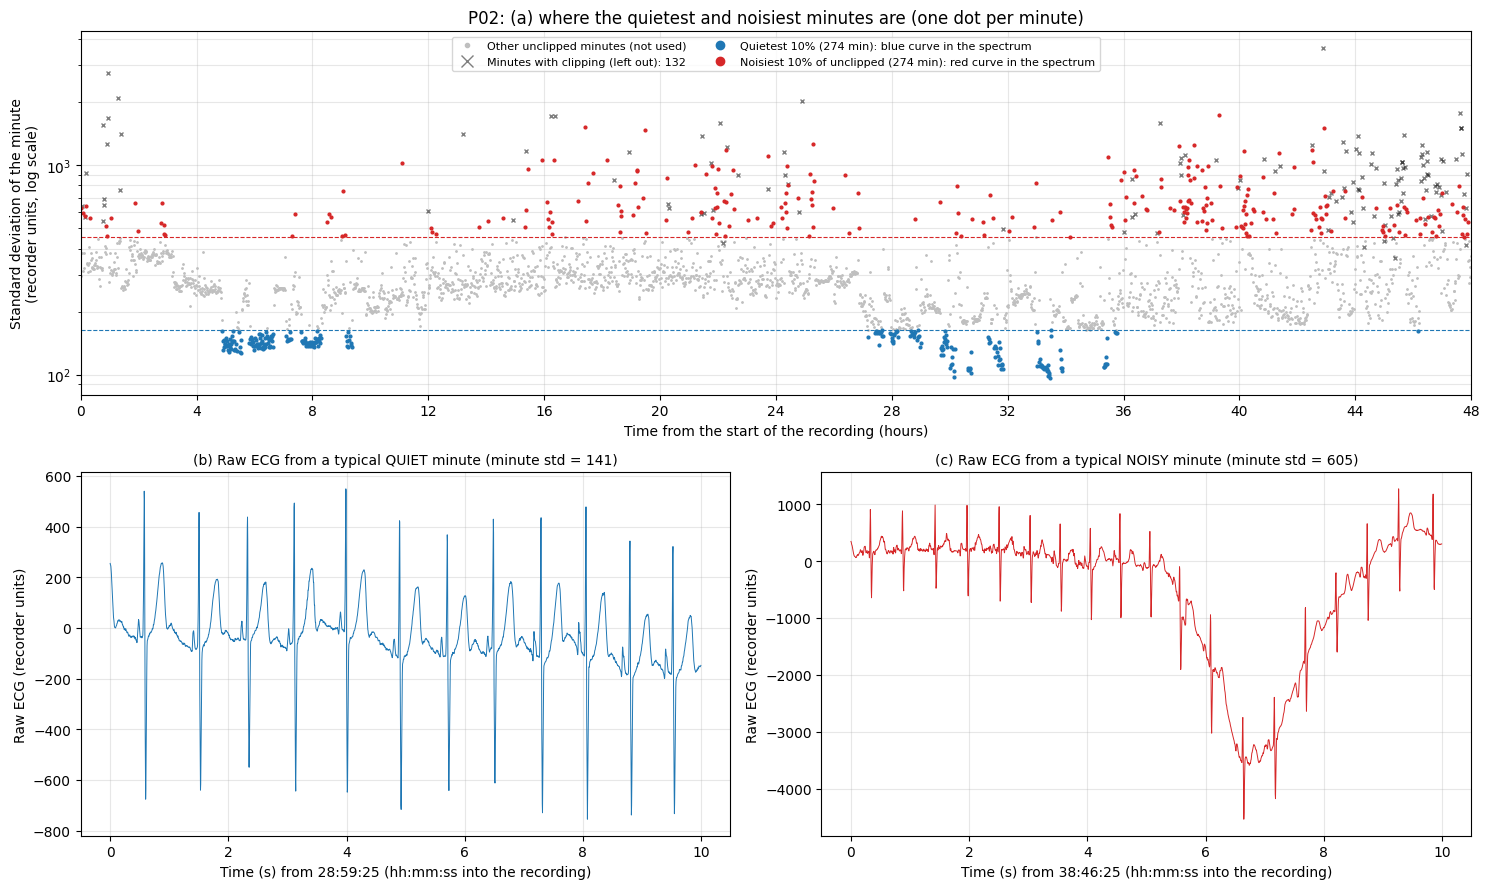

Quietest 10%: minute std from 96 to 163; hours holding the most of them: hour 5 (38 min), hour 6 (38 min), hour 7 (31 min), hour 28 (22 min), hour 33 (34 min)
Noisiest 10%: minute std from 454 to 1729; hours holding the most of them: hour 21 (12 min), hour 38 (29 min), hour 40 (21 min), hour 42 (15 min), hour 46 (13 min)


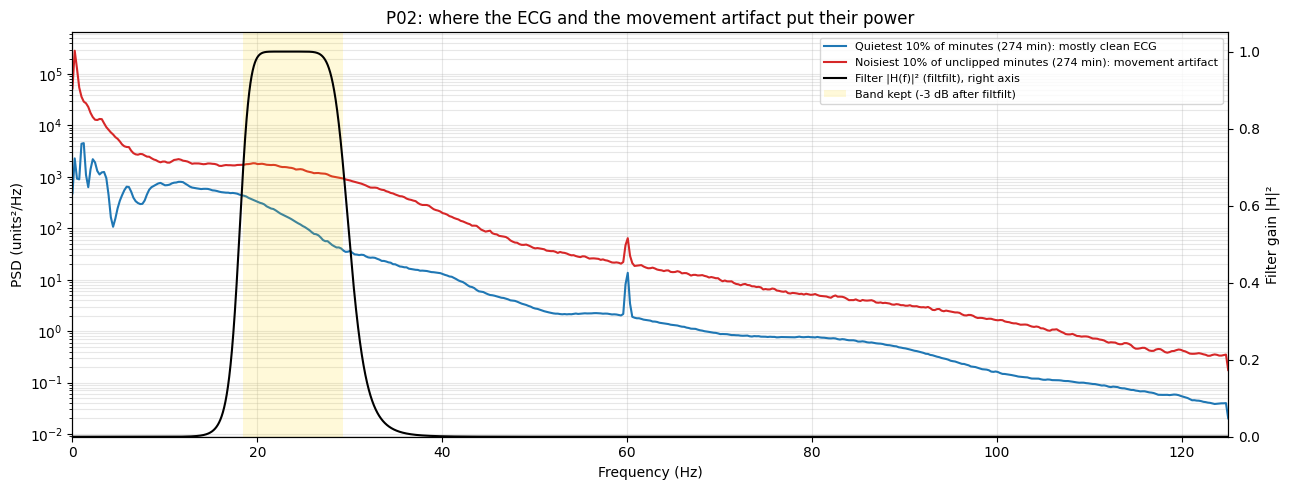

    1 Hz: noisy minutes have   9.2 dB more power than quiet minutes
    3 Hz: noisy minutes have  10.8 dB more power than quiet minutes
    5 Hz: noisy minutes have  13.5 dB more power than quiet minutes
   10 Hz: noisy minutes have   4.6 dB more power than quiet minutes
   15 Hz: noisy minutes have   5.1 dB more power than quiet minutes
   20 Hz: noisy minutes have   7.4 dB more power than quiet minutes
   30 Hz: noisy minutes have  13.7 dB more power than quiet minutes
   40 Hz: noisy minutes have  11.8 dB more power than quiet minutes


In [20]:
plot_minute_selection(x2, fs2, "P02")
plot_spectra(x2, fs2, filt2, "P02")

**18 to 30 Hz had the lowest error rate (2.32% with the default detector), but the whole heat map is fairly flat: every band with f_lo ≥ 12 Hz is between 2.32% and 2.79%.** So for P02 the exact cutoffs matter much less than for P01.

- **Low cutoff (18 Hz).** P02 has large, broad T waves (Part 9) and the noisy minutes have 9 to 14 dB more power than the quiet ones up to 5 Hz. Error rates fall steadily as f_lo rises from 5 Hz (2.9 to 3.5%) to 15 to 18 Hz, because the T waves and the slow artifact are pushed further into the stopband.
- **High cutoff (30 Hz).** Unlike P01, P02's artifact also carries a lot of high-frequency power: the noisy minutes have 12 to 14 dB more power than the quiet ones at 30 to 40 Hz (muscle noise during movement), plus a 60 Hz hum line. Cutoffs of 40 and 50 Hz let more of that through: in the rows with f_lo of 12 Hz or more, the error rate rises once f_hi goes past 30 Hz.
- In short, P02's useful band is squeezed from both sides, which is why its best band is the narrowest.

## Part 3: Plot of the impulse response of your filter

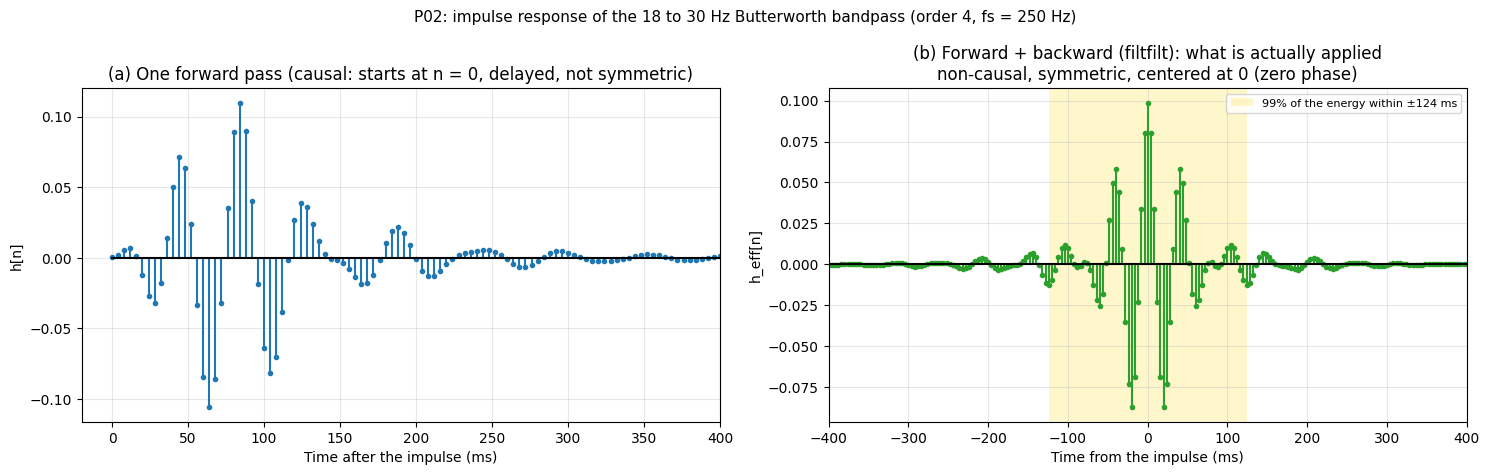

Peak of h_eff at n = 0 (zero delay). Symmetric: max |h_eff[n] - h_eff[-n]| = 4.7e-04. Sum of h_eff = -1.6e-04 (a bandpass has zero gain at 0 Hz, so its taps sum to 0).


In [21]:
plot_impulse(filt2, "P02")

**The effective impulse response is again symmetric and centered at n = 0, but it rings for much longer than P01's: 99% of its energy lies within ±124 ms, versus ±48 ms for P01.** A narrower passband always means a longer impulse response: frequency width and time duration are inversely related. The ringing is at about the center of the band (roughly 24 Hz), which is why each filtered QRS in Parts 9 and 10 looks like a short burst of oscillations.

## Part 4: Plot of the magnitude response of your filter

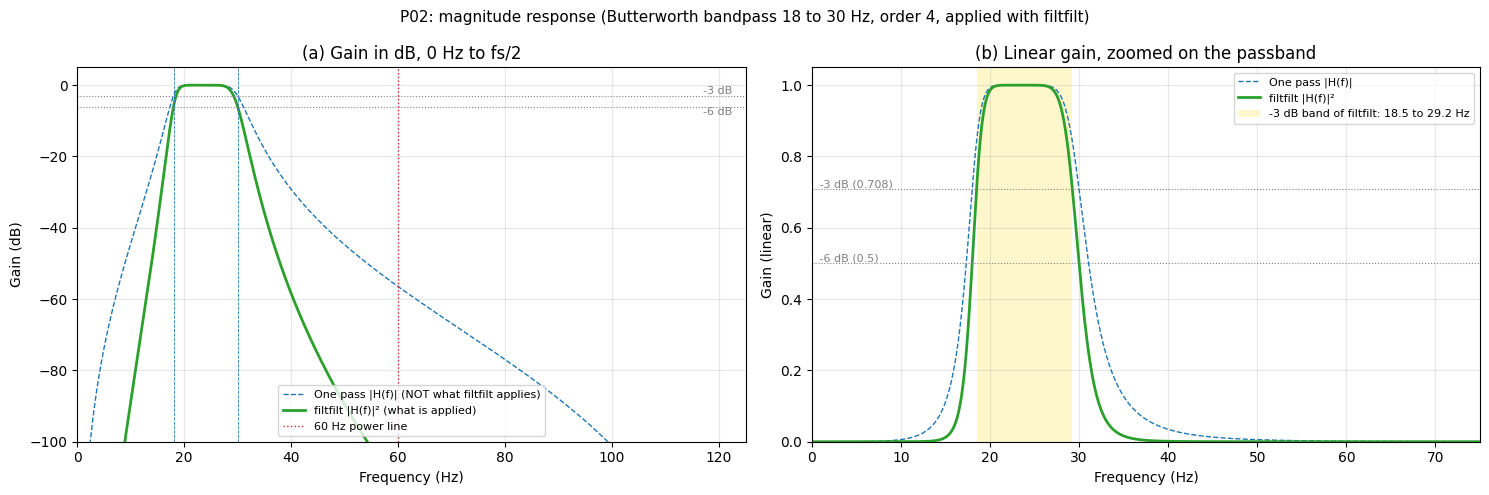

In [22]:
plot_magnitude(filt2, "P02")

**The applied response |H|² is close to 1 only from roughly 20 to 27 Hz, −3 dB at 18.49 and 29.24 Hz, and −6 dB at 18 and 30 Hz.** It is −148 dB at 5 Hz, −214 dB at 2 Hz, −113 dB at 60 Hz, and −202 dB at 100 Hz. The narrow band makes the edges look steep on the linear plot.

## Part 5: Description of the peak detection algorithm you used

In [23]:
y2 = apply_filter(filt2, x2)
dtune2 = tune_detector(y2, fs2, "P02")
det2 = detect_r_peaks(y2, fs2, alpha=dtune2["best"][0], beta=dtune2["best"][1])
print(f"Detected {len(det2['peaks']):,} R waves using alpha = {det2['alpha']}, beta = {det2['beta']}")

P02: tried 15 detector settings in 79 s. Best: alpha = 0.4, beta = 0.7, error rate 2.28%
Detected 246,798 R waves using alpha = 0.4, beta = 0.7


Same detector as Recording 1 (see Recording 1, Part 5); only alpha and beta are tuned for this recording.

**For P02 the detector uses alpha = 0.4 and beta = 0.7, and it found 246,798 R waves (an average of 85.7 per minute).** P02 has the fastest heart rate of the three (median 90 bpm).

## Part 6: Description of how you designed your peak detection algorithm including the rationale for your design decisions and parameter values

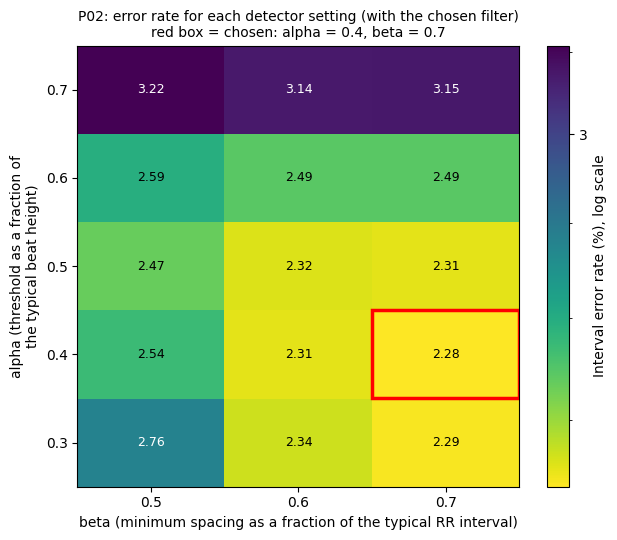

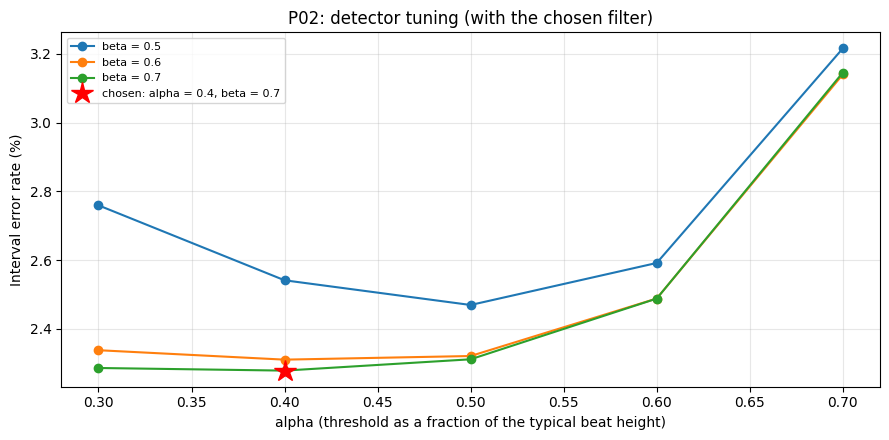

**P02: what each step contributes**

| Pipeline | Beats found | Interval error rate |
|---|---|---|
| Unfiltered ECG, simple detector (fixed 0.30 s refractory) | 275,274 | 19.09% |
| Filtered ECG, simple detector (fixed 0.30 s refractory) | 248,047 | 2.62% |
| Filtered ECG, full detector (spacing follows the rhythm) | 246,798 | 2.28% |

In [24]:
plot_detector_heatmap(dtune2, "P02")
plot_detector_tuning(dtune2, "P02")
compare_steps(x2, y2, fs2, det2, "P02")

**alpha = 0.4 and beta = 0.7 gave the lowest error rate (2.28%).** P02 can use a lower threshold than P01 because its narrow filter leaves little noise between beats; alpha = 0.7 is clearly worse (3.1 to 3.2%) because smaller real beats start to be missed. beta = 0.7 was best, or within 0.01 percentage points of best, at every alpha.

**What each step contributes:** 19.09% on the unfiltered ECG, 2.62% after filtering, 2.28% with the full detector. Here the filter does almost all of the work; the spacing rule helps less than for P01 because P02's filtered signal has fewer T-wave and noise detections to remove.

## Part 7: Reported rate of misdetection, as described above

**P02: misdetection rate**

| Quantity | Value |
|---|---|
| Beats detected | 246,798 (average 85.7 per minute) |
| Intervals checked | 246,797 |
| Intervals flagged as errors | 5,622 |
| **Misdetection (interval error) rate** | **2.28%** |
| Intervals that contain clipped samples | 368 (0.15% of intervals) |
| Error rate in intervals with clipping | 34.0% |
| Error rate in intervals without clipping | 2.23% |
| Errors caused only by the 0.5 s floor (see note below) | 2,862 (51% of the errors; 1.16 percentage points of the rate) |

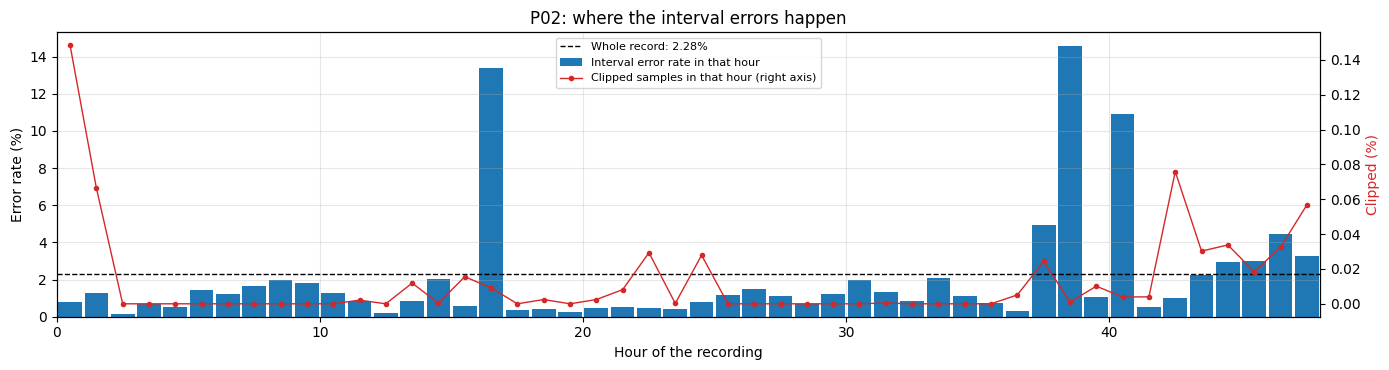

Note: the criterion raises the median interval to at least 0.5 s. When the heart really beats faster than about 160 bpm, correct detections can still be flagged. The row above counts intervals that are within 25% of their own median but are flagged only because of this floor.
The 4 hours with the most errors (hours 16, 37, 38, 40) hold 53% of all the error intervals.


In [25]:
ie2 = report_error(det2, x2, fs2, "P02")

**Misdetection rate for P02: 2.28%** (5,622 of 246,797 intervals flagged).

- Clipping is rare here (0.15% of intervals), so the rate without clipping is almost the same, 2.23%.
- **About half of these "errors" are not detection mistakes.** 2,862 of the flagged intervals (51%, or 1.16 percentage points of the rate) are flagged only because of the criterion's 0.5 s floor. P02 has several bouts of very fast heart rate, around hours 16, 38, and 40, where the RR interval is about 0.32 to 0.37 s (160 to 190 bpm). The detections there are correct and evenly spaced (see the segment after Part 10), but the criterion raises the expected interval to 0.5 s, and anything shorter than 0.375 s then counts as an error. Without the floor, P02's error rate would be about 1.1%.
- The 4 worst hours (16, 37, 38, 40) hold 53% of the errors; these are mostly those fast-rate bouts.

## Part 8: Plot of the RR intervals and median filtered RR intervals

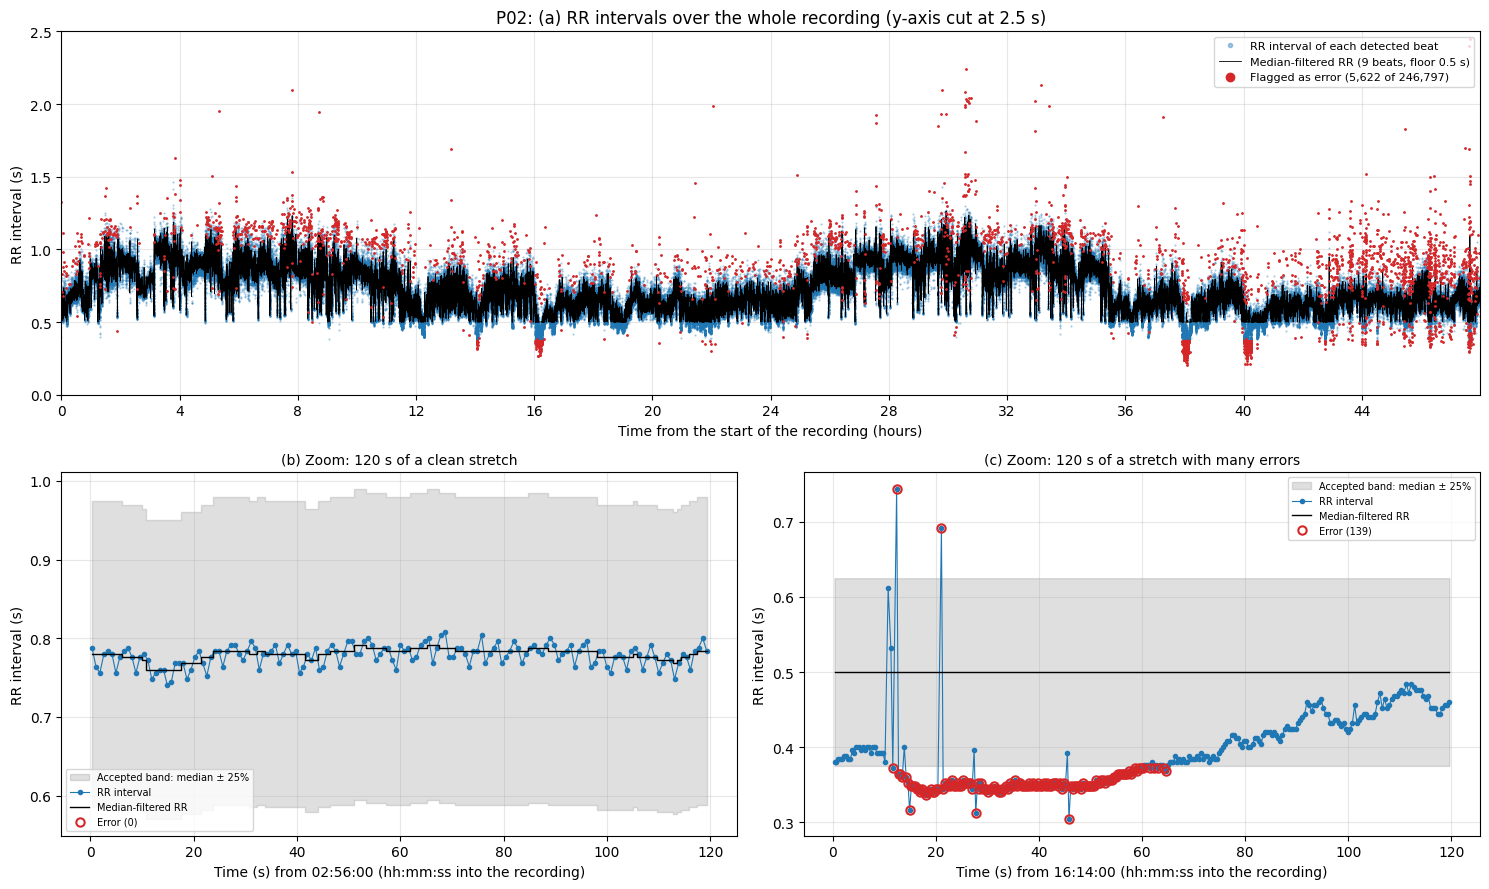

Heart rate from the median-filtered RR: median 90 bpm, 5th to 95th percentile 62 to 120 bpm


In [26]:
plot_rr(ie2, "P02")

**P02's heart rate is higher and more variable: the median-filtered RR moves between about 0.5 and 1.2 s (50 to 120 bpm) through the two days**, with long slow stretches (likely sleep) around hours 4 to 9 and 28 to 35. The black line is flat at 0.5 s whenever the heart beats faster than 120 bpm (the floor). Below it, around hours 16, 38, and 40, are the bouts of 160 to 190 bpm, marked red. Panel (c) zooms in on hour 16: the RR intervals form a smooth, steady curve at about 0.35 s, which is a real fast rhythm, not noise, yet every one of them falls below the 0.375 s edge of the accepted band. The red dots above the line in the last 6 hours are mostly missed beats during movement.

## Part 9: Plot of the original and filtered ECG signal over a 10 second segment without movement artifact

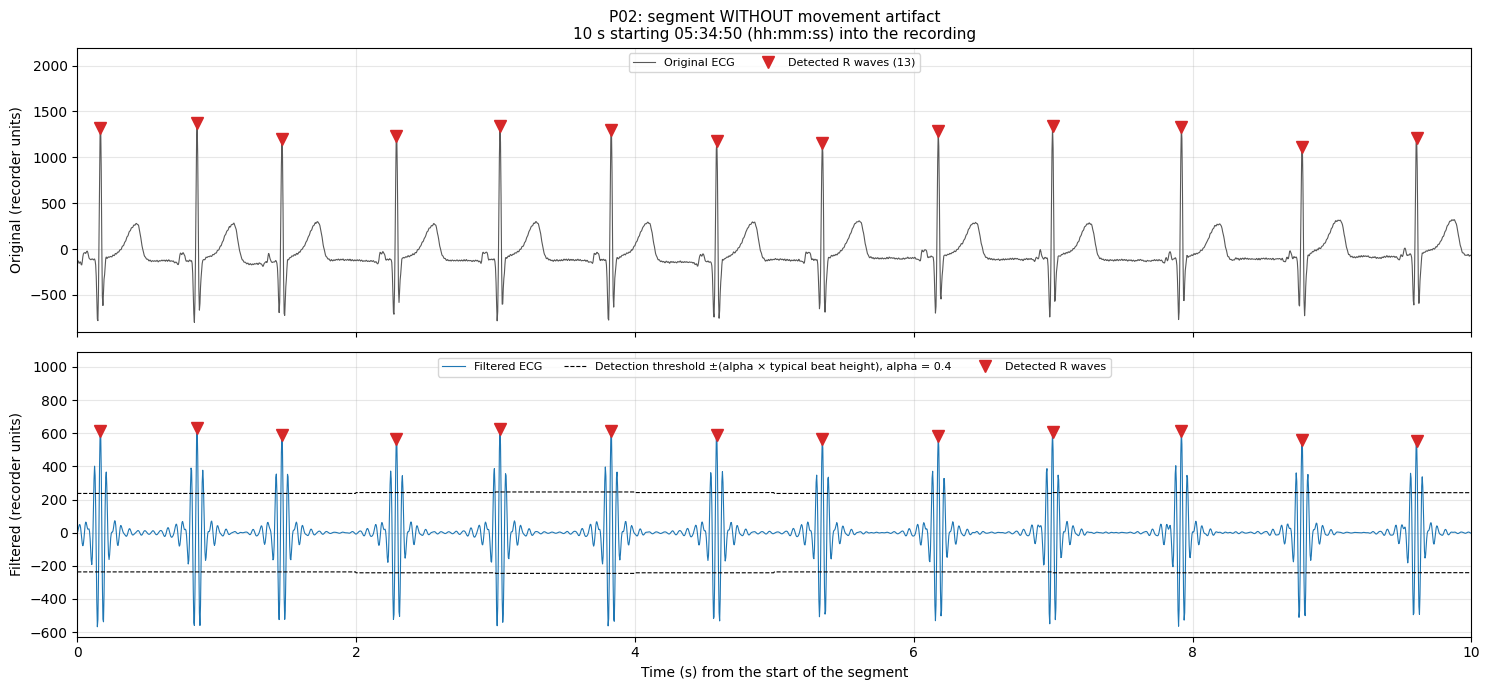

RR intervals in this segment: [0.7  0.61 0.82 0.74 0.8  0.76 0.76 0.83 0.82 0.92 0.86 0.82] s; interval errors here: 0


In [27]:
seg2 = segment_table(x2, y2, fs2, det2, ie2)
plot_segment(x2, y2, fs2, det2, ie2, pick_segment(seg2, ie2, "clean"), "P02", "segment WITHOUT movement artifact")

**All 13 R waves in this quiet segment (05:34:50) are found, with RR 0.61 to 0.92 s and no errors.** P02's ECG has a tall R wave and a large, broad T wave. After the 18 to 30 Hz filter the T wave has disappeared, and each QRS turns into a short burst of oscillations whose largest positive peak is the R wave.

## Part 10: Plot of the original and filtered ECG signal over a 10 second segment with large movement artifact

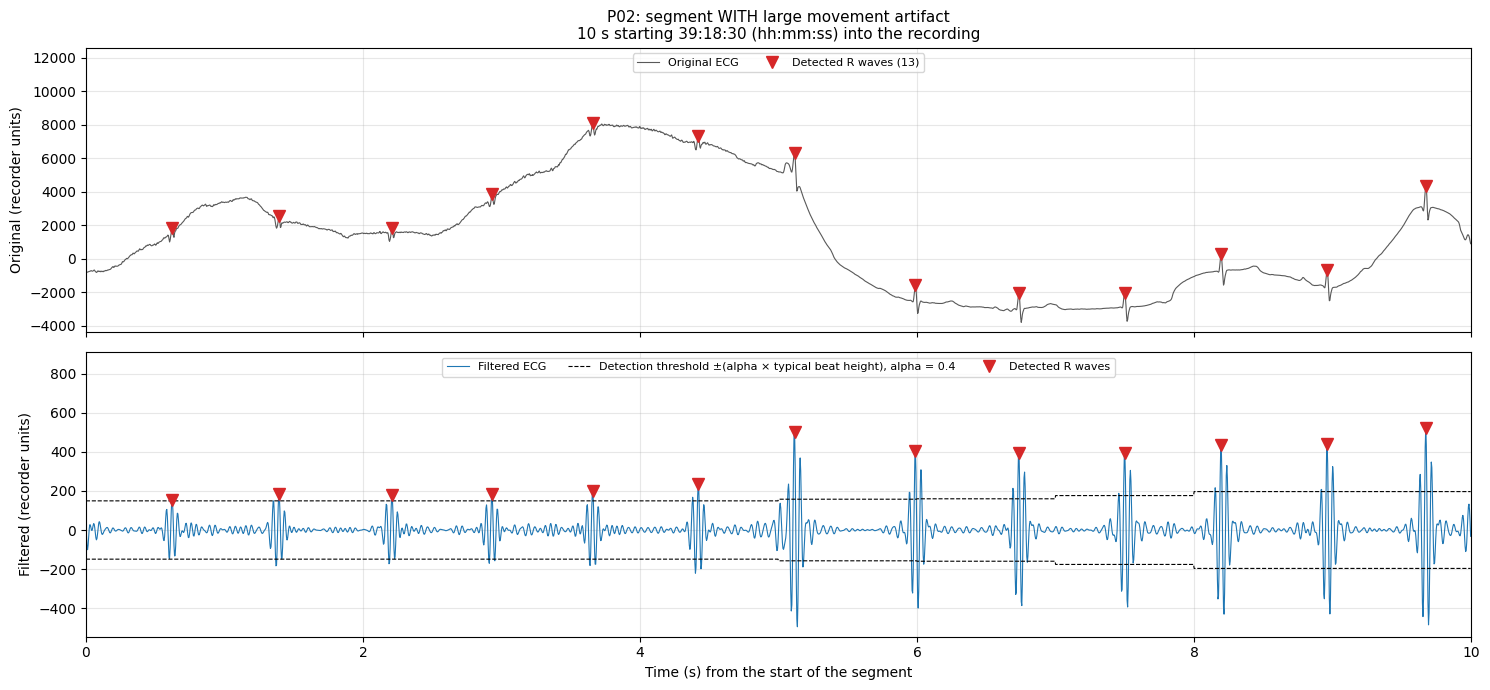

RR intervals in this segment: [0.77 0.82 0.72 0.73 0.76 0.7  0.87 0.75 0.76 0.7  0.76 0.71] s; interval errors here: 0


In [28]:
plot_segment(x2, y2, fs2, det2, ie2, pick_segment(seg2, ie2, "artifact"), "P02", "segment WITH large movement artifact")

**In this segment (39:18:30) a movement swings the baseline by about 11,000 units (from about −3,000 to +8,000, close to the clipping limit), while the QRS complexes are only a few hundred units tall. All 13 R waves are still found with no interval errors** (RR 0.70 to 0.87 s). The filtered signal shows no trace of the swing; the QRS bursts change size (they get larger after 5 s, probably because the movement changed the electrode contact), and the adaptive threshold follows that change.

### For comparison: the segment with the most flagged interval errors

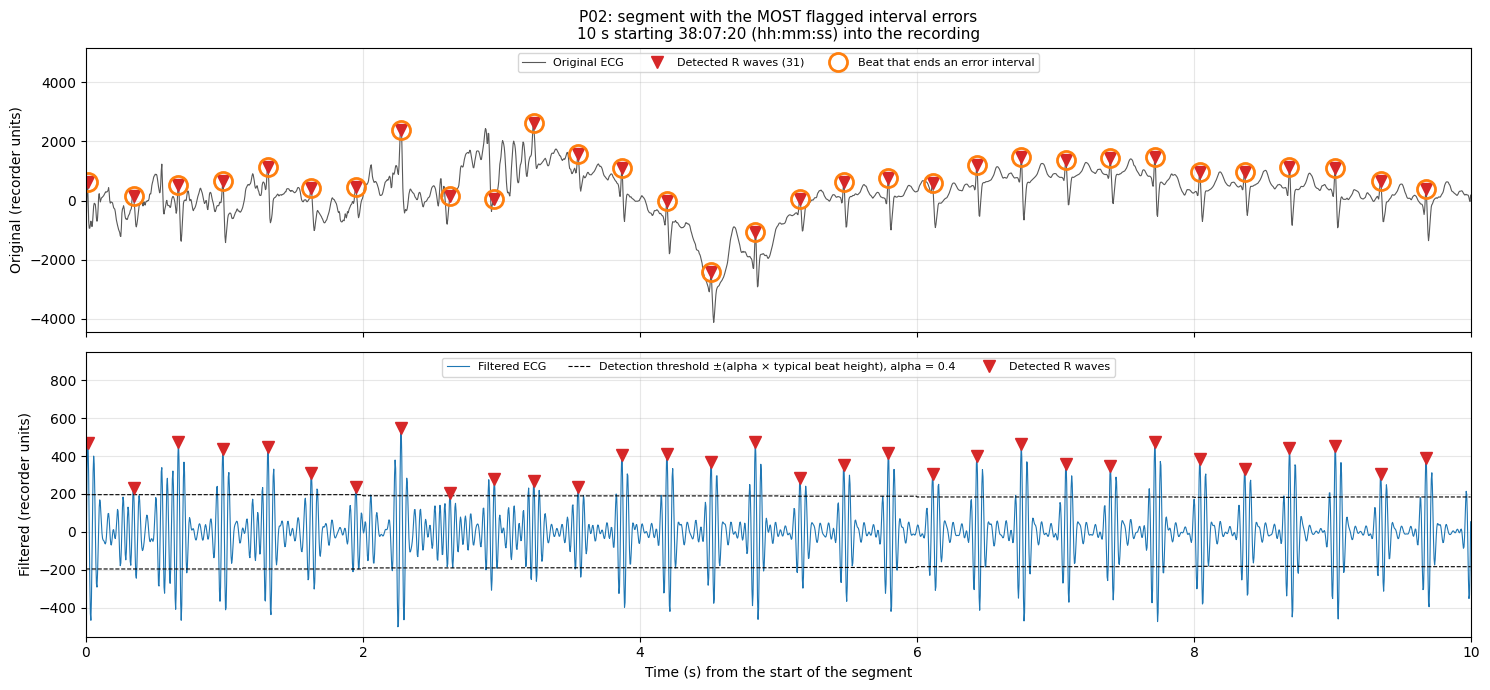

RR intervals in this segment: [0.33 0.32 0.32 0.33 0.31 0.32 0.33 0.35 0.32 0.28 0.32 0.32 0.33 0.32
 0.32 0.32 0.32 0.32 0.32 0.32 0.32 0.32 0.32 0.32 0.32 0.32 0.32 0.33
 0.33 0.33] s; interval errors here: 31


In [29]:
plot_segment(x2, y2, fs2, det2, ie2, pick_segment(seg2, ie2, "failure"), "P02", "segment with the MOST flagged interval errors")

**This segment, with 31 flagged errors, is actually a correct detection that the criterion counts as wrong.** At 38:07:20 the heart is beating at about 185 bpm (RR 0.31 to 0.35 s). The original ECG shows a distinct QRS at every mark, the filtered QRS bursts are well above the threshold, and the intervals are very regular. Every interval is flagged only because the 0.5 s floor sets the expected interval to 0.5 s. This is a limitation of the criterion (it assumes the heart rate stays below about 160 bpm), not of the detector.

# Recording 3: `P03_ecg.npz`

Canvas questions 21 to 30.

### Overview of the whole recording

P03_ecg.npz
  43,200,000 samples at 250 Hz = 48.0 hours
  values from -8192 to 8191.75 in steps of 0.25 (a 16-bit recorder: 65,536 levels x 0.25)
  0.131% of samples are clipped (|x| >= 8191)


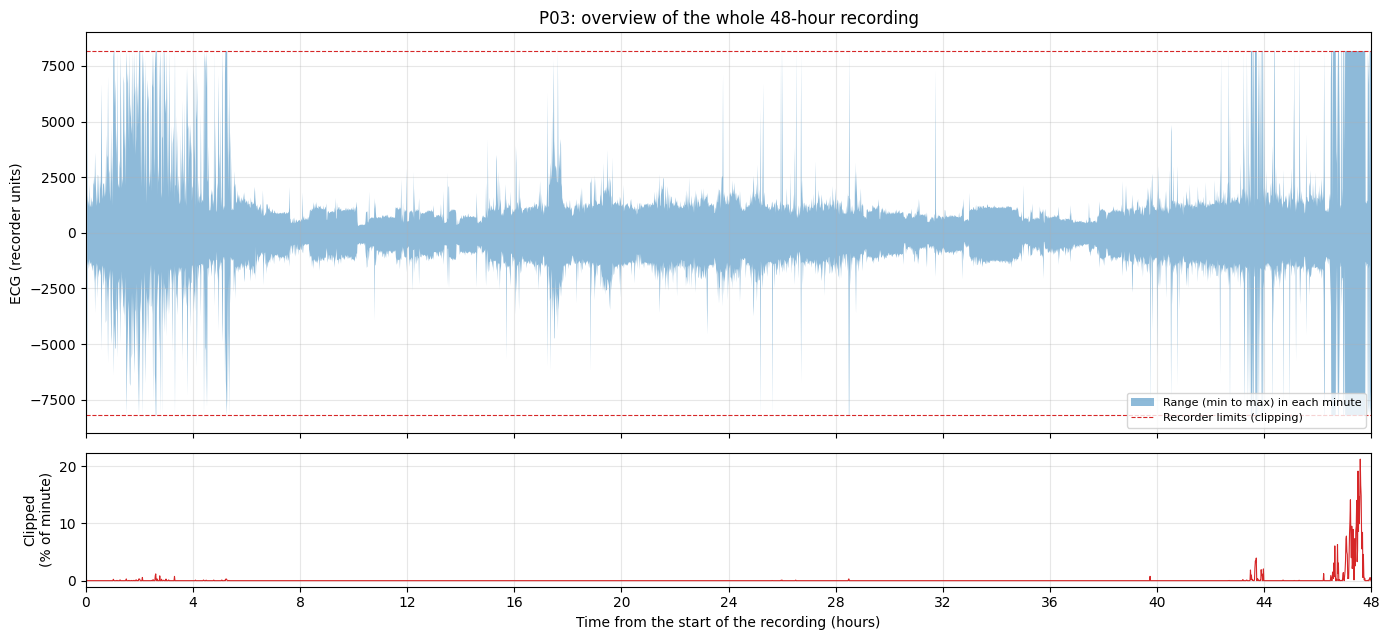

Minutes with any clipping: 5.5% of the record; minutes that are more than 10% clipped: 0.3%


In [30]:
x3, fs3 = load_ecg("P03_ecg.npz")
plot_overview(x3, fs3, "P03")

**P03 has a clean middle and noisy ends.** 5.5% of minutes contain some clipping, almost all of it in the last 2 hours (up to about 20% of a minute near hour 47.5). There is a lot of unclipped artifact in the first 5 hours and a burst around hour 17.5. The long narrow stretches around hours 8 to 14 and 30 to 38 are likely sleep.

## Part 1: Description of your filter

P03: Butterworth bandpass, order 4, filtfilt; detector alpha = 0.5, beta = 0.6
   Run  f_lo (Hz)  f_hi (Hz)  Error rate
     1          5         20       2.01%
     2          5         25       1.88%
     3          5         30       1.94%
     4          5         35       2.05%
     5          5         40       2.09%
     6          5         50       2.28%
     7          8         20       1.68%
     8          8         25       1.63%
     9          8         30       1.69%
    10          8         35       1.78%
    11          8         40       1.86%
    12          8         50       2.09%
    13         10         20       1.60%
    14         10         25       1.55%
    15         10         30       1.64%
    16         10         35       1.77%
    17         10         40       1.90%
    18         10         50       2.11%
    19         12         20       1.62%
    20         12         25       1.56%
    21         12         30       1.67%
    22         12  

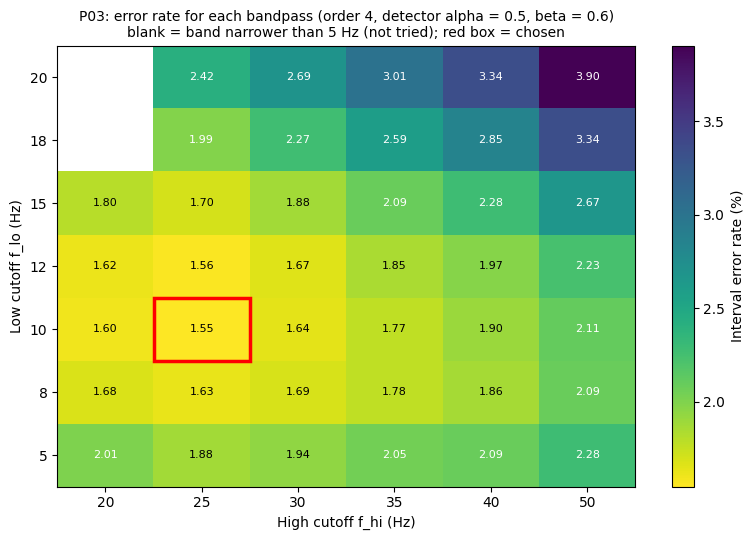

**P03: filter summary**

| Property | Value |
|---|---|
| Type | Butterworth bandpass (maximally flat passband: no ripple) |
| Order | 4 per edge (8 poles, 4 second-order sections) |
| Cutoff frequencies (one pass, -3 dB) | 10 Hz and 25 Hz |
| How it is applied | Forward and backward (`sosfiltfilt`): zero phase, magnitude response |H|² |
| Effective order after filtfilt | 8 per edge: 160 dB per decade on each side |
| -3 dB band after filtfilt | 10.48 to 23.93 Hz (slightly inside the design cutoffs) |
| Gain at the design cutoffs after filtfilt | -6.0 dB (one pass is -3 dB; twice is -6 dB) |
| Gain after filtfilt at 0.5 Hz (breathing and slow baseline wander) | below -200 dB |
| Gain after filtfilt at 2 Hz (typical movement artifact) | -145.3 dB |
| Gain after filtfilt at 5 Hz (T waves and slower movement) | -75.6 dB |
| Gain after filtfilt at 60 Hz (power-line hum) | -104.6 dB |
| Gain after filtfilt at 100 Hz (muscle (EMG) noise) | -190.1 dB |

In [31]:
tune3 = tune_filter(x3, fs3, "P03")
filt3 = design_filter(*tune3["best"], fs3, order=tune3["order"])
plot_filter_tuning(tune3, "P03")
describe_filter(filt3, "P03")

**A 4th-order Butterworth bandpass filter from 10 to 25 Hz, as second-order sections, applied forward and backward with `sosfiltfilt` (zero phase).** This band is the lowest of the three. The gain actually applied is −3 dB at 10.48 and 23.93 Hz and −6 dB at 10 and 25 Hz. It removes 5 Hz content by 76 dB, 2 Hz by 145 dB, and 60 Hz hum by 105 dB.

## Part 2: Description of how you designed your filter including the rationale for your design decisions and parameter values

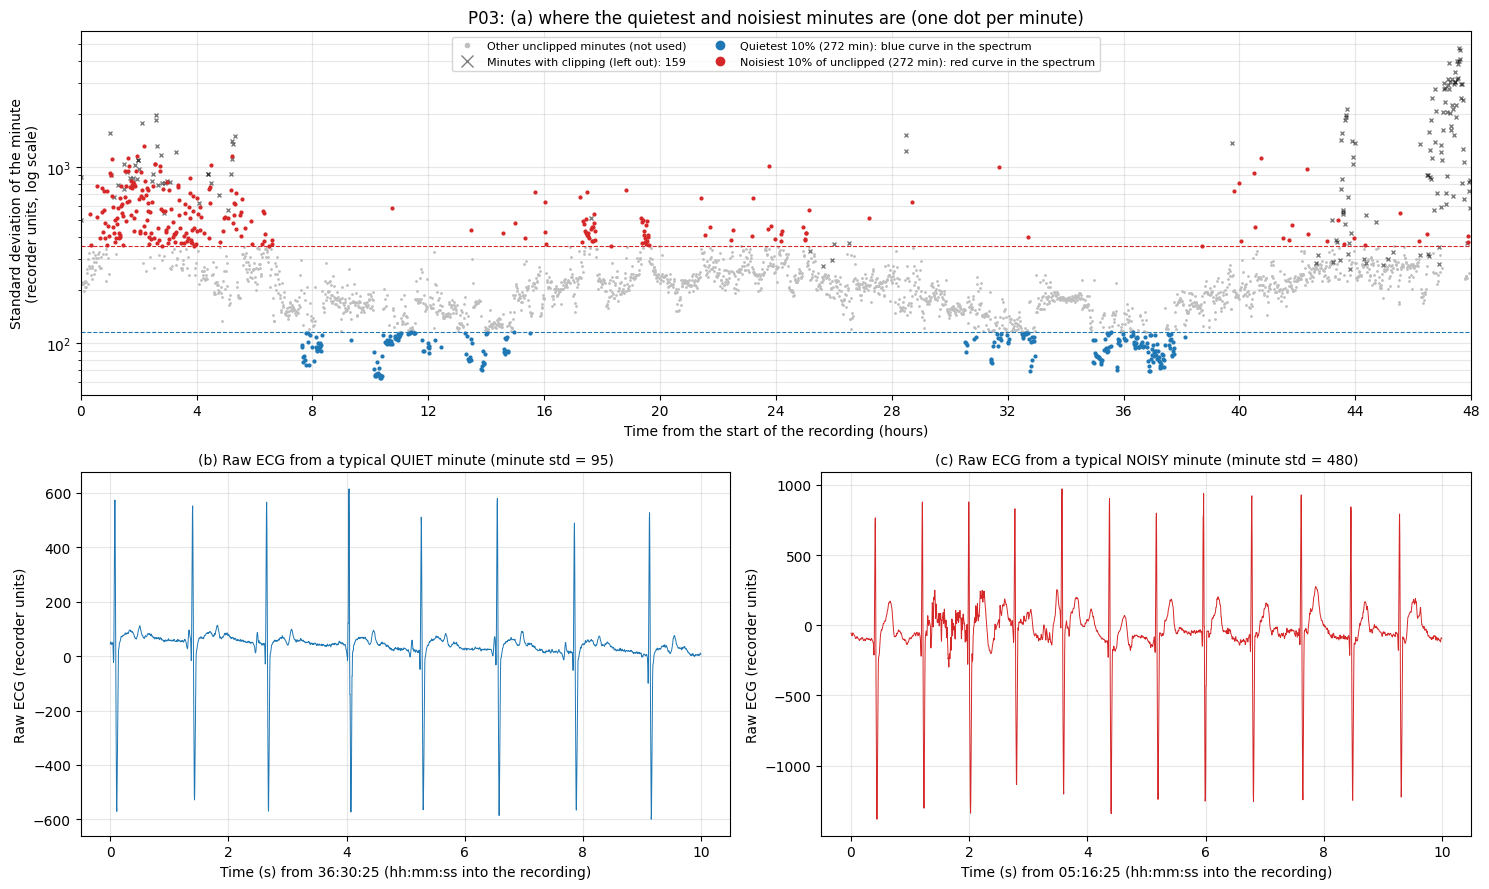

Quietest 10%: minute std from 63 to 115; hours holding the most of them: hour 10 (38 min), hour 32 (22 min), hour 35 (35 min), hour 36 (35 min), hour 37 (39 min)
Noisiest 10%: minute std from 356 to 1327; hours holding the most of them: hour 0 (16 min), hour 1 (46 min), hour 2 (40 min), hour 3 (37 min), hour 17 (21 min)


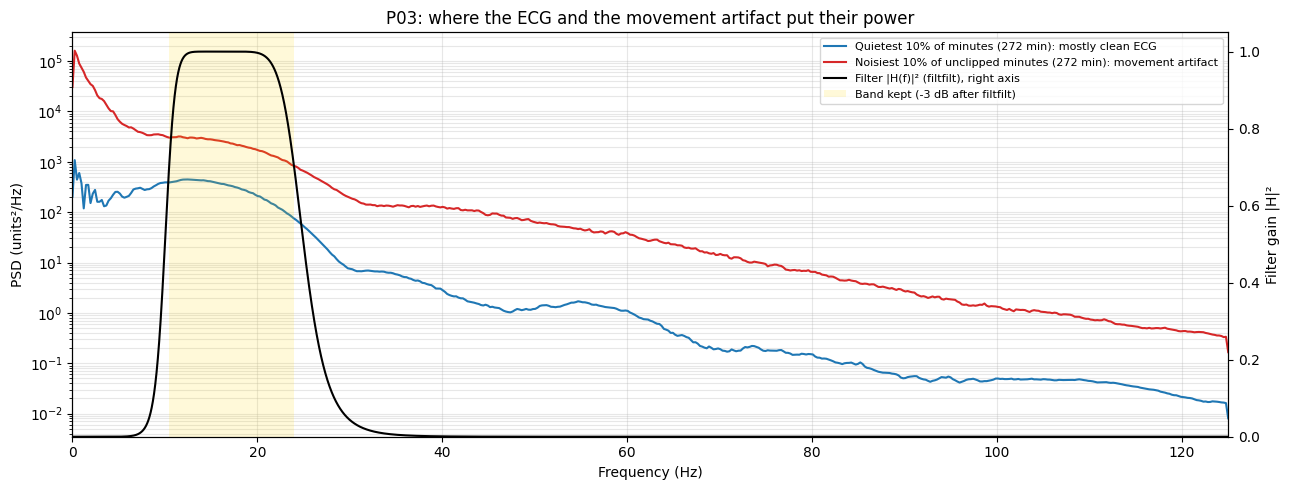

    1 Hz: noisy minutes have  22.9 dB more power than quiet minutes
    3 Hz: noisy minutes have  20.6 dB more power than quiet minutes
    5 Hz: noisy minutes have  14.4 dB more power than quiet minutes
   10 Hz: noisy minutes have   9.2 dB more power than quiet minutes
   15 Hz: noisy minutes have   8.3 dB more power than quiet minutes
   20 Hz: noisy minutes have   9.1 dB more power than quiet minutes
   30 Hz: noisy minutes have  14.1 dB more power than quiet minutes
   40 Hz: noisy minutes have  16.5 dB more power than quiet minutes


In [32]:
plot_minute_selection(x3, fs3, "P03")
plot_spectra(x3, fs3, filt3, "P03")

**10 to 25 Hz had the lowest error rate (1.55% with the default detector).** The best region of the heat map is the lower left: f_lo = 8 to 12 Hz with f_hi = 20 to 25 Hz all give 1.56 to 1.68%.

- **Low cutoff (10 Hz).** P03's T waves are small (Part 9), so the filter does not need to cut as high as for P01 and P02, and a lower f_lo keeps more of the QRS energy. Going above 12 Hz makes things worse (up to 2.4 to 3.9% at 20 Hz) because it starts removing the QRS.
- **High cutoff (25 Hz).** P03's artifact has a lot of high-frequency power: the noisy minutes have 14 to 17 dB more power than the quiet ones at 30 to 40 Hz (more than at 10 to 20 Hz, where the gap is 8 to 9 dB). Raising f_hi above 25 Hz lets that noise in, and the error rate rises to the right in every row.
- So P03's QRS energy sits lower in frequency than P01's, and its noise sits higher, which pushes the band down.

## Part 3: Plot of the impulse response of your filter

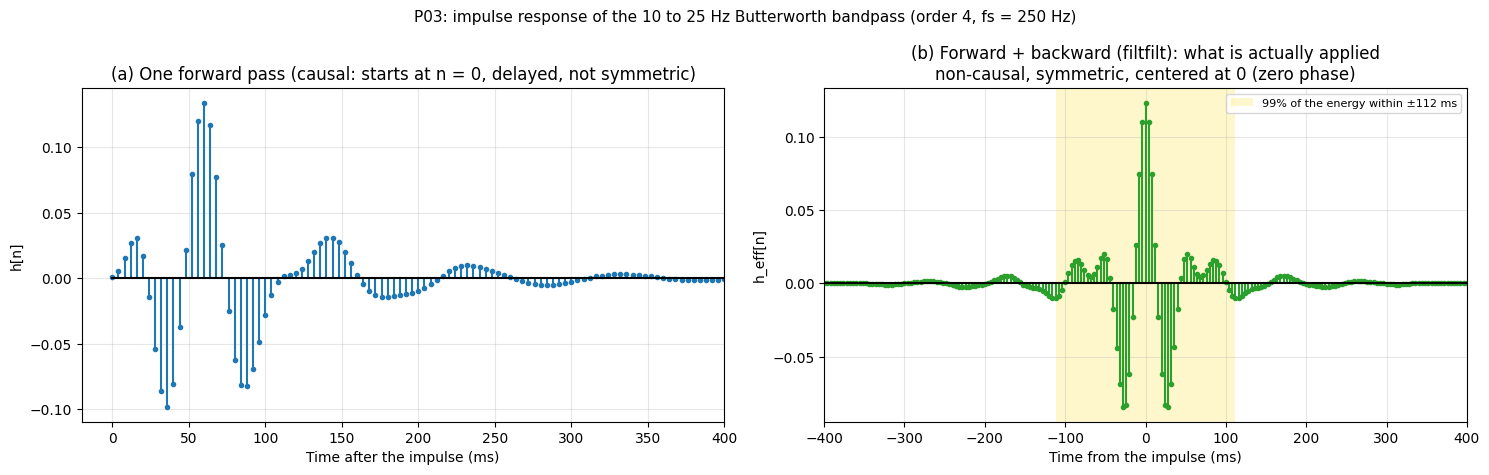

Peak of h_eff at n = 0 (zero delay). Symmetric: max |h_eff[n] - h_eff[-n]| = 6.7e-04. Sum of h_eff = 1.4e-03 (a bandpass has zero gain at 0 Hz, so its taps sum to 0).


In [33]:
plot_impulse(filt3, "P03")

**The effective impulse response is symmetric and centered at n = 0, with a slower oscillation than P01's** (about 18 Hz, near the band center), and 99% of its energy lies within ±112 ms. It is much longer than P01's (±48 ms) because its band is narrower, and it rings more slowly than P02's because its band is lower. The single forward pass (panel a) shows the delay that filtfilt cancels.

## Part 4: Plot of the magnitude response of your filter

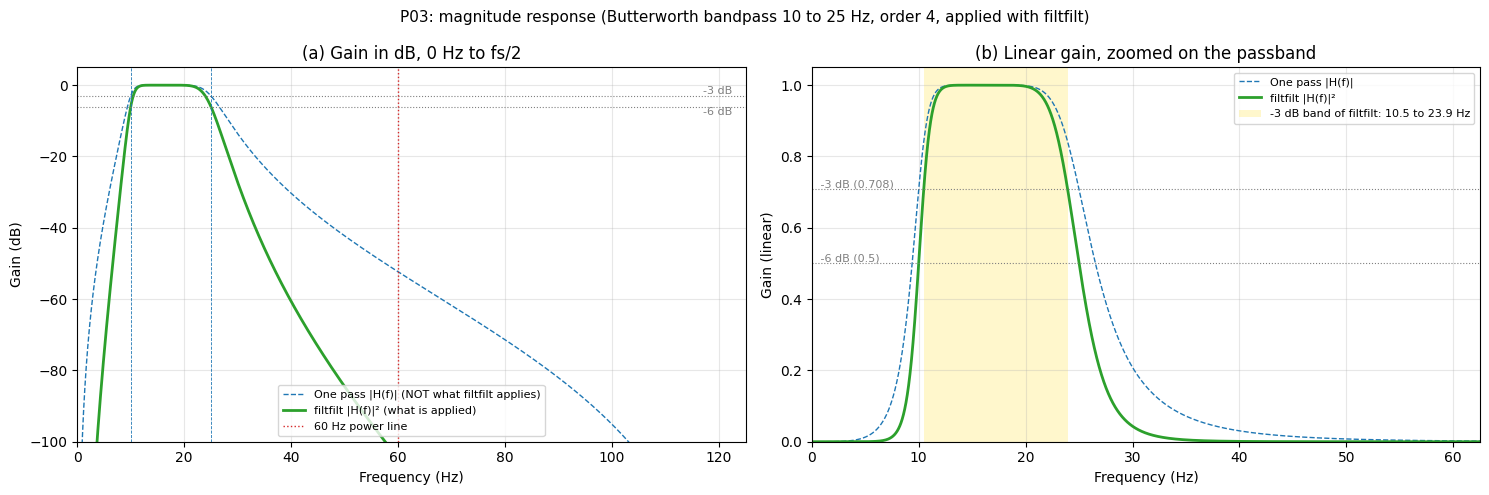

In [34]:
plot_magnitude(filt3, "P03")

**The applied response |H|² is flat from about 12 to 21 Hz, −3 dB at 10.48 and 23.93 Hz, and −6 dB at 10 and 25 Hz.** It is −76 dB at 5 Hz, −145 dB at 2 Hz, −105 dB at 60 Hz, and −190 dB at 100 Hz.

## Part 5: Description of the peak detection algorithm you used

In [35]:
y3 = apply_filter(filt3, x3)
dtune3 = tune_detector(y3, fs3, "P03")
det3 = detect_r_peaks(y3, fs3, alpha=dtune3["best"][0], beta=dtune3["best"][1])
print(f"Detected {len(det3['peaks']):,} R waves using alpha = {det3['alpha']}, beta = {det3['beta']}")

P03: tried 15 detector settings in 47 s. Best: alpha = 0.4, beta = 0.7, error rate 1.41%
Detected 187,924 R waves using alpha = 0.4, beta = 0.7


Same detector as Recording 1 (see Recording 1, Part 5); only alpha and beta are tuned for this recording.

**For P03 the detector uses alpha = 0.4 and beta = 0.7, and it found 187,924 R waves (an average of 65.3 per minute).**

## Part 6: Description of how you designed your peak detection algorithm including the rationale for your design decisions and parameter values

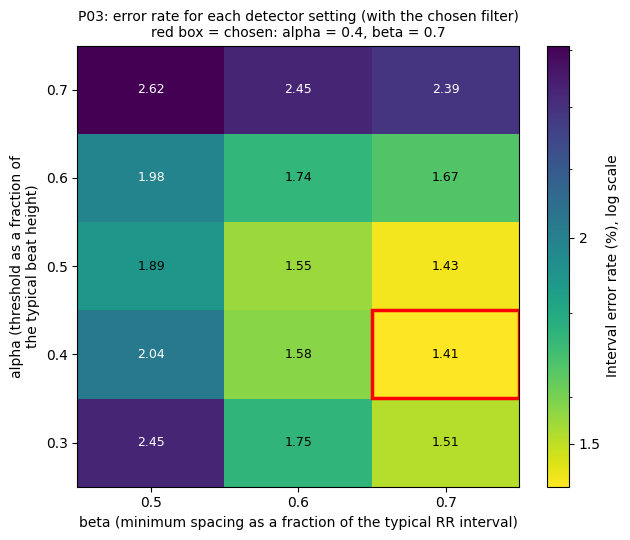

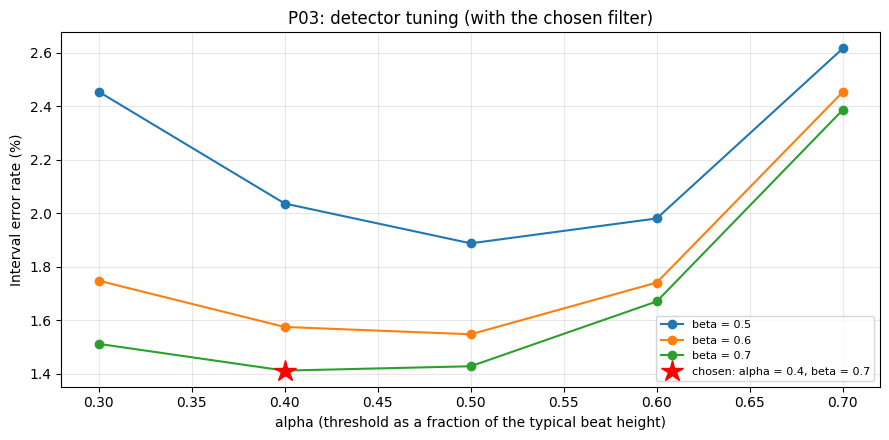

**P03: what each step contributes**

| Pipeline | Beats found | Interval error rate |
|---|---|---|
| Unfiltered ECG, simple detector (fixed 0.30 s refractory) | 201,364 | 11.74% |
| Filtered ECG, simple detector (fixed 0.30 s refractory) | 190,620 | 2.92% |
| Filtered ECG, full detector (spacing follows the rhythm) | 187,924 | 1.41% |

In [36]:
plot_detector_heatmap(dtune3, "P03")
plot_detector_tuning(dtune3, "P03")
compare_steps(x3, y3, fs3, det3, "P03")

**alpha = 0.4 and beta = 0.7 gave the lowest error rate (1.41%).** alpha = 0.4 and 0.5 are almost tied (1.42% and 1.43% with beta = 0.7); 0.3 lets in noise and 0.7 misses smaller beats. beta = 0.7 is clearly best: with beta = 0.5 the error rate is 1.9 to 2.6%.

**What each step contributes:** 11.73% on the unfiltered ECG, 2.92% after filtering, 1.41% with the full detector. For P03 the spacing rule halves the error rate after filtering. With the lower 10 Hz cutoff, more of the T wave passes the filter, and the rule removes the T waves and noise spikes that follow a beat too soon.

## Part 7: Reported rate of misdetection, as described above

**P03: misdetection rate**

| Quantity | Value |
|---|---|
| Beats detected | 187,924 (average 65.3 per minute) |
| Intervals checked | 187,923 |
| Intervals flagged as errors | 2,654 |
| **Misdetection (interval error) rate** | **1.41%** |
| Intervals that contain clipped samples | 1,588 (0.85% of intervals) |
| Error rate in intervals with clipping | 47.5% |
| Error rate in intervals without clipping | 1.02% |
| Errors caused only by the 0.5 s floor (see note below) | 106 (4% of the errors; 0.06 percentage points of the rate) |

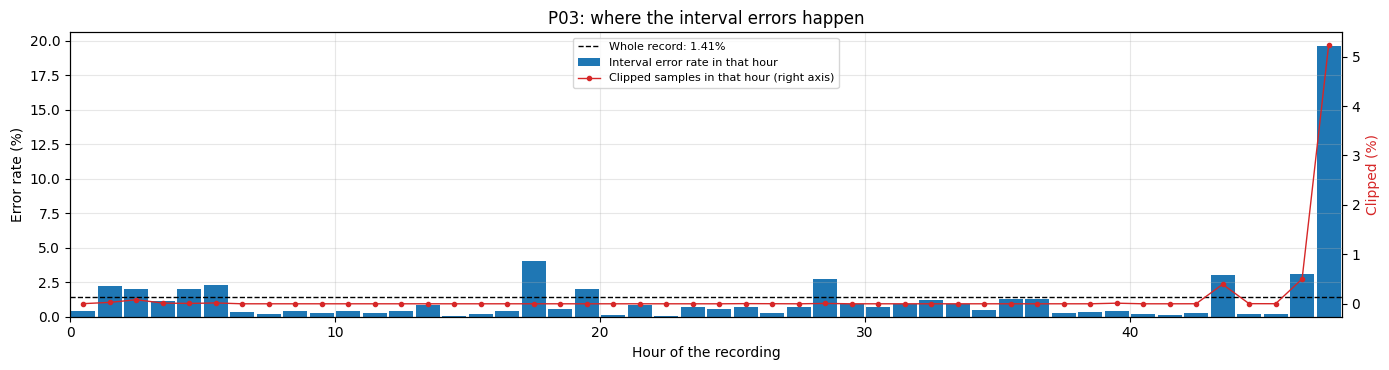

Note: the criterion raises the median interval to at least 0.5 s. When the heart really beats faster than about 160 bpm, correct detections can still be flagged. The row above counts intervals that are within 25% of their own median but are flagged only because of this floor.
The 4 hours with the most errors (hours 17, 43, 46, 47) hold 52% of all the error intervals.


In [37]:
ie3 = report_error(det3, x3, fs3, "P03")

**Misdetection rate for P03: 1.41%** (2,654 of 187,923 intervals flagged), the lowest of the three recordings.

- 0.85% of the intervals contain clipped samples, and 47.5% of those are errors. Without clipping the rate is **1.02%**.
- The 4 worst hours (17, 43, 46, 47) hold 52% of the errors. Hours 43, 46, and 47 are the clipping at the end of the recording; hour 17 is the artifact burst seen in the overview, which comes with a bout of fast heart rate.
- 106 errors (4% of them, 0.06 percentage points) are flagged only because of the 0.5 s floor: P03 has short bouts of 160+ bpm around hours 17.5 and 19.5 (see the segment after Part 10).

## Part 8: Plot of the RR intervals and median filtered RR intervals

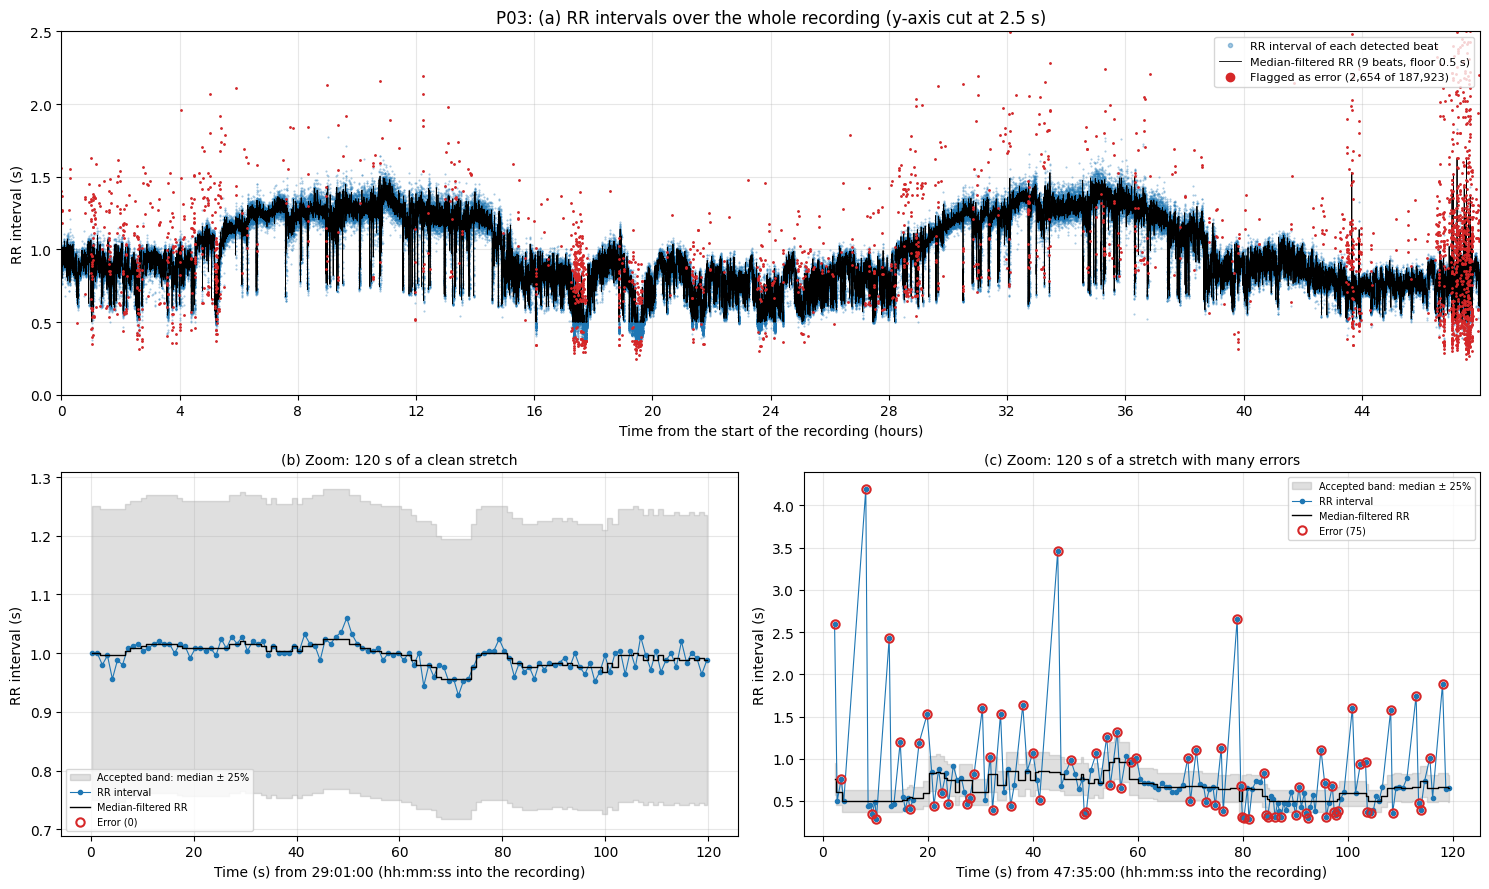

Heart rate from the median-filtered RR: median 69 bpm, 5th to 95th percentile 46 to 107 bpm


In [38]:
plot_rr(ie3, "P03")

**P03's rhythm shows two clear day and night cycles:** the median-filtered RR is about 0.8 to 1.0 s (60 to 75 bpm) during the day and rises to 1.2 to 1.5 s (40 to 50 bpm) at night (about hours 6 to 14 and 29 to 38). The short dips to 0.4 to 0.5 s around hours 17.5 and 19.5 are bouts of fast heart rate (probably exercise). The red dots concentrate in the first 5 hours and the last 2 hours (artifact and clipping); panel (c) shows the last hours, where the clipped signal produces detections at random spacing.

## Part 9: Plot of the original and filtered ECG signal over a 10 second segment without movement artifact

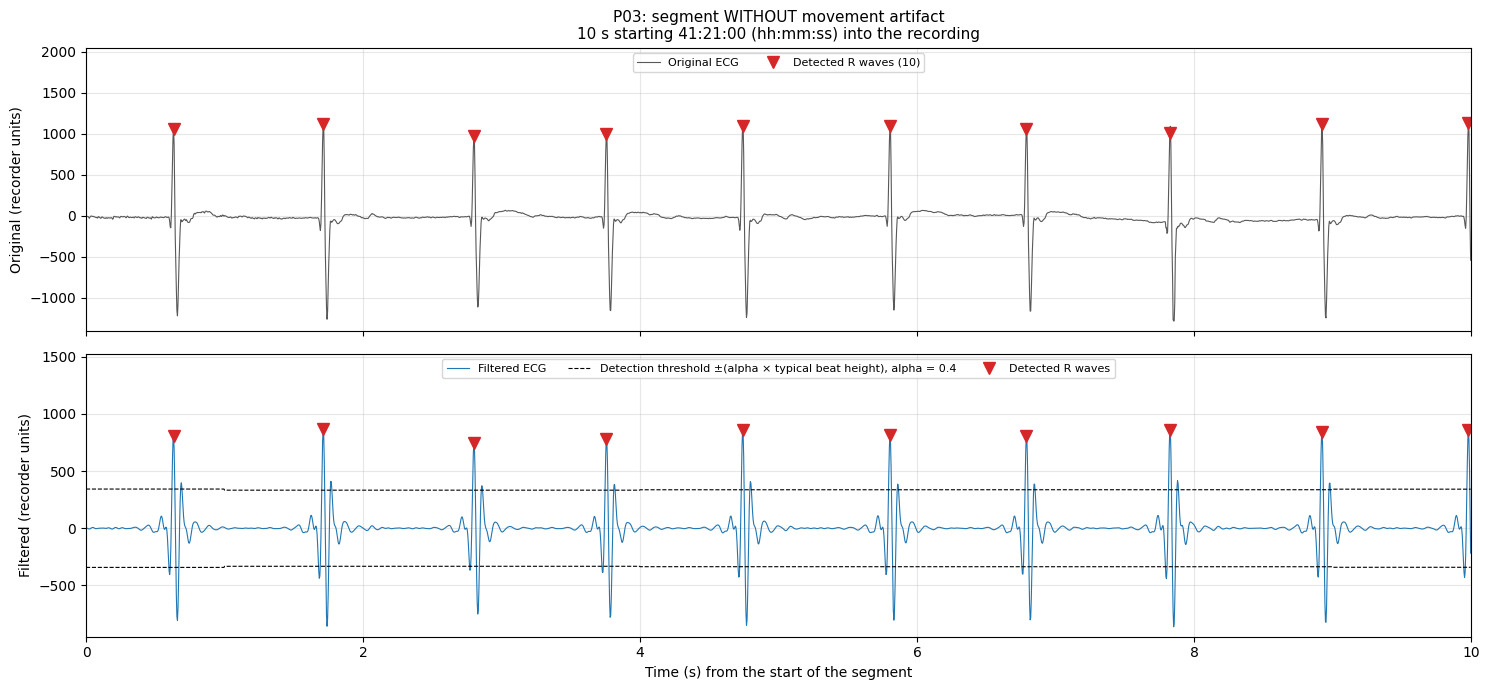

RR intervals in this segment: [1.08 1.09 0.96 0.98 1.06 0.98 1.04 1.1  1.06] s; interval errors here: 0


In [39]:
seg3 = segment_table(x3, y3, fs3, det3, ie3)
plot_segment(x3, y3, fs3, det3, ie3, pick_segment(seg3, ie3, "clean"), "P03", "segment WITHOUT movement artifact")

**All 10 R waves in this quiet segment (41:21:00) are found, with RR 0.96 to 1.10 s and no errors.** P03's ECG here has a clear R wave, a deep S wave, and very small T waves. After the 10 to 25 Hz filter, each QRS becomes a short burst whose largest positive peak marks the R wave, far above the threshold.

## Part 10: Plot of the original and filtered ECG signal over a 10 second segment with large movement artifact

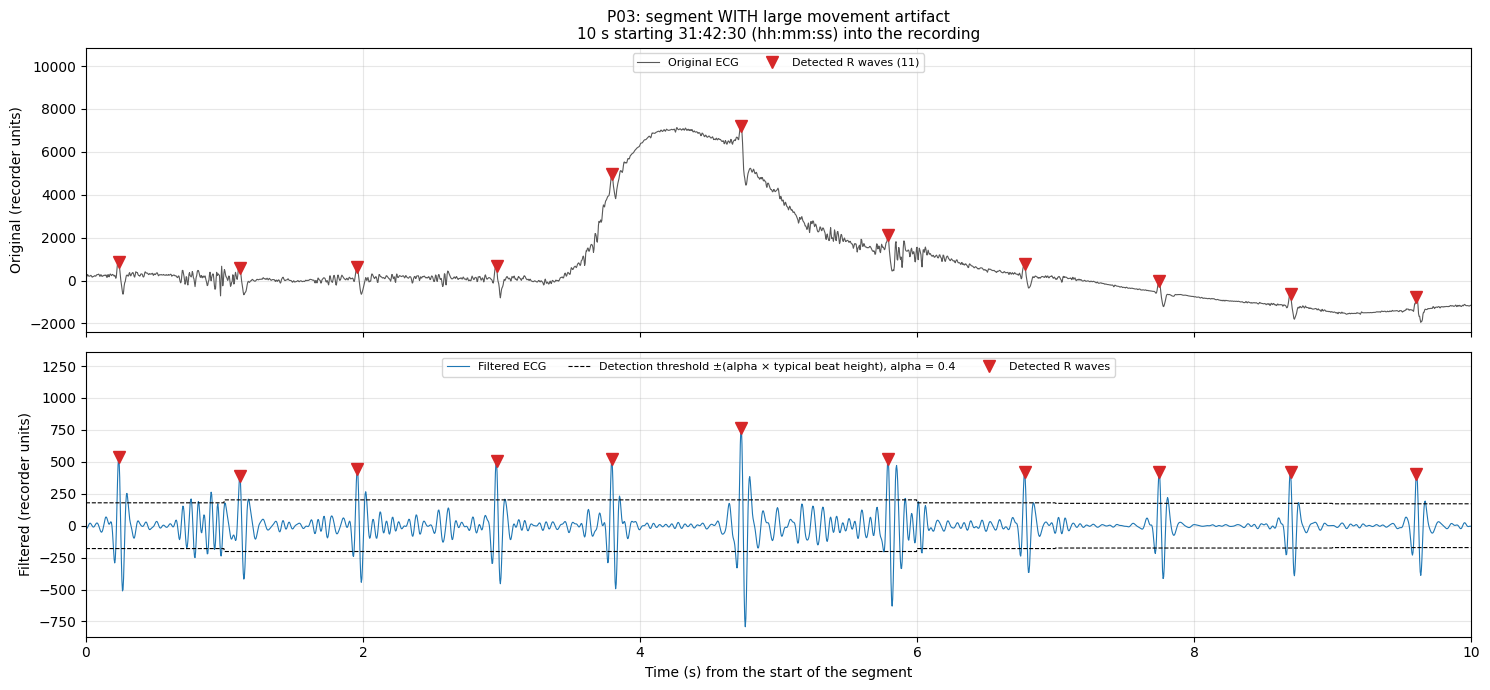

RR intervals in this segment: [0.88 0.85 1.   0.83 0.94 1.06 0.98 0.97 0.95 0.91] s; interval errors here: 0


In [40]:
plot_segment(x3, y3, fs3, det3, ie3, pick_segment(seg3, ie3, "artifact"), "P03", "segment WITH large movement artifact")

**In this segment (31:42:30) a movement lifts the baseline by about 7,000 units in about one second, roughly 7 times the QRS height, and all 11 R waves are still found with no interval errors** (RR 0.83 to 1.06 s). There is also some muscle noise in the first 2 seconds and around 5 to 6 s. In the filtered signal the swing is gone, the muscle noise stays below the threshold, and the QRS peaks stand out clearly.

### For comparison: the segment with the most flagged interval errors

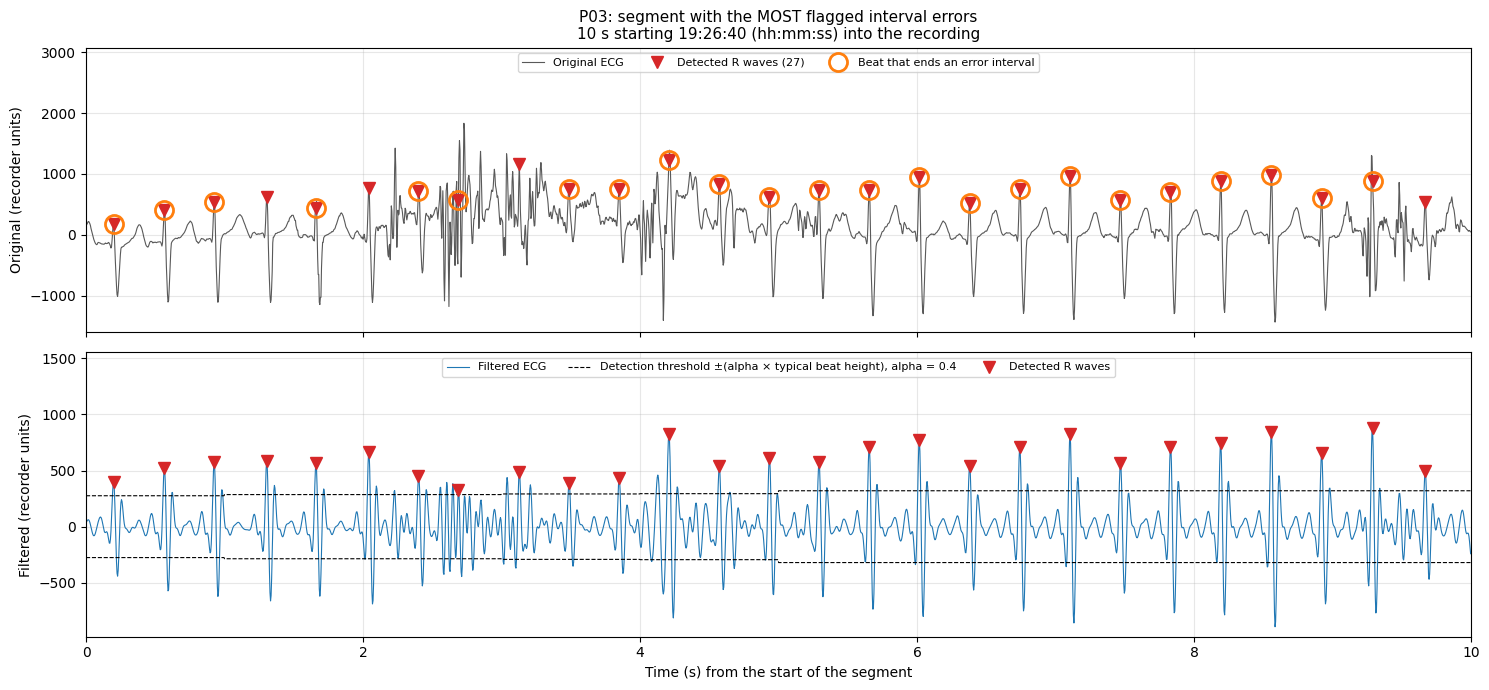

RR intervals in this segment: [0.36 0.36 0.38 0.36 0.38 0.36 0.29 0.44 0.36 0.36 0.36 0.36 0.36 0.36
 0.36 0.36 0.36 0.36 0.36 0.36 0.36 0.36 0.36 0.36 0.37 0.38] s; interval errors here: 23


In [41]:
plot_segment(x3, y3, fs3, det3, ie3, pick_segment(seg3, ie3, "failure"), "P03", "segment with the MOST flagged interval errors")

**As in P02, the segment with the most flagged errors is mostly correct detection at a fast heart rate.** At 19:26:40 the heart beats at about 165 bpm (RR about 0.36 s): the original ECG shows a clear QRS at almost every mark and the intervals are very even, but they are just below the criterion's 0.375 s limit. There is a burst of muscle noise between about 2 and 3.5 s, where one or two intervals are probably real mistakes. The criterion cannot tell these two situations apart.

# Summary of the three recordings

In [42]:
rows = []
for name, x, fs, filt, det, ie in [("P01", x1, fs1, filt1, det1, ie1), ("P02", x2, fs2, filt2, det2, ie2),
                                   ("P03", x3, fs3, filt3, det3, ie3)]:
    lo3, hi3 = minus3db_edges(filt)
    clip = clipped_intervals(det["peaks"], x)
    rows.append(f"| {name} | {filt['f_lo']:g} to {filt['f_hi']:g} Hz (-3 dB after filtfilt: {lo3:.1f} to {hi3:.1f} Hz) | "
                f"{det['alpha']} | {det['beta']} | {len(det['peaks']):,} | {np.median(60 / ie['ibi_mf']):.0f} bpm | "
                f"**{100 * get_ibi_filter_error(det['peaks'], fs):.2f}%** | {100 * ie['is_err'][~clip].mean():.2f}% |")
display(Markdown("| Recording | Bandpass (order 4, filtfilt) | alpha | beta | Beats | Median HR | Error rate | Error rate without clipping |\n"
                 "|---|---|---|---|---|---|---|---|\n" + "\n".join(rows)))

| Recording | Bandpass (order 4, filtfilt) | alpha | beta | Beats | Median HR | Error rate | Error rate without clipping |
|---|---|---|---|---|---|---|---|
| P01 | 15 to 50 Hz (-3 dB after filtfilt: 15.9 to 47.7 Hz) | 0.6 | 0.7 | 161,155 | 57 bpm | **2.14%** | 1.59% |
| P02 | 18 to 30 Hz (-3 dB after filtfilt: 18.5 to 29.2 Hz) | 0.4 | 0.7 | 246,798 | 90 bpm | **2.28%** | 2.23% |
| P03 | 10 to 25 Hz (-3 dB after filtfilt: 10.5 to 23.9 Hz) | 0.4 | 0.7 | 187,924 | 69 bpm | **1.41%** | 1.02% |

**All three recordings end up with an interval error rate of 1.4 to 2.3%**, using a separate bandpass and detector setting for each. The filters differ because the people differ: P01's sharp QRS needs a wide band up to 50 Hz, P02's large T waves and high-frequency noise squeeze its band to 18 to 30 Hz, and P03's lower-frequency QRS and high-frequency noise push its band down to 10 to 25 Hz. In every case most of the remaining errors are in stretches where the recorder was clipping, or (for P02) are correct detections at heart rates above about 160 bpm that the criterion's 0.5 s floor counts as errors.

## Part 31: What, if anything, did you learn from this homework?

### Core ideas covered in this assignment

- **Separating signal from artifact by frequency.** Movement artifact and baseline wander are slow, the QRS complex is fast, so a bandpass filter removes most of the artifact. On the unfiltered ECG the same detector had 12 to 36% errors; after filtering, 2.6 to 4.9%.
- **The best band depends on the person.** The three recordings needed noticeably different bands (15 to 50 Hz, 18 to 30 Hz, 10 to 25 Hz), and the spectra of quiet versus noisy minutes explained why: where each person's QRS energy is and where their noise is.
- **Second-order sections.** A narrow IIR bandpass is safer to implement as a cascade of biquads than as one high-order polynomial.
- **Letting a criterion choose the parameters.** A grid search over the full 48 hours replaced guessing. The error surface was flat near the optimum, so the results are not sensitive to the exact values.
- **Adaptive thresholds.** Over two days the QRS height changes a lot, so the threshold has to follow the recent beats instead of being fixed.
- **Using physiology as a detection rule.** Requiring a new beat to come at least 70% of the recent RR interval after the last one removed T waves and noise without blocking real fast heart rates, which a fixed refractory period cannot do. It cut the remaining errors by up to half.
- **Evaluating without ground truth, and the limits of the metric.** The interval criterion is a clever substitute for an answer key, but it counts correct detections at heart rates above about 160 bpm as errors (half of P02's "errors"), it would accept a detector that locks onto regular noise, and it cannot rescue clipped stretches, where the information is simply gone.
- **Working with large data.** 43.2 million samples per recording means every step has to be vectorized; a Python loop over samples would be far too slow.

## Part 32: What new questions, if any, do you have?

- The 0.5 s floor flagged half of P02's errors at real heart rates of 160 to 190 bpm. Would a lower floor (for example 0.3 s) still protect against bursts of false detections, or is there a better way to set it?
- Should clipped stretches be excluded and reported as "unreadable", as some clinical software does, and if so, how should that be scored fairly?
- How do real-time (causal) detectors, such as Pan-Tompkins in a pacemaker or a wearable, cope without the backward pass of filtfilt?

## References

[1] Nurse Sarah, "ECG Waveform," *Digital Nursing Notes*, RegisteredNurseRN. [Online]. Available: https://shop.registerednursern.com (accessed Nov. 24, 2026).

[2] M. Elgendi, M. Jonkman, and F. DeBoer, "Frequency bands effects on QRS detection," in *Proc. 3rd Int. Conf. Bio-inspired Systems and Signal Processing (BIOSIGNALS 2010)*, SciTePress, 2010, pp. 428–431, doi: 10.5220/0002742704280431.

[3] N. V. Thakor, J. G. Webster, and W. J. Tompkins, "Estimation of QRS complex power spectra for design of a QRS filter," *IEEE Trans. Biomed. Eng.*, vol. BME-31, no. 11, pp. 702–706, Nov. 1984, doi: 10.1109/TBME.1984.325393.

[4] J. Pan and W. J. Tompkins, "A real-time QRS detection algorithm," *IEEE Trans. Biomed. Eng.*, vol. BME-32, no. 3, pp. 230–236, Mar. 1985, doi: 10.1109/TBME.1985.325532.

[5] J. Malik, E. Z. Soliman, and H.-T. Wu, "An adaptive QRS detection algorithm for ultra-long-term ECG recordings," arXiv:2002.10633, 2020. [Online]. Available: https://arxiv.org/abs/2002.10633

[6] Q. Fleury, R. Dubois, S. Christophle-Boulard, F. Extramiana, and P. Maison-Blanche, "Noise Holter Database: a multi-device, multi-arrhythmia real-world clinical ECG signal quality benchmark," version 1.0.0, PhysioNet, 2026. [Online]. Available: https://physionet.org/content/noise-holter-database/1.0.0/